# UE Data Mining - Projet

Rapport du projet de l'UE Data Mining — année universitaire 2026–2027.

Équipe : Flavien, Leticia, Sarah, Marie, Arthur et Cheikh.

Analyse Ecology : Flavien. Les jeux de données et les personnes du récit sont fictifs.


# Analyse des données Ecology

Nous cherchons à comprendre les observations écologiques et à identifier
les évolutions ou événements qui nécessitent une investigation.

L'analyse commence par la structure et la qualité des six fichiers.
Les rapprochements avec les autres domaines seront ensuite examinés
à partir des identifiants, des lieux et des dates disponibles.

**Organisation.** Nous suivons l'ordre des cours : préparation et exploration
des fichiers, puis comparaisons, anomalies, réseaux, évolutions temporelles
et analyse textuelle lorsque ces approches répondent à une question utile.

**Usage de l'IA générative.** Une assistance a été utilisée pour proposer
et corriger du code, exécuter les calculs, rechercher des discordances
et rédiger les commentaires. Les traitements sont reproductibles ; cette
assistance ne valide pas indépendamment les affirmations des documents.

## Cours 1 — Préparation et exploration des données

### 1. Sites de suivi — `monitoring_sites.csv`

Ce fichier décrit les sites de surveillance écologique.
Une ligne représente un site, identifié par `site_code`.

Nous vérifions les dimensions, les types de variables, les valeurs
manquantes et l'unicité des identifiants. Cette table servira de référence
pour mettre en contexte les relevés et les rapports.

In [1]:
import pandas as pd

# Conservation du tableau brut pour pouvoir vérifier les transformations.
df_sites_brut = pd.read_csv(
    "data/ecology/monitoring_sites.csv"
)

print("Dimensions :", df_sites_brut.shape)

print(
    "Lignes entièrement dupliquées :",
    df_sites_brut.duplicated().sum()
)

print(
    "Codes de site dupliqués :",
    df_sites_brut["site_code"].duplicated().sum()
)

bilan_sites = pd.DataFrame({
    "type_pandas": df_sites_brut.dtypes.astype(str),
    "valeurs_manquantes": df_sites_brut.isna().sum(),
    "valeurs_distinctes": df_sites_brut.nunique()
})

print("\nStructure des variables :")
display(bilan_sites)

print("\nAperçu des sites :")
display(df_sites_brut.head())

Dimensions : (64, 14)
Lignes entièrement dupliquées : 0
Codes de site dupliqués : 0

Structure des variables :

Aperçu des sites :


,type_pandas,valeurs_manquantes,valeurs_distinctes
site_code,str,0,64
site_name,str,0,64
site_category,str,0,4
region,str,0,3
jurisdiction,str,0,3
latitude,float64,0,64
longitude,float64,0,64
elevation_m,float64,1,57
habitat_category,str,0,8
cave_access_category,str,0,2


,site_code,site_name,site_category,region,jurisdiction,latitude,longitude,elevation_m,habitat_category,cave_access_category,orchard_context,programme_start_date,programme_end_date,site_status
0,KNT-KES,Kestrel Cavern Monitoring Site,cave monitoring,Kintara Karst Cluster,Kintara Republic,4.68,112.31,248.0,karst_habitat,managed,none recorded,2016-01-01,NaN,active
1,KNT-LUM,Luma Karst Reserve Site,cave monitoring,Kintara Karst Cluster,Kintara Republic,4.81,112.44,25.0,karst_habitat,managed,none recorded,2016-01-01,NaN,active
2,KNT-SEN,Senna Ridge Cave Site,cave monitoring,Kintara Karst Cluster,Kintara Republic,4.59,112.50,45.0,karst_habitat,managed,none recorded,2016-01-01,NaN,active
3,AVL-MAR,Marula East Orchard Site,orchard monitoring,Eastern Avelora Agricultural Cluster,Avelora Federation,7.41,101.69,226.0,durian_orchard,not applicable,commercial or research orchard,2016-01-01,NaN,active
4,AVL-VEL,Velin Basin Orchard Site,orchard monitoring,Eastern Avelora Agricultural Cluster,Avelora Federation,7.55,101.84,24.0,durian_orchard,not applicable,commercial or research orchard,2016-01-01,NaN,active


### Première lecture de la qualité des données

Le fichier contient 64 sites et 14 variables. Les codes `site_code`
sont tous renseignés et uniques. Ils peuvent donc servir de clé
pour rattacher les relevés aux sites, sous réserve de vérifier
les correspondances lors des jointures.

**Altitude manquante.** Un seul site ne possède pas d'altitude.
Supprimer ce site ferait perdre ses autres informations et pourrait
l'exclure inutilement des analyses. Remplacer son altitude par la
moyenne ou la médiane des autres sites serait possible techniquement,
mais supposerait que ces sites constituent une référence pertinente,
malgré leurs différences géographiques et d'habitat.

Comme cette valeur n'est pas indispensable aux analyses prévues,
nous conservons le site et laissons son altitude manquante.
Les statistiques portant sur l'altitude sont calculées sur
les 63 valeurs renseignées.

**Dates de fin absentes.** Aucune date de fin de programme n'est
renseignée. Une imputation par la moyenne, la médiane ou la date
la plus fréquente est donc impossible : nous ne disposons
d'aucune date de fin observée pour les calculer.

Attribuer une date arbitraire, comme la dernière date du jeu de données,
créerait une fermeture de programme non documentée et fausserait
le calcul des durées. Nous conservons donc ces absences.
Elles sont compatibles avec le statut `active` des sites, sans
permettre de savoir quand les programmes prendront fin.
Nous pouvons étudier leurs dates de début et la période de suivi
observée, mais pas leur durée complète.

**Statut des sites.** `site_status` ne possède qu'une modalité.
Cette variable apporte du contexte, mais ne permet pas de distinguer
les sites ; elle n'entre donc pas dans le profil de regroupement.

Enfin, les dates sont encore stockées comme du texte.
Nous vérifierons leurs formats avant conversion et examinerons
les catégories avant de les harmoniser, afin de ne pas fusionner
des modalités réellement différentes.


In [2]:
colonnes_categories_sites = [
    "site_category",
    "habitat_category",
    "cave_access_category",
    "orchard_context"
]

for colonne in colonnes_categories_sites:
    print(f"\nRépartition de {colonne} :")

    display(
        df_sites_brut[colonne]
        .value_counts(dropna=False)
        .rename_axis(colonne)
        .to_frame("nombre_sites")
    )


Répartition de site_category :

Répartition de habitat_category :

Répartition de cave_access_category :

Répartition de orchard_context :


,nombre_sites
site_category,
habitat monitoring,40
orchard monitoring,15
cave monitoring,8
ORCHARD MONITORING,1


,nombre_sites
habitat_category,
mixed_forest,19
durian_orchard,10
coastal_habitat,10
karst_habitat,9
research_site,6
mixed_agriculture,5
protected_forest,3
degraded_land,2


,nombre_sites
cave_access_category,
not applicable,56
managed,8


,nombre_sites
orchard_context,
none recorded,48
commercial or research orchard,16


### Harmonisation des catégories

`ORCHARD MONITORING` est une variante de `orchard monitoring`. Nous harmonisons
la casse et les espaces des quatre variables examinées, sans fusionner les
catégories de sens différent.

`not applicable` et `none recorded` restent distincts des valeurs manquantes.
`none recorded` indique qu'aucun contexte de verger n'est renseigné, sans
démontrer son absence sur le terrain. Les codes de site restent inchangés
pour préserver les jointures.


In [3]:
# Copie de travail : les données brutes restent disponibles.
df_sites = df_sites_brut.copy()

for colonne in colonnes_categories_sites:
    df_sites[colonne] = (
        df_sites[colonne]
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
        .str.lower()
    )

print("Catégories de sites après harmonisation :")

display(
    df_sites["site_category"]
    .value_counts(dropna=False)
    .rename_axis("site_category")
    .to_frame("nombre_sites")
)

print("Nombre de sites conservés :", len(df_sites))
print(
    "Codes de site inchangés :",
    df_sites["site_code"].equals(df_sites_brut["site_code"])
)

Catégories de sites après harmonisation :
Nombre de sites conservés : 64
Codes de site inchangés : True


,nombre_sites
site_category,
habitat monitoring,40
orchard monitoring,16
cave monitoring,8


### Conversion et contrôle des dates

Les dates de début et de fin des programmes ont été converties
en variables temporelles sans erreur.

Les programmes commencent en 2016 pour 27 sites, en 2017 pour
16 sites et en 2018 pour 21 sites.

Les dates de fin sont absentes pour les 64 sites et restent
manquantes (`NaT`). Aucun remplacement n'est effectué, car les
sources ne permettent pas d'attribuer une date de fin fiable.

Aucune date de fin antérieure au début n'est détectée. Toutefois,
en l'absence de dates de fin renseignées, ce contrôle ne permet
pas de valider leur cohérence chronologique ni de calculer les
durées complètes des programmes.

In [4]:
colonnes_dates_sites = [
    "programme_start_date",
    "programme_end_date"
]

for colonne in colonnes_dates_sites:
    df_sites[colonne] = pd.to_datetime(
        df_sites[colonne],
        format="mixed",
        errors="raise"
    )

print("Types après conversion :")
display(
    df_sites[colonnes_dates_sites]
    .dtypes.astype(str)
    .to_frame("type_pandas")
)

print("Répartition des dates de début :")
display(
    df_sites["programme_start_date"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("nombre_sites")
)

print(
    "Nombre de dates de fin renseignées :",
    df_sites["programme_end_date"].notna().sum()
)

dates_incoherentes_sites = (
    df_sites["programme_end_date"].notna()
    & (
        df_sites["programme_end_date"]
        < df_sites["programme_start_date"]
    )
)

print(
    "Dates de fin antérieures au début :",
    dates_incoherentes_sites.sum()
)

Types après conversion :
Répartition des dates de début :
Nombre de dates de fin renseignées : 0
Dates de fin antérieures au début : 0


,type_pandas
programme_start_date,datetime64[us]
programme_end_date,datetime64[s]


,nombre_sites
programme_start_date,
2016-01-01,27
2017-01-01,16
2018-01-01,21


### Vérification des coordonnées et de l'altitude

Nous contrôlons que les latitudes sont comprises entre -90 et 90 degrés,
et les longitudes entre -180 et 180 degrés.

Ces bornes permettent de détecter des coordonnées impossibles,
mais ne suffisent pas à confirmer la localisation exacte des sites.

Nous examinons également les valeurs extrêmes des trois variables
géographiques et identifions le site dont l'altitude est manquante.
Cette absence est conservée.

In [5]:
latitude_invalide = (
    df_sites["latitude"].notna()
    & ~df_sites["latitude"].between(-90, 90)
)

longitude_invalide = (
    df_sites["longitude"].notna()
    & ~df_sites["longitude"].between(-180, 180)
)

print("Latitudes hors des bornes :", latitude_invalide.sum())
print("Longitudes hors des bornes :", longitude_invalide.sum())

print("\nValeurs minimales et maximales :")
display(
    df_sites[
        ["latitude", "longitude", "elevation_m"]
    ]
    .agg(["min", "max"])
    .T
)

print("\nSites présentant des coordonnées hors des bornes :")
display(
    df_sites.loc[
        latitude_invalide | longitude_invalide,
        ["site_code", "site_name", "latitude", "longitude"]
    ]
)

print("\nSite dont l'altitude est manquante :")
display(
    df_sites.loc[
        df_sites["elevation_m"].isna(),
        ["site_code", "site_name", "region", "habitat_category"]
    ]
)

Latitudes hors des bornes : 0
Longitudes hors des bornes : 0

Valeurs minimales et maximales :

Sites présentant des coordonnées hors des bornes :

Site dont l'altitude est manquante :


,min,max
latitude,1.7668,7.7568
longitude,101.3263,112.6905
elevation_m,5.0000,418.8000


,site_code,site_name,latitude,longitude


,site_code,site_name,region,habitat_category
8,KNT-CYP,Dune Reach Monitoring Site,Kintara Karst Cluster,karst_habitat


### Résultat du contrôle géographique

Aucune latitude ni longitude ne dépasse les bornes géographiques
possibles. Ce contrôle ne confirme toutefois pas l'exactitude des
localisations.

Les altitudes renseignées s'étendent de 5 à 418,8 mètres.
L'altitude du site KNT-CYP, situé dans la région Kintara Karst Cluster,
est manquante. Ce site est conservé pour les autres analyses.

### Répartition des sites par région et habitat

Nous croisons la catégorie de suivi avec la région, puis avec
le type d'habitat.

La catégorie du site décrit son activité de surveillance, tandis que
l'habitat décrit son environnement. Ces deux informations ne sont
donc pas nécessairement équivalentes.

Ces répartitions serviront à contextualiser les comparaisons entre
sites et à identifier les groupes pour lesquels les effectifs sont faibles.

In [6]:
print("Catégories de suivi par région :")

repartition_sites_region = pd.crosstab(
    df_sites["region"],
    df_sites["site_category"],
    margins=True,
    margins_name="Total"
)

display(repartition_sites_region)

print("\nHabitats selon la catégorie de suivi :")

repartition_sites_habitat = pd.crosstab(
    df_sites["site_category"],
    df_sites["habitat_category"]
)

display(repartition_sites_habitat)

Catégories de suivi par région :

Habitats selon la catégorie de suivi :


site_category,cave monitoring,habitat monitoring,orchard monitoring,Total
region,,,,
Eastern Avelora Agricultural Cluster,0,9,13,22
Kintara Karst Cluster,7,15,0,22
Tembara Coastal Cluster,1,16,3,20
Total,8,40,16,64


habitat_category,coastal_habitat,degraded_land,durian_orchard,karst_habitat,mixed_agriculture,mixed_forest,protected_forest,research_site
site_category,,,,,,,,
cave monitoring,1,0,0,7,0,0,0,0
habitat monitoring,9,2,0,2,0,19,3,5
orchard monitoring,0,0,10,0,5,0,0,1


### Répartition des sites et précautions pour la suite

Les 64 sites se répartissent entre trois régions, avec des effectifs
proches : 22 sites en Avelora, 22 à Kintara et 20 à Tembara.

En revanche, les catégories de suivi sont réparties différemment :
- 13 des 16 sites de suivi des vergers se trouvent en Avelora ;
- 7 des 8 sites de suivi des grottes se trouvent à Kintara ;
- Tembara compte principalement des sites de suivi des habitats.

Une différence observée entre régions pourrait donc aussi être liée
aux habitats et aux catégories de suivi. Les comparaisons suivantes
devront tenir compte de cette répartition.

La catégorie de suivi et le type d’habitat décrivent deux aspects
différents. Par exemple, un site de suivi des habitats peut se trouver
en milieu karstique : cette combinaison ne constitue pas, à elle seule,
une erreur.

### 2. Relevés de chauves-souris — `bat_surveys.csv`

Nous examinons la structure des relevés, les valeurs manquantes
et les doublons avant d’étudier les effectifs observés.

Les comptages devront ensuite être interprétés en tenant compte
de l’effort d’observation et des conditions de collecte.

In [7]:
df_bats_brut = pd.read_csv("data/ecology/bat_surveys.csv")

print("Dimensions :", df_bats_brut.shape)

print(
    "Lignes entièrement dupliquées :",
    df_bats_brut.duplicated().sum()
)

print(
    "Identifiants de relevé dupliqués :",
    df_bats_brut["survey_id"].duplicated().sum()
)

print(
    "Nombre de sites représentés :",
    df_bats_brut["site_code"].nunique()
)

structure_bats = pd.DataFrame({
    "type_pandas": df_bats_brut.dtypes.astype(str),
    "valeurs_manquantes": df_bats_brut.isna().sum(),
    "valeurs_distinctes": df_bats_brut.nunique()
})

print("\nStructure des variables :")
display(structure_bats)

print("\nAperçu des relevés :")
display(df_bats_brut.head())

Dimensions : (4994, 14)
Lignes entièrement dupliquées : 2
Identifiants de relevé dupliqués : 2
Nombre de sites représentés : 64

Structure des variables :

Aperçu des relevés :


,type_pandas,valeurs_manquantes,valeurs_distinctes
survey_id,str,0,4992
site_code,str,0,64
survey_start,str,0,78
survey_end,str,0,88
survey_method,str,0,8
observation_hours,str,0,348
observed_bat_count,str,0,77
acoustic_detection_count,str,0,105
nightly_visit_count,str,0,55
colony_estimate,float64,0,475


,survey_id,site_code,survey_start,survey_end,survey_method,observation_hours,observed_bat_count,acoustic_detection_count,nightly_visit_count,colony_estimate,comparison_species_count,observer_team,survey_quality,weather_interference
0,BAT-0000001,KNT-KES,2019-01-05T18:00:00,2019-01-12T00:00:00,fixed_acoustic_station,28.6,7,13,7,3.8,8,TEAM-11-2,high,32.0
1,BAT-0000002,KNT-KES,2019-02-05T18:00:00,2019-02-12T00:00:00,acoustic_and_visual,31.7,8,12,9,7.3,18,TEAM-11-2,acceptable,18.5
2,BAT-0000003,KNT-KES,2019-03-05T18:00:00,2019-03-12T00:00:00,fixed_acoustic_station,32.4,22,28,14,19.9,8,TEAM-11-2,high,26.2
3,BAT-0000004,KNT-KES,2019-04-05T18:00:00,2019-04-12T00:00:00,acoustic_and_visual,35.7,26,36,19,32.2,14,TEAM-11-2,high,35.0
4,BAT-0000005,KNT-KES,2019-05-05T18:00:00,2019-05-12T00:00:00,acoustic_transect,32.0,23,29,22,20.9,16,TEAM-11-2,acceptable,38.7


### Contrôle et suppression des doublons exacts

Deux des 4 994 lignes sont des copies strictement identiques. Nous conservons
une occurrence de chaque relevé pour éviter de le compter deux fois.
Une suppression sur le seul `site_code` ferait au contraire disparaître
le suivi répété du même lieu.

Nous contrôlons ensuite les identifiants : des lignes différentes portant
le même `survey_id` demanderaient un examen séparé.


In [8]:
# Afficher toutes les occurrences des lignes répétées
print("Occurrences des doublons exacts :")

display(
    df_bats_brut.loc[
        df_bats_brut.duplicated(keep=False)
    ].sort_values("survey_id")
)

# Travailler sur une copie sans modifier les données brutes
df_bats = (
    df_bats_brut
    .drop_duplicates()
    .reset_index(drop=True)
    .copy()
)

print("Nombre de lignes avant :", len(df_bats_brut))
print("Nombre de lignes après :", len(df_bats))
print("Nombre de lignes supprimées :", len(df_bats_brut) - len(df_bats))

# Vérifier qu'aucun identifiant répété ne subsiste
identifiants_repetes = df_bats["survey_id"].duplicated(keep=False)

print(
    "Identifiants de relevé encore dupliqués :",
    df_bats["survey_id"].duplicated().sum()
)

if identifiants_repetes.any():
    display(
        df_bats.loc[identifiants_repetes]
        .sort_values("survey_id")
    )

Occurrences des doublons exacts :
Nombre de lignes avant : 4994
Nombre de lignes après : 4992
Nombre de lignes supprimées : 2
Identifiants de relevé encore dupliqués : 0


,survey_id,site_code,survey_start,survey_end,survey_method,observation_hours,observed_bat_count,acoustic_detection_count,nightly_visit_count,colony_estimate,comparison_species_count,observer_team,survey_quality,weather_interference
3182,BAT-0003183,AVL-ABG,2024-03-05T18:00:00,2024-03-12T00:00:00,acoustic_and_visual,38.7,8,18,12,8.6,7,TEAM-12-4,high,7.3
4992,BAT-0003183,AVL-ABG,2024-03-05T18:00:00,2024-03-12T00:00:00,acoustic_and_visual,38.7,8,18,12,8.6,7,TEAM-12-4,high,7.3
3566,BAT-0003567,AVL-FNQ,2023-09-05T18:00:00,2023-09-12T00:00:00,acoustic_transect,28.9,13,4,5,14.8,8,TEAM-12-4,high,55.9
4993,BAT-0003567,AVL-FNQ,2023-09-05T18:00:00,2023-09-12T00:00:00,acoustic_transect,28.9,13,4,5,14.8,8,TEAM-12-4,high,55.9


### Vérification du format des variables numériques

Plusieurs mesures et comptages sont stockés sous forme de texte.
Avant leur conversion, nous recherchons les valeurs qui ne sont pas
directement interprétables comme des nombres.

Cette vérification permet de choisir un nettoyage adapté, sans transformer
silencieusement les valeurs problématiques en données manquantes.

In [9]:
variables_numeriques_texte_bats = [
    "observation_hours",
    "observed_bat_count",
    "acoustic_detection_count",
    "nightly_visit_count",
    "weather_interference"
]

for colonne in variables_numeriques_texte_bats:
    valeurs = df_bats[colonne].astype("string").str.strip()

    # Conversion de diagnostic uniquement :
    # les données de df_bats ne sont pas modifiées.
    conversion_test = pd.to_numeric(valeurs, errors="coerce")

    valeurs_non_convertibles = (
        valeurs.notna() & conversion_test.isna()
    )

    print(f"\nVariable : {colonne}")
    print(
        "Nombre de valeurs non directement convertibles :",
        valeurs_non_convertibles.sum()
    )

    if valeurs_non_convertibles.any():
        display(
            valeurs.loc[valeurs_non_convertibles]
            .value_counts()
            .rename_axis("valeur_originale")
            .to_frame("nombre_occurrences")
        )


Variable : observation_hours
Nombre de valeurs non directement convertibles : 30

Variable : observed_bat_count
Nombre de valeurs non directement convertibles : 25

Variable : acoustic_detection_count
Nombre de valeurs non directement convertibles : 25

Variable : nightly_visit_count
Nombre de valeurs non directement convertibles : 10

Variable : weather_interference
Nombre de valeurs non directement convertibles : 8


,nombre_occurrences
valeur_originale,
"24,3",1
"37,2",1
"30,6",1
"35,0",1
"34,3",1
"31,6",1
"31,2",1
"32,5",1
"23,5",1


,nombre_occurrences
valeur_originale,
9 count,4
11 count,2
16 count,2
5 count,2
10 count,2
4 count,2
19 count,2
6 count,2
18 count,1


,nombre_occurrences
valeur_originale,
18 count,2
14 count,2
12 count,2
7 count,1
52 count,1
47 count,1
13 count,1
23 count,1
37 count,1


,nombre_occurrences
valeur_originale,
8 count,3
7 count,1
1 count,1
5 count,1
14 count,1
9 count,1
16 count,1
4 count,1


,nombre_occurrences
valeur_originale,
"15,0",1
"42,4",1
"7,7",1
"34,1",1
"33,9",1
"58,2",1
"6,4",1
"52,7",1


### Harmonisation et conversion des mesures numériques

Nous remplaçons les virgules décimales par des points dans
`observation_hours` et `weather_interference`.

Pour les trois variables de comptage concernées, nous retirons uniquement
le suffixe `count`, puis nous convertissons les valeurs en nombres.

La conversion signale une erreur si une valeur reste non interprétable.
Aucun relevé n’est supprimé et aucune valeur manquante n’est imputée.
`colony_estimate`, déjà numérique, conserve ses décimales puisqu’il
s’agit d’une estimation.

In [10]:
# Mesures comportant parfois une virgule décimale
for colonne in [
    "observation_hours",
    "weather_interference"
]:
    valeurs_nettoyees = (
        df_bats[colonne]
        .astype("string")
        .str.strip()
        .str.replace(",", ".", regex=False)
    )

    df_bats[colonne] = pd.to_numeric(
        valeurs_nettoyees,
        errors="raise"
    )

# Comptages comportant parfois le suffixe "count"
for colonne in [
    "observed_bat_count",
    "acoustic_detection_count",
    "nightly_visit_count"
]:
    valeurs_nettoyees = (
        df_bats[colonne]
        .astype("string")
        .str.strip()
        .str.replace(r"\s+count$", "", regex=True)
    )

    df_bats[colonne] = pd.to_numeric(
        valeurs_nettoyees,
        errors="raise"
    )

print("Types et valeurs manquantes après conversion :")

display(
    pd.DataFrame({
        "type_pandas": (
            df_bats[variables_numeriques_texte_bats]
            .dtypes.astype(str)
        ),
        "valeurs_manquantes": (
            df_bats[variables_numeriques_texte_bats]
            .isna().sum()
        )
    })
)

print("Nombre de relevés conservés :", len(df_bats))

Types et valeurs manquantes après conversion :
Nombre de relevés conservés : 4992


,type_pandas,valeurs_manquantes
observation_hours,Float64,0
observed_bat_count,Int64,0
acoustic_detection_count,Int64,0
nightly_visit_count,Int64,0
weather_interference,Float64,0


### Contrôle de cohérence des valeurs numériques

Nous examinons les distributions des mesures et recherchons les durées
d’observation nulles ou négatives ainsi que les comptages négatifs.

Les comptages nuls sont conservés : ils peuvent correspondre à une absence
de détection pendant le relevé. Les valeurs élevées ne sont pas supprimées
sans examen du contexte.

In [11]:
variables_comptage_bats = [
    "observed_bat_count",
    "acoustic_detection_count",
    "nightly_visit_count",
    "comparison_species_count"
]

variables_mesure_bats = [
    "observation_hours",
    *variables_comptage_bats,
    "colony_estimate",
    "weather_interference"
]

print("Statistiques descriptives :")
display(
    df_bats[variables_mesure_bats]
    .describe()
    .T
    .round(2)
)

print("Nombre de comptages négatifs par variable :")
display(
    df_bats[variables_comptage_bats]
    .lt(0)
    .sum()
    .to_frame("nombre_valeurs_negatives")
)

duree_non_positive = df_bats["observation_hours"].le(0)
comptage_negatif = (
    df_bats[variables_comptage_bats]
    .lt(0)
    .any(axis=1)
)
estimation_negative = df_bats["colony_estimate"].lt(0)

print(
    "Durées d’observation nulles ou négatives :",
    duree_non_positive.sum()
)
print(
    "Estimations de colonie négatives :",
    estimation_negative.sum()
)

lignes_a_verifier = (
    duree_non_positive
    | comptage_negatif
    | estimation_negative
)

print("Relevés présentant ces incohérences :")
display(
    df_bats.loc[
        lignes_a_verifier,
        ["survey_id", "site_code"] + variables_mesure_bats
    ]
)

Statistiques descriptives :
Nombre de comptages négatifs par variable :
Durées d’observation nulles ou négatives : 0
Estimations de colonie négatives : 0
Relevés présentant ces incohérences :


,count,mean,std,min,25%,50%,75%,max
observation_hours,4992.0,30.327524,5.504168,5.0,26.9,30.6,34.1,46.9
observed_bat_count,4992.0,14.127604,8.248394,0.0,8.0,13.0,18.0,73.0
acoustic_detection_count,4992.0,20.48097,12.128314,0.0,12.0,18.0,26.0,107.0
nightly_visit_count,4992.0,10.107973,6.062931,0.0,6.0,9.0,13.0,54.0
comparison_species_count,4992.0,10.713141,3.449589,1.0,8.0,11.0,13.0,26.0
colony_estimate,4992.0,15.828165,9.60497,0.0,9.3,14.2,20.5,99.6
weather_interference,4992.0,37.486058,16.657117,0.0,25.1,36.7,49.0,100.0


,nombre_valeurs_negatives
observed_bat_count,0
acoustic_detection_count,0
nightly_visit_count,0
comparison_species_count,0


,survey_id,site_code,observation_hours,observed_bat_count,acoustic_detection_count,nightly_visit_count,comparison_species_count,colony_estimate,weather_interference


### Bilan du contrôle numérique

Les durées d’observation sont toutes strictement positives.
Aucun comptage ni aucune estimation de colonie n’est négatif.

Les durées varient de 5 à 46,9 heures. Une différence de comptage
peut donc refléter une différence d’effort d’observation, et pas
uniquement une différence de présence des chauves-souris.

Les valeurs nulles et les valeurs élevées sont conservées à ce stade.
Ces contrôles ne suffisent pas à confirmer l’exactitude de toutes
les mesures ; leur interprétation nécessitera les informations
sur la méthode, la qualité du relevé et les conditions de collecte.

### Vérification des méthodes et de la qualité des relevés

Nous examinons les modalités des méthodes de suivi, de la qualité
et des équipes avant de choisir les libellés à harmoniser.


In [12]:
for colonne in [
    "survey_method",
    "survey_quality",
    "observer_team"
]:
    print(f"\nRépartition de {colonne} :")

    display(
        df_bats[colonne]
        .value_counts(dropna=False)
        .rename_axis(colonne)
        .to_frame("nombre_releves")
    )


Répartition de survey_method :

Répartition de survey_quality :

Répartition de observer_team :


,nombre_releves
survey_method,
acoustic_and_visual,1742
acoustic_transect,1616
fixed_acoustic_station,1614
FIXED_ACOUSTIC_STATION,9
ACOUSTIC_AND_VISUAL,4
ACOUSTIC_TRANSECT,4
Fixed_Acoustic_Station,2
Acoustic_Transect,1


,nombre_releves
survey_quality,
high,2688
acceptable,2166
limited,138


,nombre_releves
observer_team,
TEAM-11-3,390
TEAM-11-4,390
TEAM-12-1,389
TEAM-11-2,388
TEAM-12-2,388
TEAM-12-5,312
TEAM-12-4,312
TEAM-13-3,311
TEAM-11-5,311


### Harmonisation des méthodes de suivi

Les huit modalités de `survey_method` correspondent à trois méthodes avec
des variantes de casse. Nous harmonisons leur écriture et les espaces.
Les classes de qualité restent distinctes, y compris les relevés limités.

Les 20 équipes absentes restent manquantes. Utiliser l'équipe la plus fréquente
inventerait une attribution et pourrait fabriquer un lien entre intervenants.
Nous gardons les relevés, dont les mesures restent utilisables, ainsi que
les identifiants des équipes renseignées.


In [13]:
# Harmoniser uniquement l'écriture des méthodes
df_bats["survey_method"] = (
    df_bats["survey_method"]
    .astype("string")
    .str.strip()
    .str.lower()
)

print("Méthodes après harmonisation :")

display(
    df_bats["survey_method"]
    .value_counts()
    .rename_axis("survey_method")
    .to_frame("nombre_releves")
)

print(
    "Nombre de méthodes distinctes :",
    df_bats["survey_method"].nunique()
)

print(
    "Équipes non renseignées :",
    df_bats["observer_team"].isna().sum()
)

print("Nombre de relevés conservés :", len(df_bats))

Méthodes après harmonisation :
Nombre de méthodes distinctes : 3
Équipes non renseignées : 20
Nombre de relevés conservés : 4992


,nombre_releves
survey_method,
acoustic_and_visual,1746
fixed_acoustic_station,1625
acoustic_transect,1621


### Harmonisation des formats de dates

Les dates de fin utilisent quatre formats :
- année-mois-jour : `2021-07-12T00:00:00` ;
- année/mois/jour : `2021/07/12 00:00:00` ;
- jour/mois/année : `12/07/2021 00:00:00` ;
- jour-mois abrégé-année : `12-Apr-2019 00:00:00`.

Une première conversion automatique avait interprété certaines dates ambiguës
dans l’ordre mois/jour/année, produisant des fenêtres de relevé
anormalement longues.

Nous reprenons les chaînes originales et appliquons explicitement
le format correspondant à chaque écriture. Pour les dates ambiguës,
l’interprétation jour/mois/année est retenue car elle est cohérente
avec les dates de début et les fenêtres habituelles des autres relevés.

Après correction, les 4 992 relevés présentent tous une fenêtre
de 6,25 jours. Aucune ligne n’est supprimée et aucune date manquante
n’est imputée.

In [14]:
# Dates de début : format ISO observé dans le fichier
dates_debut_converties = pd.to_datetime(
    df_bats["survey_start"],
    format="%Y-%m-%dT%H:%M:%S",
    errors="raise"
)

# Repartir des dates de fin originales
dates_fin_brutes = (
    df_bats["survey_id"]
    .map(
        df_bats_brut
        .drop_duplicates()
        .set_index("survey_id")["survey_end"]
    )
    .astype("string")
    .str.strip()
)

# Les quatre formats réellement présents dans le fichier
formats_dates_fin = [
    (r"^\d{4}-", "%Y-%m-%dT%H:%M:%S"),
    (r"^\d{4}/", "%Y/%m/%d %H:%M:%S"),
    (r"^\d{2}/", "%d/%m/%Y %H:%M:%S"),
    (r"^\d{2}-[A-Za-z]{3}-", "%d-%b-%Y %H:%M:%S")
]

# Préparer les conversions sans modifier immédiatement df_bats
dates_fin_corrigees = pd.Series(
    pd.NaT,
    index=df_bats.index,
    dtype="datetime64[us]"
)

formats_reconnus = pd.Series(False, index=df_bats.index)

for motif, format_date in formats_dates_fin:
    masque = dates_fin_brutes.str.match(motif, na=False)

    dates_fin_corrigees.loc[masque] = pd.to_datetime(
        dates_fin_brutes.loc[masque],
        format=format_date,
        errors="raise"
    )

    formats_reconnus = formats_reconnus | masque

# Ne rien affecter si un format reste non reconnu
if not formats_reconnus.all():
    display(dates_fin_brutes.loc[~formats_reconnus])
    raise ValueError("Certaines dates ont un format non reconnu.")

# Comparaison de diagnostic : l'inférence automatique interprète 4 dates autrement.
dates_fin_interpretation_auto = pd.to_datetime(
    dates_fin_brutes, format="mixed", errors="raise"
)
nombre_dates_modifiees = (
    dates_fin_corrigees.ne(dates_fin_interpretation_auto).sum()
)

df_bats["survey_start"] = dates_debut_converties

df_bats["survey_end"] = dates_fin_corrigees

print("Dates interprétées différemment :", nombre_dates_modifiees)
print("Dates de fin manquantes :", df_bats["survey_end"].isna().sum())
print("Date de fin maximale :", df_bats["survey_end"].max())

fenetres_jours_corrigees = (
    (df_bats["survey_end"] - df_bats["survey_start"])
    .dt.total_seconds()
    / (24 * 3600)
)

print("\nFenêtres de relevé après correction, en jours :")
display(
    fenetres_jours_corrigees
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("fenetre_jours")
    .to_frame("nombre_releves")
)

print(
    "Fins de relevé antérieures ou égales au début :",
    df_bats["survey_end"].le(df_bats["survey_start"]).sum()
)


Dates interprétées différemment : 4
Dates de fin manquantes : 0
Date de fin maximale : 2025-06-12 00:00:00

Fenêtres de relevé après correction, en jours :
Fins de relevé antérieures ou égales au début : 0


,nombre_releves
fenetre_jours,
6.25,4992


### Régularité du suivi mensuel par site

Nous vérifions la répartition des relevés entre les sites et les mois,
sur la période couverte par les dates de début.

Le total de 4 992 relevés pourrait correspondre à 64 sites suivis pendant
78 mois. Ce total ne suffit toutefois pas à garantir un suivi complet :
des mois manquants pourraient être compensés par plusieurs relevés
dans d’autres mois.

Nous contrôlons donc chaque combinaison site-mois, sans supprimer
automatiquement les éventuels relevés multiples.

In [15]:
# Utiliser le mois de début pour situer chaque relevé
df_bats["mois_releve"] = (
    df_bats["survey_start"].dt.to_period("M")
)

mois_attendus = pd.period_range(
    start=df_bats["mois_releve"].min(),
    end=df_bats["mois_releve"].max(),
    freq="M"
)

# Nombre de relevés pour chaque combinaison site-mois
suivi_mensuel_bats = (
    pd.crosstab(
        df_bats["site_code"],
        df_bats["mois_releve"]
    )
    .reindex(columns=mois_attendus, fill_value=0)
)

resume_suivi_bats = pd.DataFrame({
    "nombre_releves": suivi_mensuel_bats.sum(axis=1),
    "nombre_mois_observes": suivi_mensuel_bats.gt(0).sum(axis=1),
    "nombre_mois_absents": suivi_mensuel_bats.eq(0).sum(axis=1),
    "nombre_mois_avec_plusieurs_releves": (
        suivi_mensuel_bats.gt(1).sum(axis=1)
    )
})

print("Premier mois :", mois_attendus.min())
print("Dernier mois :", mois_attendus.max())
print("Nombre de mois dans la période :", len(mois_attendus))
print("Nombre de sites représentés :", len(resume_suivi_bats))

print("\nAperçu du suivi par site :")
display(resume_suivi_bats.head())

sites_a_verifier = (
    resume_suivi_bats["nombre_mois_absents"].gt(0)
    | resume_suivi_bats[
        "nombre_mois_avec_plusieurs_releves"
    ].gt(0)
)

print(
    "Sites avec des mois absents ou plusieurs relevés par mois :",
    sites_a_verifier.sum()
)

display(resume_suivi_bats.loc[sites_a_verifier])

Premier mois : 2019-01
Dernier mois : 2025-06
Nombre de mois dans la période : 78
Nombre de sites représentés : 64

Aperçu du suivi par site :
Sites avec des mois absents ou plusieurs relevés par mois : 0


,nombre_releves,nombre_mois_observes,nombre_mois_absents,nombre_mois_avec_plusieurs_releves
site_code,,,,
AVL-ABG,78,78,0,0
AVL-ARU,78,78,0,0
AVL-BVM,78,78,0,0
AVL-BWK,78,78,0,0
AVL-DER,78,78,0,0


,nombre_releves,nombre_mois_observes,nombre_mois_absents,nombre_mois_avec_plusieurs_releves
site_code,,,,


### Bilan de la couverture temporelle

Les 64 sites possèdent chacun 78 relevés, soit un relevé par mois
de janvier 2019 à juin 2025. Aucun mois absent ni relevé multiple
pour une même combinaison site-mois n’a été détecté.

Cette couverture facilite les comparaisons temporelles. Elle ne garantit
cependant pas des conditions de collecte identiques : les durées,
les méthodes et la qualité des observations restent à prendre en compte.

### Rattachement des relevés aux caractéristiques des sites

Nous utilisons `site_code` pour associer chaque relevé à son site,
sa région, sa catégorie de suivi et son habitat.

La jointure doit conserver tous les relevés sans multiplier les lignes.
Nous vérifions également que chaque code de site possède une correspondance.

In [16]:
colonnes_sites_pour_bats = [
    "site_code",
    "site_name",
    "region",
    "site_category",
    "habitat_category"
]

df_bats_enrichi = df_bats.merge(
    df_sites[colonnes_sites_pour_bats],
    on="site_code",
    how="left",
    validate="many_to_one",
    indicator="_correspondance_site"
)

sans_correspondance = (
    df_bats_enrichi["_correspondance_site"] == "left_only"
)

print("Nombre de relevés avant jointure :", len(df_bats))
print("Nombre de relevés après jointure :", len(df_bats_enrichi))
print(
    "Relevés sans correspondance dans les sites :",
    sans_correspondance.sum()
)

if sans_correspondance.any():
    display(
        df_bats_enrichi.loc[
            sans_correspondance,
            ["survey_id", "site_code"]
        ]
    )
else:
    print("Tous les relevés sont rattachés à un site.")

df_bats_enrichi = df_bats_enrichi.drop(
    columns="_correspondance_site"
)

display(
    df_bats_enrichi[
        [
            "survey_id",
            "site_code",
            "region",
            "site_category",
            "habitat_category",
            "mois_releve"
        ]
    ].head()
)

Nombre de relevés avant jointure : 4992
Nombre de relevés après jointure : 4992
Relevés sans correspondance dans les sites : 0
Tous les relevés sont rattachés à un site.


,survey_id,site_code,region,site_category,habitat_category,mois_releve
0,BAT-0000001,KNT-KES,Kintara Karst Cluster,cave monitoring,karst_habitat,2019-01
1,BAT-0000002,KNT-KES,Kintara Karst Cluster,cave monitoring,karst_habitat,2019-02
2,BAT-0000003,KNT-KES,Kintara Karst Cluster,cave monitoring,karst_habitat,2019-03
3,BAT-0000004,KNT-KES,Kintara Karst Cluster,cave monitoring,karst_habitat,2019-04
4,BAT-0000005,KNT-KES,Kintara Karst Cluster,cave monitoring,karst_habitat,2019-05


### Prise en compte de l'effort d'observation

La jointure avec les sites conserve les 4 992 relevés, sans correspondance
manquante ni multiplication des lignes.

Les durées d'observation étant variables, nous rapportons le nombre
de chauves-souris observées et le nombre de détections acoustiques
aux heures d'observation renseignées.

Ces indices ne corrigent pas les différences de méthode, de météo ou
de qualité. Ils ne constituent pas des estimations de population :
une détection acoustique ne correspond pas forcément à un animal distinct.
L'estimation de colonie, déjà fournie comme une estimation et non comme
un cumul de détections, n'est pas divisée par le nombre d'heures.


In [17]:
df_bats_enrichi["observations_par_heure"] = (
    df_bats_enrichi["observed_bat_count"]
    / df_bats_enrichi["observation_hours"]
)

df_bats_enrichi["detections_acoustiques_par_heure"] = (
    df_bats_enrichi["acoustic_detection_count"]
    / df_bats_enrichi["observation_hours"]
)

print("Résumé des indices par heure :")
display(
    df_bats_enrichi[
        [
            "observations_par_heure",
            "detections_acoustiques_par_heure"
        ]
    ]
    .describe()
    .T
    .round(3)
)

print("Première comparaison descriptive par méthode :")
display(
    df_bats_enrichi
    .groupby("survey_method")
    .agg(
        nombre_releves=("survey_id", "size"),
        duree_mediane_heures=("observation_hours", "median"),
        observations_par_heure_medianes=(
            "observations_par_heure", "median"
        ),
        detections_par_heure_medianes=(
            "detections_acoustiques_par_heure", "median"
        )
    )
    .round(3)
)

Résumé des indices par heure :
Première comparaison descriptive par méthode :


,count,mean,std,min,25%,50%,75%,max
observations_par_heure,4992.0,0.466,0.259,0.0,0.29,0.425,0.596,2.417
detections_acoustiques_par_heure,4992.0,0.673,0.376,0.0,0.416,0.61,0.854,3.086


,nombre_releves,duree_mediane_heures,observations_par_heure_medianes,detections_par_heure_medianes
survey_method,,,,
acoustic_and_visual,1746,30.6,0.423,0.612
acoustic_transect,1621,31.0,0.426,0.606
fixed_acoustic_station,1625,30.3,0.426,0.611


### Interprétation des indices par méthode

Les trois méthodes présentent des médianes proches pour les observations
par heure (0,423 à 0,426) et les détections acoustiques par heure
(0,606 à 0,612).

Ces résultats ne montrent pas de différence globale marquée entre
les médianes. Ils ne démontrent toutefois pas l’équivalence des méthodes :
des différences locales ou temporelles peuvent être masquées.

### Distributions des mesures et des indices

Les tableaux précédents donnent des valeurs centrales mais ne montrent pas la forme
des distributions. Nous conservons les comptages bruts et les indices par heure : ces derniers tiennent
compte de l'effort renseigné, sans corriger la probabilité de détection.

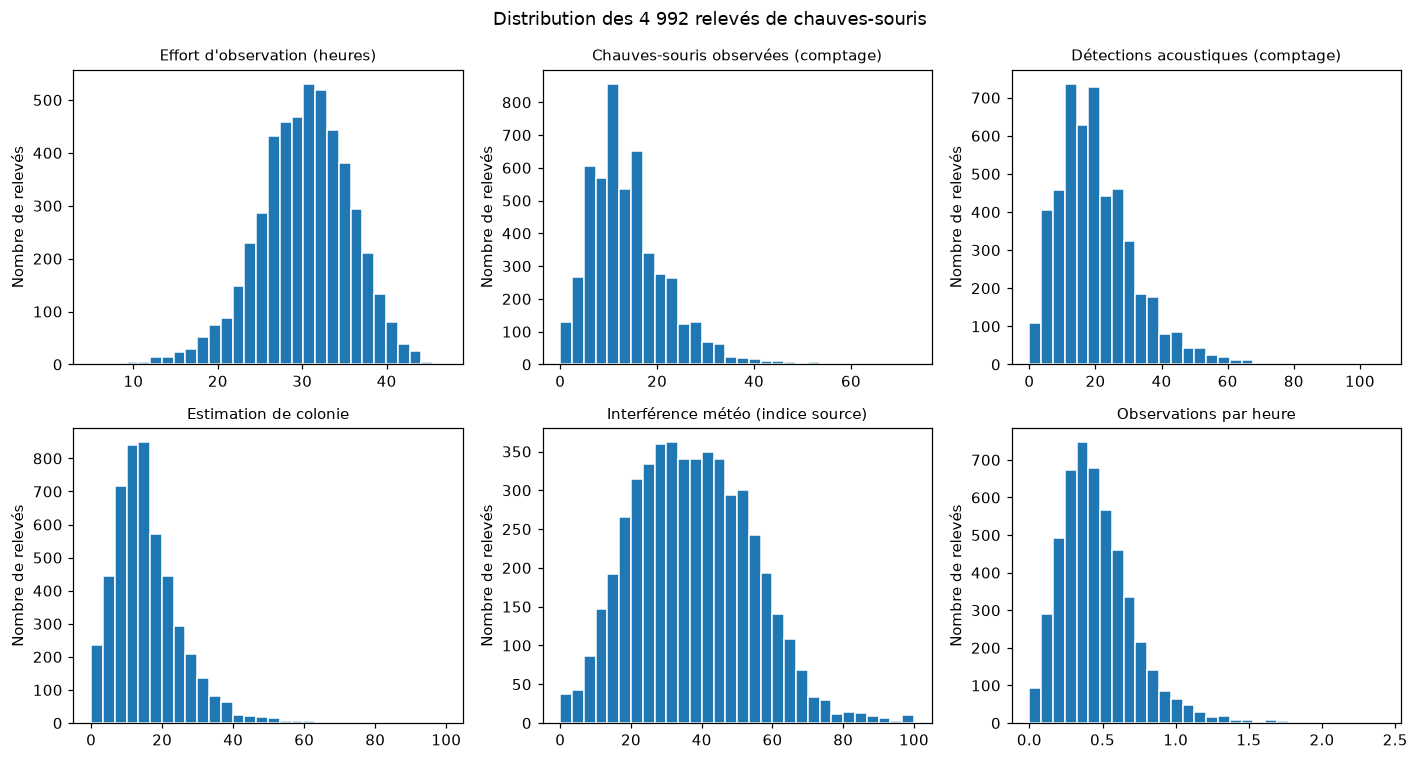

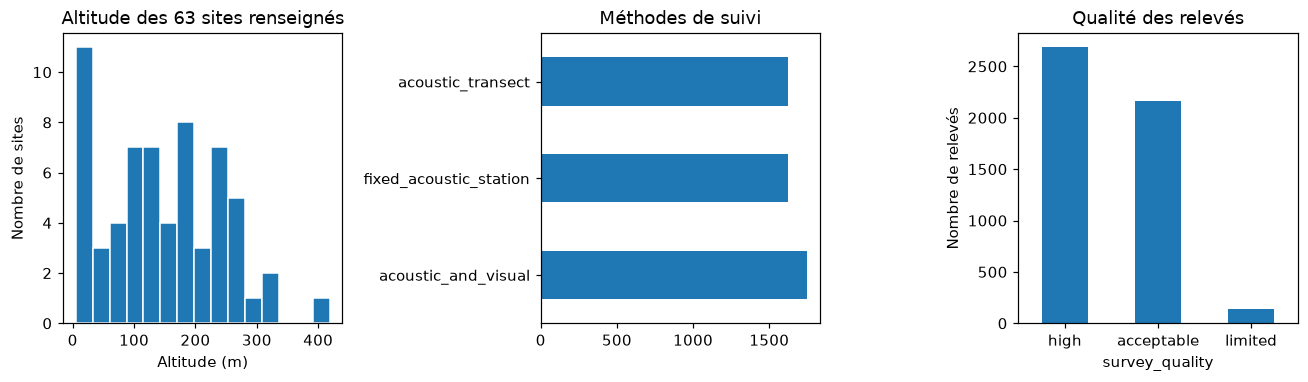

In [18]:
import numpy as np
import matplotlib.pyplot as plt

variables_histogrammes_ecology = {
    'observation_hours': "Effort d'observation (heures)",
    'observed_bat_count': 'Chauves-souris observées (comptage)',
    'acoustic_detection_count': 'Détections acoustiques (comptage)',
    'colony_estimate': 'Estimation de colonie',
    'weather_interference': 'Interférence météo (indice source)',
    'observations_par_heure': 'Observations par heure'
}
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for axe, (variable, titre) in zip(axes.flat, variables_histogrammes_ecology.items()):
    axe.hist(df_bats_enrichi[variable].dropna().astype(float), bins=30, edgecolor='white')
    axe.set_title(titre, fontsize=10)
    axe.set_ylabel('Nombre de relevés')
fig.suptitle('Distribution des 4 992 relevés de chauves-souris')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
df_sites['elevation_m'].dropna().plot.hist(bins=15, ax=axes[0], edgecolor='white')
axes[0].set_title('Altitude des 63 sites renseignés')
axes[0].set_xlabel('Altitude (m)')
axes[0].set_ylabel('Nombre de sites')
df_bats['survey_method'].value_counts().plot.barh(ax=axes[1])
axes[1].set_title('Méthodes de suivi')
axes[1].set_ylabel('')
df_bats['survey_quality'].value_counts().reindex(['high', 'acceptable', 'limited']).plot.bar(ax=axes[2], rot=0)
axes[2].set_title('Qualité des relevés')
axes[2].set_ylabel('Nombre de relevés')
plt.tight_layout()
plt.show()

### Comparaisons descriptives et relations entre variables

Nous comparons les distributions selon l'habitat, puis les relations entre effort,
observations, détections et météo. Pearson décrit une relation linéaire et Spearman
une relation monotone entre les rangs. Les 78 observations d'un site ne sont pas
78 sites indépendants. Ces corrélations regroupées sont descriptives, sans test
d'indépendance ni interprétation causale.

Pearson :
Spearman :


,nombre_sites,nombre_releves,mediane_observations_h,q1_observations_h,q3_observations_h
habitat_category,,,,,
coastal_habitat,10,780,0.401,0.303,0.534
degraded_land,2,156,0.142,0.082,0.215
durian_orchard,10,780,0.623,0.455,0.833
karst_habitat,9,702,0.513,0.358,0.684
mixed_agriculture,5,390,0.25,0.168,0.347
mixed_forest,19,1482,0.404,0.289,0.553
protected_forest,3,234,0.44,0.29,0.587
research_site,6,468,0.426,0.314,0.536


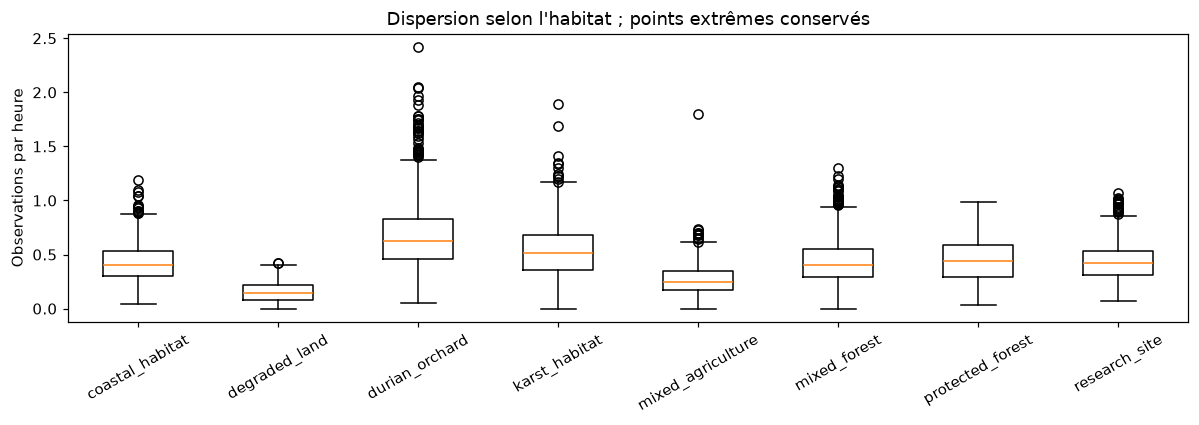

,observation_hours,observed_bat_count,acoustic_detection_count,colony_estimate,weather_interference
observation_hours,1.000,0.316,0.339,0.305,-0.688
observed_bat_count,0.316,1.000,0.783,0.961,-0.228
acoustic_detection_count,0.339,0.783,1.000,0.751,-0.364
colony_estimate,0.305,0.961,0.751,1.000,-0.219
weather_interference,-0.688,-0.228,-0.364,-0.219,1.000


,observation_hours,observed_bat_count,acoustic_detection_count,colony_estimate,weather_interference
observation_hours,1.000,0.324,0.352,0.312,-0.702
observed_bat_count,0.324,1.000,0.737,0.959,-0.231
acoustic_detection_count,0.352,0.737,1.000,0.709,-0.376
colony_estimate,0.312,0.959,0.709,1.000,-0.221
weather_interference,-0.702,-0.231,-0.376,-0.221,1.000


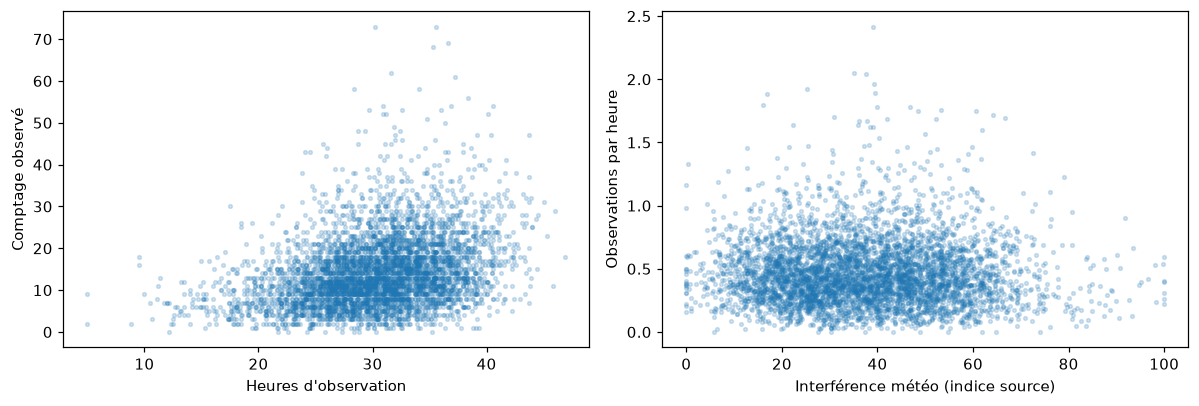

In [19]:
resume_habitats_ecology = df_bats_enrichi.groupby('habitat_category').agg(
    nombre_sites=('site_code', 'nunique'), nombre_releves=('survey_id', 'size'),
    mediane_observations_h=('observations_par_heure', 'median'),
    q1_observations_h=('observations_par_heure', lambda x: x.quantile(.25)),
    q3_observations_h=('observations_par_heure', lambda x: x.quantile(.75))
)
display(resume_habitats_ecology.round(3))
habitats_ecology = sorted(df_bats_enrichi['habitat_category'].unique())
fig, axe = plt.subplots(figsize=(11, 4))
axe.boxplot([df_bats_enrichi.loc[df_bats_enrichi['habitat_category'].eq(h), 'observations_par_heure'].astype(float) for h in habitats_ecology], tick_labels=habitats_ecology)
axe.tick_params(axis='x', rotation=30)
axe.set_ylabel('Observations par heure')
axe.set_title("Dispersion selon l'habitat ; points extrêmes conservés")
plt.tight_layout()
plt.show()

variables_correlation_ecology = ['observation_hours', 'observed_bat_count', 'acoustic_detection_count', 'colony_estimate', 'weather_interference']
correlations_pearson_bats = df_bats_enrichi[variables_correlation_ecology].corr(method='pearson')
correlations_spearman_bats = df_bats_enrichi[variables_correlation_ecology].corr(method='spearman')
print('Pearson :')
display(correlations_pearson_bats.round(3))
print('Spearman :')
display(correlations_spearman_bats.round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].scatter(df_bats_enrichi['observation_hours'], df_bats_enrichi['observed_bat_count'], s=6, alpha=.2)
axes[0].set(xlabel="Heures d'observation", ylabel='Comptage observé')
axes[1].scatter(df_bats_enrichi['weather_interference'], df_bats_enrichi['observations_par_heure'], s=6, alpha=.2)
axes[1].set(xlabel='Interférence météo (indice source)', ylabel='Observations par heure')
plt.tight_layout()
plt.show()

### Interprétation des différences entre habitats et des corrélations

**Les niveaux d’activité diffèrent selon l’habitat.**

Les vergers de durians présentent la médiane d’observations par heure
la plus élevée (0,623), suivis des habitats karstiques (0,513).
Les terrains dégradés présentent la médiane la plus faible (0,142).

Nous privilégions ici la médiane et les quartiles pour décrire
le niveau habituel et la dispersion, car les distributions comportent
des valeurs élevées qui peuvent influencer la moyenne.

Ces différences restent descriptives. Les terrains dégradés ne
représentent que deux sites, contre dix pour les vergers de durians.
Les relevés mensuels d’un même site ne sont pas indépendants :
156 relevés ne représentent donc pas 156 sites différents.
Nous ne pouvons pas attribuer les écarts au seul habitat.

**Les valeurs extrêmes sont conservées.**

Les boxplots montrent plusieurs observations élevées, notamment
dans les vergers de durians. Dépasser une moustache ne suffit pas
à démontrer une erreur : une activité ponctuellement forte peut
être réelle. Ces valeurs seront examinées avec leur site, leur date
et les conditions de collecte avant toute décision de correction.

**Certaines mesures apportent une information très proche.**

Le comptage observé et l’estimation de colonie sont très fortement
corrélés : Pearson vaut 0,961 et Spearman 0,959.
Ces deux variables ne doivent donc pas être considérées comme
deux confirmations indépendantes d’un même phénomène.
Si nous construisons un profil de comparaison, leur redondance
devra être prise en compte pour éviter de surpondérer cette information.

Les comptages visuels et acoustiques sont également positivement
associés, mais moins fortement (Pearson : 0,783 ; Spearman : 0,737).
Ils décrivent des variations liées, sans être interchangeables.

**L’effort et les conditions de collecte doivent être considérés.**

Les heures d’observation sont positivement associées aux comptages
observés (Pearson : 0,316). Un comptage plus élevé peut donc
accompagner un effort d’observation plus important.

La gêne météorologique est fortement associée à des durées
d’observation plus faibles (Pearson : −0,688 ; Spearman : −0,702).
Elle est aussi associée à moins de détections acoustiques.
Cela ne démontre pas une diminution de la population : les conditions
peuvent aussi être liées au temps disponible ou à la détection.

Les indices par heure tiennent compte de l’effort renseigné,
mais ne corrigent pas toutes ces différences. Nous poursuivons
donc avec les données environnementales, puis le fonctionnement
des appareils, avant d’interpréter une baisse comme inhabituelle.

### 3. Conditions environnementales — `environmental_monthly.csv`

Nous examinons la température, la pluie, l'humidité, la végétation et les
perturbations de l'habitat pour rechercher des explications aux variations
d'activité avant de les qualifier d'inhabituelles. Une association ne suffit
pas à établir une cause.

Une ligne décrit un site et un mois. Nous contrôlons cette clé, les doublons,
les types et les absences avant de choisir le nettoyage et de faire les jointures.


In [20]:
df_environnement_brut = pd.read_csv(
    "data/ecology/environmental_monthly.csv"
)

print("Dimensions :", df_environnement_brut.shape)

print(
    "Lignes entièrement dupliquées :",
    df_environnement_brut.duplicated().sum()
)

print(
    "Couples site-mois dupliqués :",
    df_environnement_brut.duplicated(
        subset=["site_code", "reporting_month"]
    ).sum()
)

print(
    "Nombre de sites représentés :",
    df_environnement_brut["site_code"].nunique()
)

structure_environnement = pd.DataFrame({
    "type_pandas": df_environnement_brut.dtypes.astype(str),
    "valeurs_manquantes": df_environnement_brut.isna().sum(),
    "valeurs_distinctes": df_environnement_brut.nunique()
})

print("\nStructure des variables :")
display(structure_environnement)

print("\nAperçu des données brutes :")
display(df_environnement_brut.head())

Dimensions : (4994, 11)
Lignes entièrement dupliquées : 2
Couples site-mois dupliqués : 2
Nombre de sites représentés : 64

Structure des variables :

Aperçu des données brutes :


,type_pandas,valeurs_manquantes,valeurs_distinctes
site_code,str,0,64
reporting_month,str,0,78
mean_temperature_c,str,0,824
rainfall_mm,str,0,2377
mean_humidity_pct,str,0,363
vegetation_cover_pct,float64,10,676
habitat_disturbance_index,float64,0,724
pesticide_index,float64,15,637
land_use_category,str,0,18
weather_exception_code,str,4790,2


,site_code,reporting_month,mean_temperature_c,rainfall_mm,mean_humidity_pct,vegetation_cover_pct,habitat_disturbance_index,pesticide_index,land_use_category,weather_exception_code,data_completeness_pct
0,KNT-KES,2019-01-01,25.25,95.0,74.4,69.7,25.9,31.6,karst_habitat,NaN,98.6
1,KNT-KES,2019-02-01,25.72,78.5,67.3,64.1,23.5,19.4,karst_habitat,NaN,90.4
2,KNT-KES,2019-03-01,25.8,100.4,67.0,62.8,24.6,18.0,karst_habitat,NaN,100.0
3,KNT-KES,2019-04-01,26.68,189.2,68.8,68.5,19.0,21.7,karst_habitat,NaN,96.0
4,KNT-KES,2019-05-01,26.87,198.9,75.9,74.3,21.1,17.1,karst_habitat,NaN,93.9


### Première lecture de la qualité des données

Le fichier contient 4 994 lignes, 11 variables, 64 sites et 78 mois distincts.
La couverture de chaque site reste à vérifier. Deux lignes sont entièrement
dupliquées : nous examinons leurs occurrences avant de retirer les copies.

Température, pluie et humidité sont stockées comme du texte. Leur écriture
doit être inspectée pour distinguer un problème de format d'une mesure absente.
Les 18 modalités de `land_use_category` peuvent aussi contenir des variantes.

La végétation comporte 10 absences, le pesticide 15 et le code météo 4 790
dans le fichier brut. Un zéro inventerait une mesure, et un code absent ne
prouve pas l'absence d'événement. Leur traitement est précisé après inspection.


In [21]:
print("Occurrences des doublons exacts :")

display(
    df_environnement_brut.loc[
        df_environnement_brut.duplicated(keep=False)
    ].sort_values(["site_code", "reporting_month"])
)

# Copie de travail : le tableau brut reste inchangé.
# Seules les répétitions strictement identiques sont retirées.
df_environnement = (
    df_environnement_brut
    .drop_duplicates()
    .reset_index(drop=True)
    .copy()
)

print("Nombre de lignes avant :", len(df_environnement_brut))
print("Nombre de lignes après :", len(df_environnement))

print(
    "Nombre de lignes supprimées :",
    len(df_environnement_brut) - len(df_environnement)
)

couples_repetes = df_environnement.duplicated(
    subset=["site_code", "reporting_month"],
    keep=False
)

print(
    "Couples site-mois encore dupliqués :",
    df_environnement.duplicated(
        subset=["site_code", "reporting_month"]
    ).sum()
)

if couples_repetes.any():
    print("Lignes différentes pour un même site-mois à examiner :")
    display(
        df_environnement.loc[couples_repetes]
        .sort_values(["site_code", "reporting_month"])
    )

Occurrences des doublons exacts :
Nombre de lignes avant : 4994
Nombre de lignes après : 4992
Nombre de lignes supprimées : 2
Couples site-mois encore dupliqués : 0


,site_code,reporting_month,mean_temperature_c,rainfall_mm,mean_humidity_pct,vegetation_cover_pct,habitat_disturbance_index,pesticide_index,land_use_category,weather_exception_code,data_completeness_pct
3489,AVL-NMQ,2023-10-01,25.88,203.0,81.6,80.8,23.3,38.1,durian_orchard,NaN,100.0
4993,AVL-NMQ,2023-10-01,25.88,203.0,81.6,80.8,23.3,38.1,durian_orchard,NaN,100.0
3490,AVL-NMQ,2023-11-01,25.48,241.4,80.2,75.1,22.8,24.6,durian_orchard,NaN,92.1
4992,AVL-NMQ,2023-11-01,25.48,241.4,80.2,75.1,22.8,24.6,durian_orchard,NaN,92.1


### Bilan des doublons et diagnostic numérique

Les copies retirées concernent AVL-NMQ en octobre et novembre 2023.
Il reste 4 992 lignes, sans couple site-mois dupliqué.

Nous recherchons maintenant les écritures numériques non directement
convertibles. Ce diagnostic ne modifie pas les valeurs et permettra
de choisir les corrections nécessaires.


In [22]:
variables_numeriques_texte_env = [
    "mean_temperature_c",
    "rainfall_mm",
    "mean_humidity_pct"
]

for colonne in variables_numeriques_texte_env:
    valeurs = (
        df_environnement[colonne]
        .astype("string")
        .str.strip()
    )

    # Diagnostic uniquement : df_environnement reste inchangé.
    conversion_test = pd.to_numeric(
        valeurs,
        errors="coerce"
    )

    non_convertibles = (
        valeurs.notna()
        & conversion_test.isna()
    )

    print(f"\nVariable : {colonne}")
    print(
        "Nombre de valeurs non directement convertibles :",
        non_convertibles.sum()
    )

    if non_convertibles.any():
        display(
            valeurs.loc[non_convertibles]
            .value_counts()
            .rename_axis("valeur_originale")
            .to_frame("nombre_occurrences")
        )


Variable : mean_temperature_c
Nombre de valeurs non directement convertibles : 40

Variable : rainfall_mm
Nombre de valeurs non directement convertibles : 50

Variable : mean_humidity_pct
Nombre de valeurs non directement convertibles : 10


,nombre_occurrences
valeur_originale,
"23,81",1
"26,34",1
"29,35",1
"26,63",1
"24,65",1
"26,56",1
25.86 C,1
23.3 C,1
"24,21",1


,nombre_occurrences
valeur_originale,
"201,4",2
102.7 mm,1
"75,5",1
251.3 mm,1
67.9 mm,1
29.5 mm,1
91.9 mm,1
210.9 mm,1
216.7 mm,1


,nombre_occurrences
valeur_originale,
"74,8",1
"64,7",1
"73,5",1
"83,2",1
"70,7",1
"87,4",1
"68,8",1
"80,0",1
"66,5",1


### Harmonisation des formats numériques

Le diagnostic repère 40 valeurs non directement convertibles pour
la température, 50 pour la pluie et 10 pour l’humidité.

Deux écritures expliquent ces difficultés :
- des virgules utilisées comme séparateurs décimaux ;
- les suffixes `C` pour la température et `mm` pour la pluie.

Nous remplaçons les virgules par des points et retirons uniquement
les suffixes observés. Les colonnes indiquent déjà les unités :
cette opération corrige donc leur écriture sans changer leur échelle.

Supprimer ces lignes ferait perdre des mesures interprétables.
Les transformer en valeurs manquantes, puis les imputer, serait
également inutile puisque leur valeur est disponible.

La conversion définitive utilise `errors="raise"` pour signaler
toute écriture qui resterait non interprétable. Le tableau brut
est conservé pour vérifier les transformations.

In [23]:
unites_numeriques_env = {
    "mean_temperature_c": "C",
    "rainfall_mm": "mm",
    "mean_humidity_pct": None
}

# Préparer toutes les conversions avant de modifier la copie de travail.
conversions_env = {}

for colonne, unite in unites_numeriques_env.items():
    valeurs = (
        df_environnement[colonne]
        .astype("string")
        .str.strip()
        .str.replace(",", ".", regex=False)
    )

    if unite is not None:
        valeurs = valeurs.str.replace(
            r"\s+" + unite + r"$",
            "",
            regex=True
        )

    conversions_env[colonne] = pd.to_numeric(
        valeurs,
        errors="raise"
    )

    # Vérifier que le nettoyage ne crée pas de valeur manquante.
    assert (
        conversions_env[colonne].isna().sum()
        == df_environnement[colonne].isna().sum()
    )

for colonne, valeurs_converties in conversions_env.items():
    df_environnement[colonne] = valeurs_converties

print("Types et valeurs manquantes après conversion :")

display(
    pd.DataFrame({
        "type_pandas": (
            df_environnement[variables_numeriques_texte_env]
            .dtypes.astype(str)
        ),
        "valeurs_manquantes": (
            df_environnement[variables_numeriques_texte_env]
            .isna().sum()
        )
    })
)

print("Nombre de relevés conservés :", len(df_environnement))

Types et valeurs manquantes après conversion :
Nombre de relevés conservés : 4992


,type_pandas,valeurs_manquantes
mean_temperature_c,Float64,0
rainfall_mm,Float64,0
mean_humidity_pct,Float64,0


### Bilan de la conversion et contrôle des mesures

Les trois colonnes sont numériques, sans absence créée ni relevé perdu.
Cela ne garantit pas leur exactitude : nous recherchons une pluie négative
et des pourcentages d'humidité, de végétation ou de complétude hors de [0 ; 100].

Les absences restent distinctes des valeurs hors limites. Nous ne fixons
pas de bornes aux indices sans définition et une température négative en
degrés Celsius ne serait pas automatiquement une erreur.


In [24]:
variables_mesure_env = [
    "mean_temperature_c",
    "rainfall_mm",
    "mean_humidity_pct",
    "vegetation_cover_pct",
    "habitat_disturbance_index",
    "pesticide_index",
    "data_completeness_pct"
]

print("Statistiques descriptives :")

display(
    df_environnement[variables_mesure_env]
    .describe()
    .T
    .round(2)
)

incoherences_env = pd.DataFrame(
    index=df_environnement.index
)

incoherences_env["pluie_negative"] = (
    df_environnement["rainfall_mm"].lt(0).fillna(False)
)

for colonne in [
    "mean_humidity_pct",
    "vegetation_cover_pct",
    "data_completeness_pct"
]:
    incoherences_env[f"{colonne}_hors_bornes"] = (
        df_environnement[colonne].notna()
        & ~df_environnement[colonne].between(0, 100)
    )

print("\nNombre de valeurs incohérentes par contrôle :")

display(
    incoherences_env.sum()
    .to_frame("nombre_valeurs")
)

lignes_incoherentes_env = incoherences_env.any(axis=1)

print(
    "\nNombre de lignes concernées :",
    lignes_incoherentes_env.sum()
)

display(
    df_environnement.loc[
        lignes_incoherentes_env,
        ["site_code", "reporting_month"] + variables_mesure_env
    ]
)

Statistiques descriptives :

Nombre de valeurs incohérentes par contrôle :

Nombre de lignes concernées : 0


,count,mean,std,min,25%,50%,75%,max
mean_temperature_c,4992.0,26.377073,1.672062,21.3,25.19,26.35,27.6125,32.0
rainfall_mm,4992.0,159.89403,74.901939,5.0,95.7,156.25,221.7,384.3
mean_humidity_pct,4992.0,75.841847,7.248342,56.7,70.3,75.9,81.5,96.4
vegetation_cover_pct,4982.0,61.014211,13.997015,15.0,52.7,62.3,70.9,98.0
habitat_disturbance_index,4992.0,30.364423,16.358109,0.0,17.9,29.4,41.4,86.8
pesticide_index,4977.0,25.016395,16.26636,0.0,11.6,25.2,37.5,77.3
data_completeness_pct,4992.0,95.961819,2.817944,85.5,94.0,96.15,98.2,100.0


,nombre_valeurs
pluie_negative,0
mean_humidity_pct_hors_bornes,0
vegetation_cover_pct_hors_bornes,0
data_completeness_pct_hors_bornes,0


,site_code,reporting_month,mean_temperature_c,rainfall_mm,mean_humidity_pct,vegetation_cover_pct,habitat_disturbance_index,pesticide_index,data_completeness_pct


### Bilan du contrôle des mesures numériques

Aucune pluie négative ni aucun pourcentage hors de [0 ; 100] n'est détecté.
La température varie de 21,3 à 32 °C (médiane : 26,35 °C) et la pluie
de 5 à 384,3 mm (médiane : 156,25 mm). Ces résumés regroupent sites et saisons.

Les statistiques de végétation et de pesticide reposent sur 4 982 et 4 977
mesures renseignées. La complétude déclarée médiane est de 96,15 %,
sans garantie d'exactitude ni de renseignement de chaque colonne.
Les histogrammes complètent ces résumés par la forme des distributions.


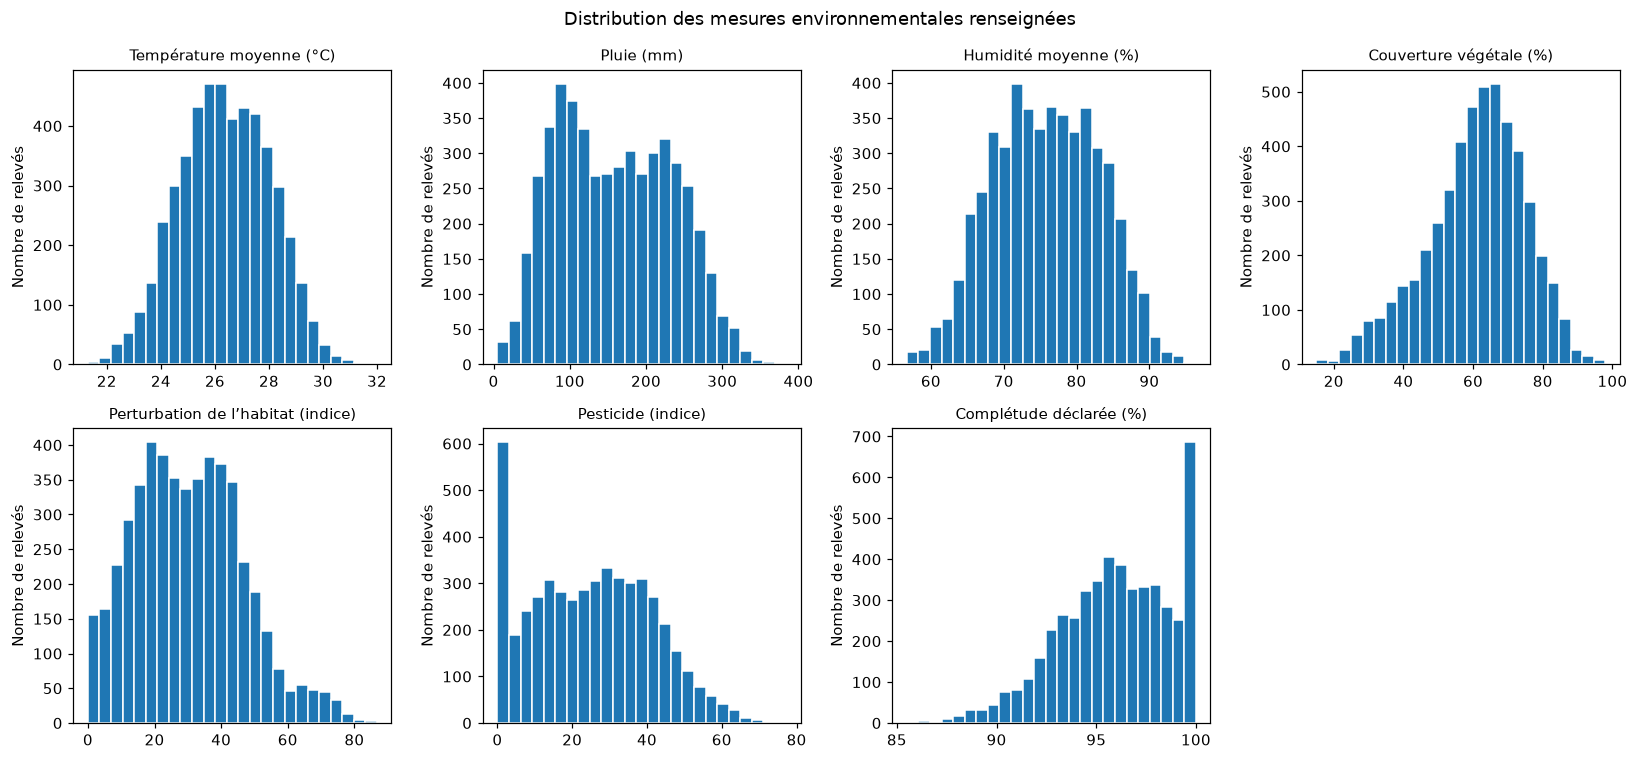

In [25]:
import matplotlib.pyplot as plt

variables_histogrammes_env = {
    "mean_temperature_c": "Température moyenne (°C)",
    "rainfall_mm": "Pluie (mm)",
    "mean_humidity_pct": "Humidité moyenne (%)",
    "vegetation_cover_pct": "Couverture végétale (%)",
    "habitat_disturbance_index": "Perturbation de l’habitat (indice)",
    "pesticide_index": "Pesticide (indice)",
    "data_completeness_pct": "Complétude déclarée (%)"
}

fig, axes = plt.subplots(
    2, 4,
    figsize=(15, 7)
)

for axe, (colonne, titre) in zip(
    axes.flat,
    variables_histogrammes_env.items()
):
    valeurs = (
        df_environnement[colonne]
        .dropna()
        .astype(float)
    )

    axe.hist(
        valeurs,
        bins=25,
        edgecolor="white"
    )

    axe.set_title(titre, fontsize=10)
    axe.set_ylabel("Nombre de relevés")

# Sept variables : le huitième emplacement reste inutilisé.
axes[1, 3].axis("off")

fig.suptitle(
    "Distribution des mesures environnementales renseignées"
)

plt.tight_layout()
plt.show()

### Lecture des distributions environnementales

La température présente une concentration centrale autour de 26–27 °C.
L’humidité est également concentrée autour de valeurs intermédiaires.
Ces formes ne suffisent toutefois pas à affirmer une loi normale.

La pluie présente plusieurs concentrations, notamment autour de
100 mm et de 200–250 mm. Cette répartition peut mélanger des différences
entre sites et entre saisons. Une valeur éloignée de la moyenne globale
n’est donc pas nécessairement inhabituelle pour son site et son mois.

La couverture végétale est principalement concentrée autour de 60–75 %,
avec quelques valeurs plus faibles. L’indice de perturbation présente
une queue vers les valeurs élevées. Nous conservons ces observations :
elles peuvent décrire des environnements réellement différents.

L’indice de pesticide comporte de nombreuses valeurs proches de zéro.
L’histogramme regroupe les valeurs par intervalles : sa première barre
ne représente donc pas uniquement des zéros. Ces valeurs faibles restent
distinctes des données manquantes et ne prouvent pas, sans définition
de l’indice, une absence totale de pesticide.

La complétude déclarée est concentrée vers les valeurs élevées,
avec une accumulation près de 100 %. Cela ne garantit pas
l’exactitude de chaque mesure.

Ces graphiques ne justifient aucune suppression automatique.
Ils montrent surtout qu’une référence globale peut masquer
les différences entre sites et périodes.

### Vérification des catégories

Nous examinons maintenant les modalités de `land_use_category`
et de `weather_exception_code` avant toute harmonisation.
L’objectif est de distinguer les variantes d’écriture des catégories
réellement différentes. Les valeurs manquantes restent visibles.

In [26]:
for colonne in [
    "land_use_category",
    "weather_exception_code"
]:
    print(f"\nRépartition de {colonne} :")

    display(
        df_environnement[colonne]
        .value_counts(dropna=False)
        .rename_axis(colonne)
        .to_frame("nombre_releves")
    )

    print(
        "Nombre de modalités renseignées :",
        df_environnement[colonne].nunique()
    )

    print(
        "Nombre de valeurs manquantes :",
        df_environnement[colonne].isna().sum()
    )


Répartition de land_use_category :
Nombre de modalités renseignées : 18
Nombre de valeurs manquantes : 0

Répartition de weather_exception_code :
Nombre de modalités renseignées : 2
Nombre de valeurs manquantes : 4788


,nombre_releves
land_use_category,
mixed_forest,1481
coastal_habitat,780
durian_orchard,777
karst_habitat,697
research_site,467
mixed_agriculture,388
protected_forest,234
degraded_land,153
Karst_Habitat,4


,nombre_releves
weather_exception_code,
NaN,4788
HEAVY_RAIN,112
DRY_SPELL,92


### Harmonisation des catégories environnementales

Les 18 modalités de `land_use_category` correspondent à huit catégories
avec des variantes de casse. Nous harmonisons la casse et les espaces
pour éviter de séparer artificiellement un même usage du sol.

`HEAVY_RAIN` et `DRY_SPELL` restent inchangés. Les 4 788 codes absents
ne sont remplacés ni par le code le plus fréquent, ni par « aucune exception » :
ces choix attribueraient un événement ou son absence sans information source.
Les autres mesures de ces relevés restent utilisables.


In [27]:
categories_env_avant = (
    df_environnement["land_use_category"].copy()
)

df_environnement["land_use_category"] = (
    df_environnement["land_use_category"]
    .astype("string")
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
    .str.lower()
)

print("Catégories après harmonisation :")

display(
    df_environnement["land_use_category"]
    .value_counts(dropna=False)
    .rename_axis("land_use_category")
    .to_frame("nombre_releves")
)

print(
    "Nombre de modalités après harmonisation :",
    df_environnement["land_use_category"].nunique()
)

print(
    "Nombre de libellés corrigés :",
    categories_env_avant.ne(
        df_environnement["land_use_category"]
    ).sum()
)

print(
    "Codes météo toujours manquants :",
    df_environnement["weather_exception_code"].isna().sum()
)

print(
    "Nombre de relevés conservés :",
    len(df_environnement)
)

Catégories après harmonisation :
Nombre de modalités après harmonisation : 8
Nombre de libellés corrigés : 15
Codes météo toujours manquants : 4788
Nombre de relevés conservés : 4992


,nombre_releves
land_use_category,
mixed_forest,1482
durian_orchard,780
coastal_habitat,780
karst_habitat,702
research_site,468
mixed_agriculture,390
protected_forest,234
degraded_land,156


### Bilan de l'harmonisation et conversion des mois

Huit catégories restent après correction de 15 libellés, sans perte de relevé.
Nous convertissons `reporting_month` avec le format année-mois-jour observé,
en arrêtant le traitement si une écriture est incompatible.

Une clé mensuelle servira aux jointures : ce repère ne date pas exactement
chaque mesure. Nous revérifions son unicité, car des écritures différentes
pourraient désigner un même mois après conversion.


In [28]:
df_environnement["reporting_month"] = pd.to_datetime(
    df_environnement["reporting_month"],
    format="%Y-%m-%d",
    errors="raise"
)

df_environnement["mois_releve"] = (
    df_environnement["reporting_month"].dt.to_period("M")
)

print("Types après conversion :")

display(
    df_environnement[
        ["reporting_month", "mois_releve"]
    ]
    .dtypes.astype(str)
    .to_frame("type_pandas")
)

print(
    "Dates manquantes après conversion :",
    df_environnement["reporting_month"].isna().sum()
)

print("Premier mois :", df_environnement["mois_releve"].min())
print("Dernier mois :", df_environnement["mois_releve"].max())

print(
    "Couples site-mois dupliqués après conversion :",
    df_environnement.duplicated(
        subset=["site_code", "mois_releve"]
    ).sum()
)

print("Nombre de relevés conservés :", len(df_environnement))

Types après conversion :
Dates manquantes après conversion : 0
Premier mois : 2019-01
Dernier mois : 2025-06
Couples site-mois dupliqués après conversion : 0
Nombre de relevés conservés : 4992


,type_pandas
reporting_month,datetime64[us]
mois_releve,period[M]


### Vérification de la couverture mensuelle

Les dates couvrent janvier 2019 à juin 2025, sans clé site-mois dupliquée.
Nous recherchons les sites inconnus, les mois hors période et les combinaisons
absentes parmi les 64 sites et 78 mois attendus. Un total correct pourrait
masquer des manques compensés par des répétitions.

Dans ce contrôle de couverture, zéro signifie « aucun relevé »,
pas une mesure environnementale égale à zéro.


In [29]:
sites_attendus_env = df_sites["site_code"].tolist()

mois_attendus_env = pd.period_range(
    start=df_bats["mois_releve"].min(),
    end=df_bats["mois_releve"].max(),
    freq="M"
)

sites_inconnus_env = (
    ~df_environnement["site_code"].isin(sites_attendus_env)
)

mois_hors_periode_env = (
    ~df_environnement["mois_releve"].isin(mois_attendus_env)
)

print(
    "Relevés avec un code de site inconnu :",
    sites_inconnus_env.sum()
)
print(
    "Relevés hors de la période attendue :",
    mois_hors_periode_env.sum()
)

# Tableau de nombres de relevés, pas de valeurs environnementales.
suivi_mensuel_env = pd.crosstab(
    df_environnement["site_code"],
    df_environnement["mois_releve"]
).reindex(
    index=sites_attendus_env,
    columns=mois_attendus_env,
    fill_value=0
)

resume_suivi_env = pd.DataFrame({
    "nombre_releves": suivi_mensuel_env.sum(axis=1),
    "nombre_mois_observes": suivi_mensuel_env.gt(0).sum(axis=1),
    "nombre_mois_absents": suivi_mensuel_env.eq(0).sum(axis=1),
    "nombre_mois_avec_plusieurs_releves": (
        suivi_mensuel_env.gt(1).sum(axis=1)
    )
})

print("\nNombre de sites attendus :", len(sites_attendus_env))
print("Nombre de mois attendus :", len(mois_attendus_env))

print("\nAperçu du suivi par site :")
display(resume_suivi_env.head())

sites_a_verifier_env = (
    resume_suivi_env["nombre_mois_absents"].gt(0)
    | resume_suivi_env[
        "nombre_mois_avec_plusieurs_releves"
    ].gt(0)
)

print(
    "\nSites avec des mois absents ou plusieurs relevés par mois :",
    sites_a_verifier_env.sum()
)

display(resume_suivi_env.loc[sites_a_verifier_env])

Relevés avec un code de site inconnu : 0
Relevés hors de la période attendue : 0

Nombre de sites attendus : 64
Nombre de mois attendus : 78

Aperçu du suivi par site :

Sites avec des mois absents ou plusieurs relevés par mois : 0


,nombre_releves,nombre_mois_observes,nombre_mois_absents,nombre_mois_avec_plusieurs_releves
site_code,,,,
KNT-KES,78,78,0,0
KNT-LUM,78,78,0,0
KNT-SEN,78,78,0,0
AVL-MAR,78,78,0,0
AVL-VEL,78,78,0,0


,nombre_releves,nombre_mois_observes,nombre_mois_absents,nombre_mois_avec_plusieurs_releves
site_code,,,,


### Bilan de la couverture et localisation des absences

Chaque site possède un relevé pour chacun des 78 mois, sans site inconnu
ni mois hors période. Cette couverture n'implique pas que toutes les mesures
sont renseignées. Nous localisons les 10 absences de végétation et les 15
de pesticide : une concentration locale pourrait limiter les comparaisons
malgré leur faible proportion globale.


In [30]:
variables_manquantes_env = [
    "vegetation_cover_pct",
    "pesticide_index"
]

bilan_manquants_env = pd.DataFrame({
    "nombre_valeurs_manquantes": (
        df_environnement[variables_manquantes_env]
        .isna().sum()
    ),
    "pourcentage_manquant": (
        df_environnement[variables_manquantes_env]
        .isna().mean() * 100
    )
})

print("Bilan des mesures manquantes :")
display(bilan_manquants_env.round(2))

lignes_mesures_manquantes_env = (
    df_environnement[variables_manquantes_env]
    .isna()
    .any(axis=1)
)

print(
    "\nNombre de relevés concernés :",
    lignes_mesures_manquantes_env.sum()
)

print(
    "Nombre de sites concernés :",
    df_environnement.loc[
        lignes_mesures_manquantes_env,
        "site_code"
    ].nunique()
)

print("\nLocalisation des mesures manquantes :")

display(
    df_environnement.loc[
        lignes_mesures_manquantes_env,
        [
            "site_code",
            "reporting_month",
            "land_use_category",
            "vegetation_cover_pct",
            "pesticide_index",
            "data_completeness_pct"
        ]
    ].sort_values(["site_code", "reporting_month"])
)

Bilan des mesures manquantes :

Nombre de relevés concernés : 25
Nombre de sites concernés : 20

Localisation des mesures manquantes :


,nombre_valeurs_manquantes,pourcentage_manquant
vegetation_cover_pct,10,0.2
pesticide_index,15,0.3


,site_code,reporting_month,land_use_category,vegetation_cover_pct,pesticide_index,data_completeness_pct
3031,AVL-BWK,2024-08-01,mixed_forest,74.8,NaN,98.4
2477,AVL-DER,2023-12-01,mixed_forest,65.9,NaN,94.0
2342,AVL-GRB,2019-03-01,mixed_agriculture,NaN,45.8,99.1
3276,AVL-HUA,2019-01-01,mixed_agriculture,NaN,42.0,98.2
3506,AVL-NMQ,2025-03-01,durian_orchard,NaN,28.4,98.3
2748,AVL-RBC,2020-07-01,durian_orchard,61.3,NaN,97.3
3217,AVL-SEY,2020-08-01,mixed_forest,NaN,38.7,96.4
1998,KNT-BME,2023-01-01,karst_habitat,NaN,52.7,92.7
2004,KNT-BME,2023-07-01,karst_habitat,83.5,NaN,93.9
1437,KNT-DMJ,2021-10-01,mixed_forest,65.4,NaN,94.8


### Traitement retenu pour les mesures manquantes

La couverture végétale comporte 10 valeurs manquantes (0,2 %)
et l’indice de pesticide 15 (0,3 %). Elles concernent 25 relevés
distincts répartis sur 20 sites et plusieurs années.

Les absences ne sont donc pas limitées à un seul site ou à une
seule période. Certaines se répètent toutefois localement :
KNT-TLQ présente deux indices de pesticide absents en novembre
et décembre 2019. Cette inspection ne permet pas d’établir
la cause des absences ni de les considérer comme aléatoires.

Nous conservons les relevés et laissons ces mesures manquantes :

- supprimer les lignes ferait perdre leurs autres mesures disponibles ;
- remplacer les absences par zéro inventerait une valeur ;
- utiliser une moyenne ou médiane globale pourrait masquer
  les différences entre sites et saisons.

Aucune imputation n’est indispensable pour terminer cette exploration.
Pour les calculs utilisant ces variables, les observations disponibles
et leurs effectifs seront précisés. Si une analyse nécessite ensuite
une matrice complète, son traitement des absences devra être justifié
pour cette analyse particulière.

Enfin, certains relevés affichent une complétude de 100 % malgré
un indice de pesticide absent. Cet indicateur ne suffit donc pas
à garantir que toutes les colonnes sont renseignées. Nous conservons
sa valeur déclarée sans la recalculer arbitrairement.

### 4. Fonctionnement des appareils — `monitoring_device_operations.csv`

Une faible détection peut venir d'un appareil dégradé. Nous contrôlons
donc la disponibilité, la qualité acoustique, les périodes et la maintenance
avant de rechercher une explication technique aux variations.
Les mesures mensuelles ne décrivent toutefois pas le fonctionnement exact
pendant les seules heures d'un relevé.


In [31]:
df_appareils_brut = pd.read_csv(
    "data/ecology/monitoring_device_operations.csv"
)

print("Dimensions :", df_appareils_brut.shape)

print(
    "Lignes entièrement dupliquées :",
    df_appareils_brut.duplicated().sum()
)

print(
    "Identifiants d’opération dupliqués :",
    df_appareils_brut["device_operation_id"].duplicated().sum()
)

print(
    "Nombre de sites représentés :",
    df_appareils_brut["site_code"].nunique()
)

structure_appareils = pd.DataFrame({
    "type_pandas": df_appareils_brut.dtypes.astype(str),
    "valeurs_manquantes": df_appareils_brut.isna().sum(),
    "valeurs_distinctes": df_appareils_brut.nunique()
})

print("\nStructure des variables :")
display(structure_appareils)

print("\nAperçu des données brutes :")
display(df_appareils_brut.head())

Dimensions : (4994, 11)
Lignes entièrement dupliquées : 2
Identifiants d’opération dupliqués : 2
Nombre de sites représentés : 64

Structure des variables :

Aperçu des données brutes :


,type_pandas,valeurs_manquantes,valeurs_distinctes
device_operation_id,str,0,4992
site_code,str,0,64
device_reference,str,0,64
operation_start,str,0,78
operation_end,str,0,97
uptime_pct,str,0,389
acoustic_quality,float64,0,458
maintenance_type,str,0,5
fault_code,str,4805,3
maintenance_provider,str,30,4


,device_operation_id,site_code,device_reference,operation_start,operation_end,uptime_pct,acoustic_quality,maintenance_type,fault_code,maintenance_provider,record_status
0,DOP-0000001,KNT-KES,DEV-KNTKES-2,2019-01-01T00:00:00,2019-01-31T23:59:59,92.3,85.9,routine inspection,NaN,ECO-SERVICE-2,closed
1,DOP-0000002,KNT-KES,DEV-KNTKES-2,2019-02-01T00:00:00,2019-02-28T23:59:59,80.6,79.6,routine inspection,NaN,ECO-SERVICE-2,closed
2,DOP-0000003,KNT-KES,DEV-KNTKES-2,2019-03-01T00:00:00,2019-03-31T23:59:59,94.9,82.5,routine inspection,NaN,ECO-SERVICE-2,closed
3,DOP-0000004,KNT-KES,DEV-KNTKES-2,2019-04-01T00:00:00,2019-04-30T23:59:59,94.8,84.8,routine inspection,NaN,ECO-SERVICE-2,closed
4,DOP-0000005,KNT-KES,DEV-KNTKES-2,2019-05-01T00:00:00,2019-05-31T23:59:59,87.7,69.2,routine inspection,NaN,ECO-SERVICE-2,closed


### Première lecture de la qualité des données

Le fichier contient 4 994 lignes et 11 variables, dont deux copies exactes
à examiner avant suppression. Il représente 64 sites et 64 appareils :
leur association sera contrôlée, car l'égalité des effectifs ne prouve pas
une correspondance un-à-un.

Les dates et la disponibilité sont textuelles. Nous inspectons leurs formats
avant conversion. La qualité acoustique est numérique, mais son unité n'est
pas précisée. Le traitement des codes de panne et prestataires absents
est justifié avec les catégories de maintenance.


In [32]:
print("Occurrences des doublons exacts :")

display(
    df_appareils_brut.loc[
        df_appareils_brut.duplicated(keep=False)
    ].sort_values("device_operation_id")
)

# Conserver le tableau brut et retirer seulement les copies identiques.
df_appareils = (
    df_appareils_brut
    .drop_duplicates()
    .reset_index(drop=True)
    .copy()
)

print("Nombre de lignes avant :", len(df_appareils_brut))
print("Nombre de lignes après :", len(df_appareils))

print(
    "Nombre de lignes supprimées :",
    len(df_appareils_brut) - len(df_appareils)
)

identifiants_appareils_repetes = (
    df_appareils["device_operation_id"]
    .duplicated(keep=False)
)

print(
    "Identifiants d’opération encore dupliqués :",
    df_appareils["device_operation_id"].duplicated().sum()
)

if identifiants_appareils_repetes.any():
    print("Opérations portant le même identifiant à examiner :")
    display(
        df_appareils.loc[identifiants_appareils_repetes]
        .sort_values("device_operation_id")
    )

Occurrences des doublons exacts :
Nombre de lignes avant : 4994
Nombre de lignes après : 4992
Nombre de lignes supprimées : 2
Identifiants d’opération encore dupliqués : 0


,device_operation_id,site_code,device_reference,operation_start,operation_end,uptime_pct,acoustic_quality,maintenance_type,fault_code,maintenance_provider,record_status
1225,DOP-0001226,KNT-CHP,DEV-KNTCHP-3,2023-08-01T00:00:00,2023-08-31T23:59:59,93.2,73.5,routine inspection,NaN,ECO-SERVICE-1,closed
4993,DOP-0001226,KNT-CHP,DEV-KNTCHP-3,2023-08-01T00:00:00,2023-08-31T23:59:59,93.2,73.5,routine inspection,NaN,ECO-SERVICE-1,closed
1390,DOP-0001391,KNT-WUQ,DEV-KNTWUQ-2,2024-05-01T00:00:00,2024-05-31T23:59:59,92.7,78.6,routine inspection,NaN,ECO-SERVICE-3,closed
4992,DOP-0001391,KNT-WUQ,DEV-KNTWUQ-2,2024-05-01T00:00:00,2024-05-31T23:59:59,92.7,78.6,routine inspection,NaN,ECO-SERVICE-3,closed


### Bilan du traitement des doublons

Les opérations DOP-0001226 et DOP-0001391 étaient chacune présentes
deux fois avec exactement les mêmes informations.

Une seule occurrence de chaque opération est conservée. Le fichier
passe ainsi de 4 994 à 4 992 lignes, sans perdre d’information distincte.
Aucun identifiant d’opération dupliqué ne subsiste.

Cela ne garantit pas encore l’unicité des périodes par site :
les dates et la couverture mensuelle seront contrôlées séparément.

### Vérification du format de la disponibilité

`uptime_pct` représente un pourcentage de disponibilité, mais
la colonne est stockée comme du texte.

Avant de la convertir, nous recherchons les valeurs non directement
interprétables comme des nombres. Ce diagnostic permettra de choisir
une correction adaptée aux écritures réellement présentes.

La conversion de diagnostic ne modifie pas le tableau de travail :
les valeurs problématiques restent disponibles pour inspection.

In [33]:
disponibilite_texte = (
    df_appareils["uptime_pct"]
    .astype("string")
    .str.strip()
)

# Diagnostic uniquement : df_appareils reste inchangé.
conversion_test_disponibilite = pd.to_numeric(
    disponibilite_texte,
    errors="coerce"
)

disponibilites_non_convertibles = (
    disponibilite_texte.notna()
    & conversion_test_disponibilite.isna()
)

print(
    "Nombre de valeurs non directement convertibles :",
    disponibilites_non_convertibles.sum()
)

if disponibilites_non_convertibles.any():
    display(
        disponibilite_texte.loc[
            disponibilites_non_convertibles
        ]
        .value_counts()
        .rename_axis("valeur_originale")
        .to_frame("nombre_occurrences")
    )

Nombre de valeurs non directement convertibles : 50


,nombre_occurrences
valeur_originale,
"100,0",9
"91,3",2
"92,9",2
"89,0",2
"99,4",2
"94,2",2
"99,3",1
"98,1",1
"90,9",1


### Conversion de la disponibilité en variable numérique

Les 50 écritures concernées utilisent une virgule décimale. Nous remplaçons
la virgule par un point : `91,3` devient 91.3 %, sans changer l'échelle.
La valeur étant renseignée, supprimer ou imputer ces opérations serait inutile.

La conversion s'arrête sur une écriture incompatible. Nous vérifions
l'absence de valeur manquante créée et le respect de [0 ; 100].


In [34]:
disponibilite_convertie = pd.to_numeric(
    df_appareils["uptime_pct"]
    .astype("string")
    .str.strip()
    .str.replace(",", ".", regex=False),
    errors="raise"
)

# Ne pas créer silencieusement de valeur manquante.
assert (
    disponibilite_convertie.isna().sum()
    == df_appareils["uptime_pct"].isna().sum()
)

df_appareils["uptime_pct"] = disponibilite_convertie

print("Type après conversion :", df_appareils["uptime_pct"].dtype)

print(
    "Valeurs manquantes après conversion :",
    df_appareils["uptime_pct"].isna().sum()
)

disponibilite_hors_bornes = (
    df_appareils["uptime_pct"].notna()
    & ~df_appareils["uptime_pct"].between(0, 100)
)

print(
    "Disponibilités hors de [0 ; 100] :",
    disponibilite_hors_bornes.sum()
)

if disponibilite_hors_bornes.any():
    display(
        df_appareils.loc[
            disponibilite_hors_bornes,
            ["device_operation_id", "site_code", "uptime_pct"]
        ]
    )

print("Nombre d’opérations conservées :", len(df_appareils))

Type après conversion : Float64
Valeurs manquantes après conversion : 0
Disponibilités hors de [0 ; 100] : 0
Nombre d’opérations conservées : 4992


### Bilan de la conversion et description des mesures

La disponibilité est numérique, sans absence créée ni valeur hors de [0 ; 100].
Nous décrivons séparément disponibilité et qualité acoustique : les mélanger
dans une moyenne n'aurait pas de signification. La qualité conserve l'échelle
source, sans unité ni seuil supposé.


In [35]:
variables_mesures_appareils = [
    "uptime_pct",
    "acoustic_quality"
]

print("Statistiques descriptives des mesures des appareils :")

display(
    df_appareils[variables_mesures_appareils]
    .describe()
    .T
    .round(2)
)

print("\nValeurs manquantes dans ces mesures :")

display(
    df_appareils[variables_mesures_appareils]
    .isna()
    .sum()
    .to_frame("nombre_valeurs_manquantes")
)

Statistiques descriptives des mesures des appareils :

Valeurs manquantes dans ces mesures :


,count,mean,std,min,25%,50%,75%,max
uptime_pct,4992.0,92.525962,7.926554,23.1,90.2,93.8,97.3,100.0
acoustic_quality,4992.0,78.992448,8.506378,20.0,73.9,79.3,84.625,100.0


,nombre_valeurs_manquantes
uptime_pct,0
acoustic_quality,0


### Lecture des statistiques des appareils

La disponibilité médiane est de 93,8 %, avec la moitié des valeurs entre
90,2 et 97,3 % et un minimum de 23,1 %. La qualité acoustique médiane vaut
79,3, avec la moitié des valeurs entre 73,9 et 84,63 et un minimum de 20.
Les deux mesures sont renseignées pour les 4 992 opérations.

Ces minima motivent les graphiques, mais les statistiques séparées ne disent
pas si les mêmes opérations cumulent faible disponibilité, faible qualité
et faibles comptages.


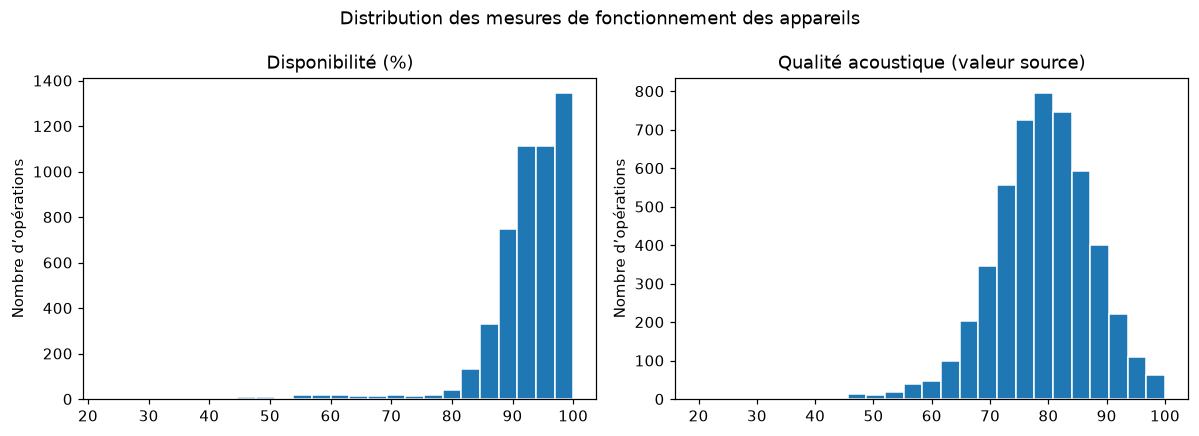

In [36]:
mesures_histogrammes_appareils = {
    "uptime_pct": "Disponibilité (%)",
    "acoustic_quality": "Qualité acoustique (valeur source)"
}

fig, axes = plt.subplots(
    1, 2,
    figsize=(11, 4)
)

for axe, (colonne, titre) in zip(
    axes,
    mesures_histogrammes_appareils.items()
):
    valeurs = (
        df_appareils[colonne]
        .dropna()
        .astype(float)
    )

    axe.hist(
        valeurs,
        bins=25,
        edgecolor="white"
    )

    axe.set_title(titre)
    axe.set_ylabel("Nombre d’opérations")

fig.suptitle("Distribution des mesures de fonctionnement des appareils")

plt.tight_layout()
plt.show()

### Lecture des distributions et examen de la maintenance

La disponibilité se concentre entre 90 et 100 %, avec une queue vers les
valeurs faibles. La qualité acoustique se concentre autour de 80, sans que
cette forme suffise à affirmer une loi normale.

Les valeurs faibles sont conservées : elles peuvent décrire des difficultés
réelles utiles à l'interprétation des détections. L'histogramme ne définit
pas à lui seul un seuil de bon fonctionnement.

Nous examinons maintenant les catégories et les absences de maintenance.
Les références des prestataires restent intactes pour les rapprochements.


In [37]:
colonnes_categories_appareils = [
    "maintenance_type",
    "fault_code",
    "maintenance_provider",
    "record_status"
]

for colonne in colonnes_categories_appareils:
    print(f"\nRépartition de {colonne} :")

    display(
        df_appareils[colonne]
        .value_counts(dropna=False)
        .rename_axis(colonne)
        .to_frame("nombre_operations")
    )

    print(
        "Nombre de modalités renseignées :",
        df_appareils[colonne].nunique()
    )

    print(
        "Nombre de valeurs manquantes :",
        df_appareils[colonne].isna().sum()
    )


Répartition de maintenance_type :
Nombre de modalités renseignées : 5
Nombre de valeurs manquantes : 0

Répartition de fault_code :
Nombre de modalités renseignées : 3
Nombre de valeurs manquantes : 4803

Répartition de maintenance_provider :
Nombre de modalités renseignées : 4
Nombre de valeurs manquantes : 30

Répartition de record_status :
Nombre de modalités renseignées : 3
Nombre de valeurs manquantes : 0


,nombre_operations
maintenance_type,
routine inspection,4783
corrective maintenance,137
sensor replacement,52
ROUTINE INSPECTION,12
Routine Inspection,8


,nombre_operations
fault_code,
NaN,4803
MICROPHONE_DRIFT,97
STORAGE_LIMIT,56
POWER_INTERRUPTION,36


,nombre_operations
maintenance_provider,
ECO-SERVICE-2,1242
ECO-SERVICE-1,1241
ECO-SERVICE-4,1240
ECO-SERVICE-3,1239
NaN,30


,nombre_operations
record_status,
closed,4972
CLOSED,13
Closed,7


### Harmonisation de la maintenance et traitement des absences

Nous regroupons les variantes de casse de `routine inspection` et de `closed`
pour éviter des catégories artificielles. Le statut devient constant :
il ne distingue pas les opérations et ne prouve pas un fonctionnement sans panne.
Les codes de panne et de prestataire n'ont pas de variante observée et restent intacts.

Les 4 803 codes de panne absents ne sont pas interprétés comme « aucune panne ».
Attribuer aux 30 prestataires absents le plus fréquent inventerait une intervention.
Nous conservons les opérations et leurs autres mesures ; l'analyse des prestataires
signalera les attributions inconnues.


In [38]:
colonnes_a_harmoniser_appareils = [
    "maintenance_type",
    "record_status"
]

categories_appareils_avant = df_appareils[
    colonnes_a_harmoniser_appareils
].copy()

codes_appareils_avant = df_appareils[
    ["fault_code", "maintenance_provider"]
].copy()

for colonne in colonnes_a_harmoniser_appareils:
    df_appareils[colonne] = (
        df_appareils[colonne]
        .astype("string")
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
        .str.lower()
    )

    print(f"\nRépartition de {colonne} après harmonisation :")

    display(
        df_appareils[colonne]
        .value_counts(dropna=False)
        .rename_axis(colonne)
        .to_frame("nombre_operations")
    )

    print(
        "Nombre de libellés corrigés :",
        categories_appareils_avant[colonne]
        .ne(df_appareils[colonne])
        .sum()
    )

print(
    "\nCodes de panne et prestataires inchangés :",
    df_appareils[
        ["fault_code", "maintenance_provider"]
    ].equals(codes_appareils_avant)
)

print("Nombre d’opérations conservées :", len(df_appareils))


Répartition de maintenance_type après harmonisation :
Nombre de libellés corrigés : 20

Répartition de record_status après harmonisation :
Nombre de libellés corrigés : 20

Codes de panne et prestataires inchangés : True
Nombre d’opérations conservées : 4992


,nombre_operations
maintenance_type,
routine inspection,4803
corrective maintenance,137
sensor replacement,52


,nombre_operations
record_status,
closed,4992


### Contrôle et conversion des dates des appareils

Après harmonisation, trois types de maintenance restent et les 4 992 statuts
valent `closed`. Nous examinons les écritures de dates avant conversion,
car une lecture automatique peut inverser jour et mois.

Les quatre formats observés sont lus explicitement : année-mois-jour,
année/mois/jour, jour/mois/année et jour-mois abrégé-année, tous avec heure.
Ils conduisent au même type date-heure en conservant les secondes, conformément
au cours 1 (p. 6). Les formats du code servent à lire les chaînes d'origine,
pas à produire des précisions différentes. Une écriture inconnue arrête
la conversion plutôt que de devenir une date supposée ou manquante.


In [39]:
for colonne in ["operation_start", "operation_end"]:
    dates_texte_appareils = (
        df_appareils[colonne]
        .astype("string")
        .str.strip()
    )

    format_iso_appareils = dates_texte_appareils.str.fullmatch(
        r"\d{4}-\d{2}-\d{2}T\d{2}:\d{2}:\d{2}",
        na=False
    )

    autres_formats_appareils = (
        dates_texte_appareils.notna()
        & ~format_iso_appareils
    )

    print(f"\nVariable : {colonne}")

    print(
        "Dates écrites au format année-mois-jour avec heure :",
        format_iso_appareils.sum()
    )

    print(
        "Autres écritures à examiner :",
        autres_formats_appareils.sum()
    )

    if autres_formats_appareils.any():
        display(
            dates_texte_appareils.loc[
                autres_formats_appareils
            ]
            .value_counts()
            .rename_axis("date_originale")
            .to_frame("nombre_occurrences")
        )


Variable : operation_start
Dates écrites au format année-mois-jour avec heure : 4992
Autres écritures à examiner : 0

Variable : operation_end
Dates écrites au format année-mois-jour avec heure : 4972
Autres écritures à examiner : 20


,nombre_occurrences
date_originale,
2019/04/30 23:59:59,2
31-May-2025 23:59:59,1
31-Oct-2021 23:59:59,1
30-Sep-2024 23:59:59,1
2022/11/30 23:59:59,1
30-Apr-2024 23:59:59,1
30/04/2019 23:59:59,1
2022/10/31 23:59:59,1
30-Nov-2021 23:59:59,1


In [40]:
dates_debut_appareils = pd.to_datetime(
    df_appareils["operation_start"]
    .astype("string")
    .str.strip(),
    format="%Y-%m-%dT%H:%M:%S",
    errors="raise"
)

dates_fin_texte_appareils = (
    df_appareils["operation_end"]
    .astype("string")
    .str.strip()
)

formats_fin_appareils = [
    (r"^\d{4}-", "%Y-%m-%dT%H:%M:%S"),
    (r"^\d{4}/", "%Y/%m/%d %H:%M:%S"),
    (r"^\d{2}/", "%d/%m/%Y %H:%M:%S"),
    (r"^\d{2}-[A-Za-z]{3}-", "%d-%b-%Y %H:%M:%S")
]

dates_fin_appareils = pd.Series(
    pd.NaT,
    index=df_appareils.index,
    dtype="datetime64[us]"
)

for motif, format_date in formats_fin_appareils:
    masque = dates_fin_texte_appareils.str.match(
        motif,
        na=False
    )

    dates_fin_appareils.loc[masque] = pd.to_datetime(
        dates_fin_texte_appareils.loc[masque],
        format=format_date,
        errors="raise"
    )

# Aucune date de fin n'était manquante dans le fichier examiné.
# Toute date restée absente après conversion doit donc être examinée.
if dates_fin_appareils.isna().any():
    display(
        dates_fin_texte_appareils.loc[
            dates_fin_appareils.isna()
        ]
    )
    raise ValueError("Certaines dates de fin restent non converties.")

df_appareils["operation_start"] = dates_debut_appareils
df_appareils["operation_end"] = dates_fin_appareils

print("Types et valeurs manquantes après conversion :")

display(
    pd.DataFrame({
        "type_pandas": (
            df_appareils[["operation_start", "operation_end"]]
            .dtypes.astype(str)
        ),
        "valeurs_manquantes": (
            df_appareils[["operation_start", "operation_end"]]
            .isna().sum()
        )
    })
)

print("Nombre d’opérations conservées :", len(df_appareils))

Types et valeurs manquantes après conversion :
Nombre d’opérations conservées : 4992


,type_pandas,valeurs_manquantes
operation_start,datetime64[us],0
operation_end,datetime64[us],0


### Contrôle de la chronologie des opérations

La conversion a conservé les 4 992 opérations, sans date manquante.
Les heures, minutes et secondes sont préservées.

Nous vérifions maintenant que chaque fin d’opération est strictement
postérieure à son début. Une date correctement interprétée peut en effet
rester incohérente sur le plan chronologique.

Les éventuelles incohérences seront affichées pour examen :
nous ne les supprimerons pas et ne corrigerons pas leurs dates
sans justification.

In [41]:
chronologie_incoherente_appareils = (
    df_appareils["operation_end"]
    <= df_appareils["operation_start"]
)

print(
    "Fins d’opération antérieures ou égales au début :",
    int(chronologie_incoherente_appareils.sum())
)

display(
    df_appareils.loc[
        chronologie_incoherente_appareils,
        [
            "device_operation_id",
            "site_code",
            "operation_start",
            "operation_end",
            "record_status"
        ]
    ]
)

Fins d’opération antérieures ou égales au début : 0


,device_operation_id,site_code,operation_start,operation_end,record_status


### Vérification de la clé site-mois

Nous ajoutons le mois de début sans modifier les dates complètes.
Cette clé permettra le rapprochement avec les relevés et les conditions
environnementales. Nous vérifions si plusieurs opérations concernent
un même site et un même mois, car une jointure pourrait alors multiplier
les lignes.

In [42]:
df_appareils["mois_releve"] = (
    df_appareils["operation_start"].dt.to_period("M")
)

doublons_site_mois_appareils = df_appareils.duplicated(
    subset=["site_code", "mois_releve"],
    keep=False
)

print("Premier mois :", df_appareils["mois_releve"].min())
print("Dernier mois :", df_appareils["mois_releve"].max())
print(
    "Opérations partageant une même clé site-mois :",
    int(doublons_site_mois_appareils.sum())
)

if doublons_site_mois_appareils.any():
    display(
        df_appareils.loc[
            doublons_site_mois_appareils,
            [
                "device_operation_id",
                "site_code",
                "device_reference",
                "mois_releve"
            ]
        ].sort_values(["site_code", "mois_releve"])
    )

Premier mois : 2019-01
Dernier mois : 2025-06
Opérations partageant une même clé site-mois : 0


### Vérification de la couverture du suivi

Nous comparons les opérations aux 64 sites de référence et aux 78 mois
des relevés. L’unicité de la clé ne suffit pas à garantir un suivi complet.
Les zéros du tableau de contrôle désignent une absence d’opération
enregistrée, pas une disponibilité nulle de l’appareil.

In [43]:
sites_attendus_appareils = pd.Index(df_sites["site_code"])

mois_attendus_appareils = pd.period_range(
    df_bats["mois_releve"].min(),
    df_bats["mois_releve"].max(),
    freq="M"
)

print(
    "Opérations avec un site inconnu :",
    int((~df_appareils["site_code"].isin(sites_attendus_appareils)).sum())
)
print(
    "Opérations hors de la période attendue :",
    int(
        (~df_appareils["mois_releve"].isin(mois_attendus_appareils)).sum()
    )
)

couverture_appareils = pd.crosstab(
    df_appareils["site_code"],
    df_appareils["mois_releve"]
).reindex(
    index=sites_attendus_appareils,
    columns=mois_attendus_appareils,
    fill_value=0
)

print("Nombre de sites attendus :", len(sites_attendus_appareils))
print("Nombre de mois attendus :", len(mois_attendus_appareils))
print(
    "Couples site-mois sans opération :",
    int(couverture_appareils.eq(0).sum().sum())
)

Opérations avec un site inconnu : 0
Opérations hors de la période attendue : 0
Nombre de sites attendus : 64
Nombre de mois attendus : 78
Couples site-mois sans opération : 0


### Association entre sites et appareils

Nous vérifions si chaque site conserve la même référence d’appareil
et si une référence apparaît sur plusieurs sites. Cela permet de repérer
d’éventuels changements d’équipement avant d’interpréter les évolutions
de qualité acoustique.

In [44]:
appareils_par_site = (
    df_appareils.groupby("site_code")["device_reference"].nunique()
)

sites_par_appareil = (
    df_appareils.groupby("device_reference")["site_code"].nunique()
)

print(
    "Sites associés à plusieurs références d’appareil :",
    int(appareils_par_site.gt(1).sum())
)
print(
    "Références d’appareil présentes sur plusieurs sites :",
    int(sites_par_appareil.gt(1).sum())
)

if appareils_par_site.gt(1).any():
    display(appareils_par_site[appareils_par_site.gt(1)])

if sites_par_appareil.gt(1).any():
    display(sites_par_appareil[sites_par_appareil.gt(1)])

Sites associés à plusieurs références d’appareil : 0
Références d’appareil présentes sur plusieurs sites : 0


### Répartition des codes de panne et des prestataires absents

Nous croisons ces informations avec le type de maintenance pour voir si
les absences se concentrent sur certaines interventions.


In [45]:
print("Présence d’un code de panne selon la maintenance :")

display(
    pd.crosstab(
        df_appareils["maintenance_type"],
        df_appareils["fault_code"].notna().map({
            False: "code non renseigné",
            True: "code renseigné"
        })
    )
)

print("Prestataires manquants selon la maintenance :")

display(
    df_appareils.assign(
        prestataire_manquant=df_appareils["maintenance_provider"].isna()
    )
    .groupby("maintenance_type")
    .agg(
        nombre_operations=("device_operation_id", "size"),
        prestataires_manquants=("prestataire_manquant", "sum")
    )
)

Présence d’un code de panne selon la maintenance :
Prestataires manquants selon la maintenance :


fault_code,code non renseigné,code renseigné
maintenance_type,,
corrective maintenance,0,137
routine inspection,4803,0
sensor replacement,0,52


,nombre_operations,prestataires_manquants
maintenance_type,,
corrective maintenance,137,0
routine inspection,4803,29
sensor replacement,52,1


### Bilan des contrôles et rapprochement avec les relevés

Les codes de panne sont renseignés pour les 137 maintenances correctives
et les 52 remplacements de capteur, mais jamais pour les inspections
de routine. Leur absence dépend donc du type d’intervention.
Les 30 prestataires manquants sont conservés sans attribution supposée.

Nous rattachons les mesures des appareils aux relevés par site et par mois
pour examiner ensuite leurs relations avec les détections.
La clé étant unique dans les deux tables, la jointure ne doit pas
multiplier les lignes.

In [46]:
df_bats_appareils = df_bats_enrichi.merge(
    df_appareils[
        [
            "site_code",
            "mois_releve",
            "device_reference",
            "uptime_pct",
            "acoustic_quality",
            "maintenance_type",
            "fault_code"
        ]
    ],
    on=["site_code", "mois_releve"],
    how="left",
    validate="one_to_one",
    indicator=True
)

print("Relevés avant jointure :", len(df_bats_enrichi))
print("Relevés après jointure :", len(df_bats_appareils))
print(
    "Relevés sans correspondance technique :",
    int(df_bats_appareils["_merge"].eq("left_only").sum())
)

df_bats_appareils = df_bats_appareils.drop(columns="_merge")

Relevés avant jointure : 4992
Relevés après jointure : 4992
Relevés sans correspondance technique : 0


### Fonctionnement des appareils et détections acoustiques

La jointure conserve les 4 992 relevés, tous associés à une opération.
Nous calculons Pearson et Spearman, comme proposé au cours 1 (p. 17–20),
puis regardons les nuages de points : un coefficient seul peut masquer
une dispersion importante. Les mesures techniques sont mensuelles,
alors que les relevés durent 6,25 jours ; leur alignement reste approximatif.

Pearson
Spearman


,uptime_pct,acoustic_quality,detections_acoustiques_par_heure
uptime_pct,1.000,0.317,0.037
acoustic_quality,0.317,1.000,0.208
detections_acoustiques_par_heure,0.037,0.208,1.000


,uptime_pct,acoustic_quality,detections_acoustiques_par_heure
uptime_pct,1.000,0.084,0.014
acoustic_quality,0.084,1.000,0.221
detections_acoustiques_par_heure,0.014,0.221,1.000


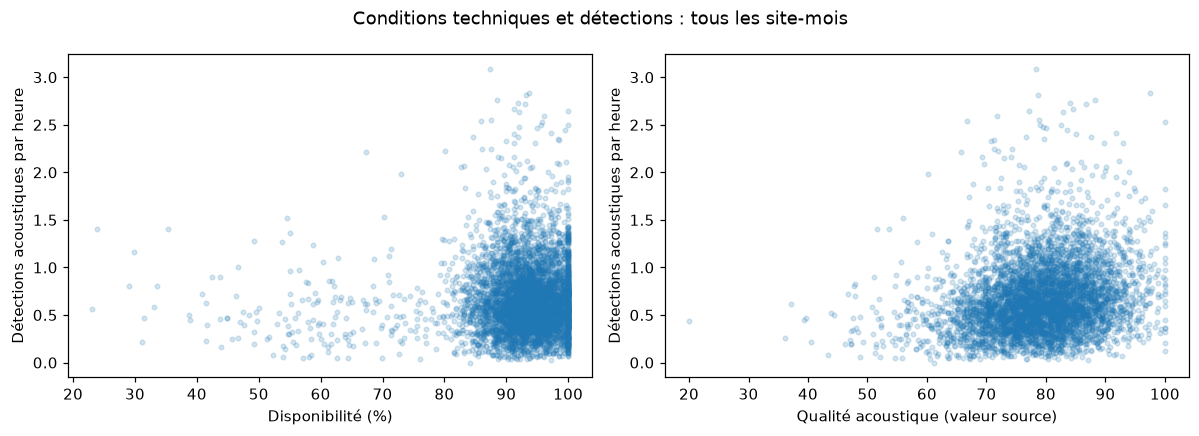

In [47]:
variables_techniques_ecology = [
    'uptime_pct', 'acoustic_quality', 'detections_acoustiques_par_heure'
]
for methode in ['pearson', 'spearman']:
    print(methode.capitalize())
    display(df_bats_appareils[variables_techniques_ecology].corr(method=methode).round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for axe, variable, libelle in zip(
    axes, ['uptime_pct', 'acoustic_quality'],
    ['Disponibilité (%)', 'Qualité acoustique (valeur source)']
):
    axe.scatter(df_bats_appareils[variable],
                df_bats_appareils['detections_acoustiques_par_heure'], s=9, alpha=.18)
    axe.set(xlabel=libelle, ylabel='Détections acoustiques par heure')
fig.suptitle('Conditions techniques et détections : tous les site-mois')
plt.tight_layout()
plt.show()

Les détections sont très peu liées à la disponibilité dans ces données regroupées
(Pearson 0,037 ; Spearman 0,014), et faiblement liées à la qualité acoustique
(0,208 et 0,221). Les nuages montrent une forte dispersion à disponibilité élevée.
Une relation faible sur l'ensemble des sites n'exclut pas une panne lors d'un épisode précis.
Inversement, une bonne disponibilité mensuelle ne garantit pas une détection
constante. Nous ne divisons pas les comptages par la disponibilité ou la qualité :
aucune calibration ne justifie une telle « correction ».

### 5. Suivi des vergers — `orchard_surveys.csv`

Nous cherchons si l'activité des chauves-souris accompagne la floraison,
la nouaison et le rendement, sans supposer une relation causale. Nous vérifions
d'abord les identifiants, unités, valeurs absentes et périodes. Les vergers
ne concernent qu'une partie des sites : une absence de relevé ailleurs
ne signifie ni rendement nul ni mesure manquante à imputer.

In [48]:
df_vergers_brut = pd.read_csv('data/ecology/orchard_surveys.csv')
print('Dimensions :', df_vergers_brut.shape)
print('Doublons exacts :', int(df_vergers_brut.duplicated().sum()))
print('Identifiants répétés :', int(df_vergers_brut['orchard_survey_id'].duplicated().sum()))
display(pd.DataFrame({
    'type': df_vergers_brut.dtypes.astype(str),
    'manquants': df_vergers_brut.isna().sum(),
    'valeurs_distinctes': df_vergers_brut.nunique()
}))
display(df_vergers_brut.head(3))
display(df_vergers_brut.loc[df_vergers_brut.duplicated(keep=False)].sort_values('orchard_survey_id'))

Dimensions : (1250, 11)
Doublons exacts : 2
Identifiants répétés : 2


,type,manquants,valeurs_distinctes
orchard_survey_id,str,0,1248
site_code,str,0,16
survey_period,str,0,78
orchard_area_ha,str,0,21
durian_flower_density,str,0,589
fruit_set_rate_pct,float64,0,389
durian_yield_kg,str,0,1246
other_pollinator_activity,float64,0,381
fertilizer_use_index,str,0,418
irrigation_level,float64,0,377


,orchard_survey_id,site_code,survey_period,orchard_area_ha,durian_flower_density,fruit_set_rate_pct,durian_yield_kg,other_pollinator_activity,fertilizer_use_index,irrigation_level,agricultural_disturbance_note
0,ORC-0000001,AVL-MAR,2019-01-01,24.1,40.3,34.7,20400.8,55.2,27.1,38.4,NaN
1,ORC-0000002,AVL-MAR,2019-02-01,24.1,33.8,41.6,17712.7,63.8,44.2,41.6,NaN
2,ORC-0000003,AVL-MAR,2019-03-01,24.1,55.1,57.3,28900.5,77.4,35.2,45.6,NaN


,orchard_survey_id,site_code,survey_period,orchard_area_ha,durian_flower_density,fruit_set_rate_pct,durian_yield_kg,other_pollinator_activity,fertilizer_use_index,irrigation_level,agricultural_disturbance_note
892,ORC-0000893,AVL-NMQ,2021-11-01,31.3,60.2,58.7,36453.0,70.7,47.9,49.3,NaN
1248,ORC-0000893,AVL-NMQ,2021-11-01,31.3,60.2,58.7,36453.0,70.7,47.9,49.3,NaN
1189,ORC-0001190,TMB-HQL,2020-08-01,44.2,33.4,33.3,27989.9,44.0,39.0,42.3,NaN
1249,ORC-0001190,TMB-HQL,2020-08-01,44.2,33.4,33.3,27989.9,44.0,39.0,42.3,NaN


Nous supprimons seulement les deux répétitions exactes, pour ne pas compter
deux fois les mêmes relevés. Un identifiant encore répété après cette opération
nécessiterait un examen, et non une sélection arbitraire de sa première ligne.
Les données brutes restent disponibles.

In [49]:
df_vergers = df_vergers_brut.drop_duplicates().reset_index(drop=True).copy()
assert df_vergers['orchard_survey_id'].is_unique
unites_vergers = {
    'orchard_area_ha': 'ha', 'durian_flower_density': None,
    'fruit_set_rate_pct': None, 'durian_yield_kg': 'kg',
    'other_pollinator_activity': None, 'fertilizer_use_index': None,
    'irrigation_level': None
}
print('Relevés conservés :', len(df_vergers))
for colonne in unites_vergers:
    valeurs = df_vergers[colonne].astype('string').str.strip()
    non_convertibles = valeurs.notna() & pd.to_numeric(valeurs, errors='coerce').isna()
    if non_convertibles.any():
        print(colonne, ':', int(non_convertibles.sum()), 'écritures à convertir')
        display(valeurs.loc[non_convertibles].value_counts().to_frame('occurrences'))
print('Notes avant harmonisation :')
display(df_vergers['agricultural_disturbance_note'].value_counts(dropna=False))

Relevés conservés : 1248
orchard_area_ha : 5 écritures à convertir
durian_flower_density : 4 écritures à convertir
durian_yield_kg : 5 écritures à convertir
fertilizer_use_index : 4 écritures à convertir
Notes avant harmonisation :


,occurrences
orchard_area_ha,
59.7 ha,1
54.7 ha,1
6.0 ha,1
31.3 ha,1
44.2 ha,1


,occurrences
durian_flower_density,
"48,4",1
"49,7",1
"49,5",1
"71,2",1


,occurrences
durian_yield_kg,
63290.0 kg,1
69487.6 kg,1
116624.0 kg,1
7641.7 kg,1
37441.2 kg,1


,occurrences
fertilizer_use_index,
"50,1",1
"46,8",1
"44,4",1
"29,8",1


agricultural_disturbance_note
NaN                                    1225
storm-related flower loss                15
  storm-related  flower  loss             3
elevated pesticide application            3
  elevated  pesticide  application        2
Name: count, dtype: int64

Les écritures observées contiennent des virgules décimales et des suffixes
`ha` ou `kg`, cohérents avec les colonnes. Nous corrigeons uniquement ces formes,
sans changer d'unité. Toute autre écriture provoquera une erreur.
Les espaces répétés des notes sont harmonisés ; leur contenu n'est pas réécrit.
Une note absente ne prouve pas l'absence de perturbation agricole.

In [50]:
import re

def numerique_ecology(serie, unite=None):
    valeurs = serie.astype('string').str.strip().str.replace(',', '.', regex=False)
    if unite is not None:
        valeurs = valeurs.str.replace(r'\s+' + re.escape(unite) + r'$', '', regex=True)
    resultat = pd.to_numeric(valeurs, errors='raise')
    assert resultat.isna().equals(serie.isna())
    return resultat

def categorie_ecology(serie):
    return serie.astype('string').str.replace(r'\s+', ' ', regex=True).str.strip().str.lower()

for colonne, unite in unites_vergers.items():
    df_vergers[colonne] = numerique_ecology(df_vergers[colonne], unite)
notes_vergers_avant = df_vergers['agricultural_disturbance_note'].copy()
df_vergers['agricultural_disturbance_note'] = categorie_ecology(notes_vergers_avant)
df_vergers['survey_period'] = pd.to_datetime(
    df_vergers['survey_period'], format='%Y-%m-%d', errors='raise'
)
df_vergers['mois_releve'] = df_vergers['survey_period'].dt.to_period('M')
display(pd.DataFrame({'type': df_vergers.dtypes.astype(str),
                      'manquants': df_vergers.isna().sum()}))
display(df_vergers['agricultural_disturbance_note'].value_counts(dropna=False))

,type,manquants
orchard_survey_id,str,0
site_code,str,0
survey_period,datetime64[us],0
orchard_area_ha,Float64,0
durian_flower_density,Float64,0
fruit_set_rate_pct,Float64,0
durian_yield_kg,Float64,0
other_pollinator_activity,Float64,0
fertilizer_use_index,Float64,0
irrigation_level,Float64,0


agricultural_disturbance_note
<NA>                              1225
storm-related flower loss           18
elevated pesticide application       5
Name: count, dtype: Int64

### Cohérence et couverture des vergers

Une surface doit être strictement positive pour calculer un rendement par hectare.
Les autres mesures sont contrôlées comme non négatives, et le taux déclaré
en pourcentage doit appartenir à [0 ; 100]. Ces bornes ne valident pas à elles
seules l'échelle des petites valeurs. Nous vérifions aussi la couverture
des sites classés « orchard monitoring », plutôt que d'exiger 64 sites agricoles.

In [51]:
assert df_vergers['survey_period'].notna().all()
assert not df_vergers.duplicated(['site_code', 'mois_releve']).any()
controles_vergers = pd.Series({
    'surface_nulle_ou_negative': df_vergers['orchard_area_ha'].le(0).sum(),
    'taux_hors_0_100': (~df_vergers['fruit_set_rate_pct'].between(0, 100)).sum(),
    'autres_mesures_negatives': df_vergers[list(unites_vergers)].lt(0).sum().sum()
})
display(controles_vergers.to_frame('nombre'))
assert controles_vergers.eq(0).all()
sites_vergers_attendus = pd.Index(
    df_sites.loc[df_sites['site_category'].eq('orchard monitoring'), 'site_code']
)
assert set(df_vergers['site_code']) == set(sites_vergers_attendus)
assert df_vergers['mois_releve'].isin(mois_attendus).all()
couverture_vergers = pd.crosstab(df_vergers['site_code'], df_vergers['mois_releve']).reindex(
    index=sites_vergers_attendus, columns=mois_attendus, fill_value=0
)
print('Sites / mois attendus :', len(sites_vergers_attendus), len(mois_attendus))
print('Site-mois absents :', int(couverture_vergers.eq(0).sum().sum()))
assert couverture_vergers.eq(1).all().all()
df_vergers['rendement_kg_ha'] = df_vergers['durian_yield_kg'] / df_vergers['orchard_area_ha']
display(df_vergers[list(unites_vergers) + ['rendement_kg_ha']].describe().T.round(2))

Sites / mois attendus : 16 78
Site-mois absents : 0


,nombre
surface_nulle_ou_negative,0
taux_hors_0_100,0
autres_mesures_negatives,0


,count,mean,std,min,25%,50%,75%,max
orchard_area_ha,1248.0,45.53,18.98,6.0,29.9,49.35,59.32,84.7
durian_flower_density,1248.0,63.15,22.37,17.0,45.98,58.55,84.02,100.0
fruit_set_rate_pct,1248.0,53.2,10.22,0.47,46.9,52.8,59.4,87.7
durian_yield_kg,1248.0,47150.89,21479.64,3971.3,31192.9,46774.65,62028.28,118638.7
other_pollinator_activity,1248.0,59.44,9.37,27.9,53.3,59.5,65.7,93.7
fertilizer_use_index,1248.0,38.32,10.73,5.0,31.0,38.1,45.52,74.4
irrigation_level,1248.0,39.97,9.12,11.5,33.8,39.5,45.5,81.0
rendement_kg_ha,1248.0,1041.19,197.39,392.78,905.85,1038.25,1164.74,1815.73


### Une échelle à vérifier, pas à corriger arbitrairement

Les 16 sites agricoles ont chacun 78 relevés. Nous examinons les taux de nouaison
strictement entre 0 et 1 : ils peuvent être de faibles pourcentages réels ou
des proportions saisies dans une colonne en pourcentage. La borne [0 ; 100]
ne permet pas de trancher. Nous les conservons, les signalons et comparons
ensuite l'association avec et sans ces lignes, sans les multiplier par 100.

Taux strictement entre 0 et 1 : 8


,orchard_survey_id,site_code,mois_releve,fruit_set_rate_pct
269,ORC-0000270,AVL-TRP,2021-12,0.568
412,ORC-0000413,AVL-GRB,2020-11,0.543
454,ORC-0000455,AVL-GRB,2024-05,0.549
716,ORC-0000717,AVL-YAU,2020-03,0.561
718,ORC-0000719,AVL-YAU,2020-05,0.595
919,ORC-0000920,AVL-NMQ,2024-02,0.467
1060,ORC-0001061,TMB-BRC,2022-11,0.581
1180,ORC-0001181,TMB-HQL,2019-11,0.555


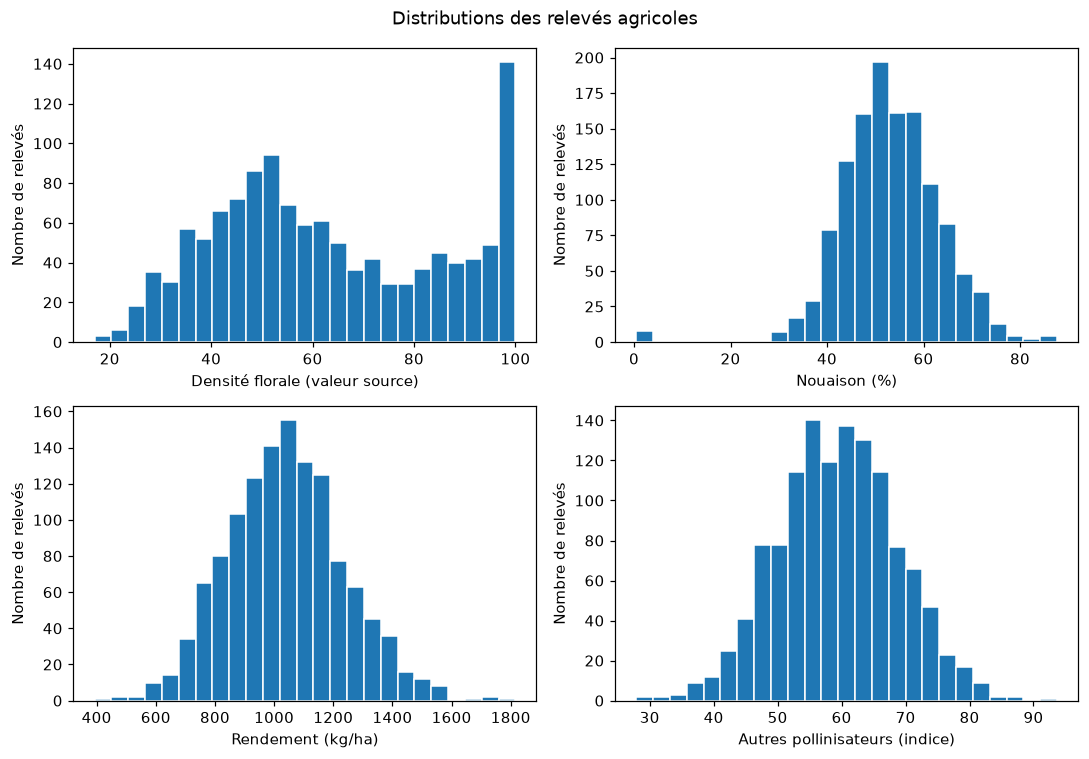

In [52]:
taux_vergers_a_verifier = df_vergers['fruit_set_rate_pct'].between(0, 1, inclusive='neither')
print('Taux strictement entre 0 et 1 :', int(taux_vergers_a_verifier.sum()))
display(df_vergers.loc[taux_vergers_a_verifier,
    ['orchard_survey_id', 'site_code', 'mois_releve', 'fruit_set_rate_pct']])
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for axe, variable, titre in zip(axes.flat,
    ['durian_flower_density', 'fruit_set_rate_pct', 'rendement_kg_ha', 'other_pollinator_activity'],
    ['Densité florale (valeur source)', 'Nouaison (%)', 'Rendement (kg/ha)', 'Autres pollinisateurs (indice)']):
    axe.hist(df_vergers[variable].astype(float), bins=25, edgecolor='white')
    axe.set(xlabel=titre, ylabel='Nombre de relevés')
fig.suptitle('Distributions des relevés agricoles')
plt.tight_layout()
plt.show()

Le rendement médian vaut environ 1 038 kg/ha, avec la moitié des relevés
entre 906 et 1 165 kg/ha. La nouaison est centrée autour de 52,8 %, avec huit
valeurs séparées du reste de la distribution près de zéro. La densité florale
présente aussi une accumulation dans la classe haute, sans que l'histogramme
permette de dire si toutes ces valeurs valent exactement 100.

Le rendement par hectare évite de confondre superficie et production totale,
mais ne corrige ni la saison ni les pratiques agricoles. Les huit petits taux
restent une incertitude d'échelle. Les notes mentionnent des pertes florales liées
aux tempêtes (18 relevés) et une application accrue de pesticide (5).
Les 1 225 notes absentes ne sont pas remplacées par l'une de ces modalités.
Les relations avec l'activité seront examinées après la jointure, puis
comparées à leurs variations calendaires au cours 5.

### 6. Rapports de terrain — `environmental_field_reports.csv`

Une ligne représente un document, et non une mesure mensuelle.
Nous contrôlons sa structure et ses références avant l'analyse textuelle
du cours 6. Les rapports ne sont pas ajoutés directement aux relevés : plusieurs
documents pourraient citer une même mesure et multiplier les lignes.

In [53]:
df_rapports_brut = pd.read_csv('data/ecology/environmental_field_reports.csv')
print('Dimensions :', df_rapports_brut.shape)
print('Doublons exacts :', int(df_rapports_brut.duplicated().sum()))
print('Identifiants dupliqués :', int(df_rapports_brut['document_id'].duplicated().sum()))
display(pd.DataFrame({'type': df_rapports_brut.dtypes.astype(str),
    'manquants': df_rapports_brut.isna().sum(), 'valeurs_distinctes': df_rapports_brut.nunique()}))
for colonne in ['document_type', 'author_organization', 'publication_status']:
    print(colonne)
    display(df_rapports_brut[colonne].value_counts(dropna=False).to_frame('documents'))

Dimensions : (30, 12)
Doublons exacts : 0
Identifiants dupliqués : 0
document_type
author_organization
publication_status


,type,manquants,valeurs_distinctes
document_id,str,0,30
site_code,str,0,16
document_date,str,0,30
document_type,str,0,5
author_name,str,1,28
author_organization,str,0,10
reporting_period,str,0,25
title,str,0,30
text,str,0,30
related_survey_id,str,0,30


,documents
document_type,
ecological_incident_report,6
field_observation,6
monitoring_report,6
cave_access_note,6
sensor_quality_report,6


,documents
author_organization,
Horizon Field Research Cooperative,6
Avelora Agricultural Resilience Agency,5
Threshold Earth Observatory,5
Pollinator Justice Network,4
Belen Agro-Industries,4
Asterion Clinical Institute,2
Varlan Natural History Circle,1
Bell Conservation Survey,1
Marot Ecological Policy Office,1


,documents
publication_status,
restricted,12
public,10
internal,8


Nous conservons le texte original et les identifiants. Les dates du document
et les périodes de reporting sont converties séparément : une date de publication
n'est pas la date de chaque observation décrite. Nous contrôlons les références
de relevé et d'appareil ainsi que la concordance des sites et des mois.
Une discordance est signalée, pas corrigée en déplaçant une date pour ajuster le récit.

In [54]:
df_rapports = df_rapports_brut.drop_duplicates().copy()
assert df_rapports['document_id'].is_unique
df_rapports['document_date'] = pd.to_datetime(df_rapports['document_date'], format='%Y-%m-%d', errors='raise')
df_rapports['reporting_period'] = pd.to_datetime(df_rapports['reporting_period'], format='%Y-%m', errors='raise').dt.to_period('M')
print('Dimensions des documents :', df_rapports.shape)
liens_rapports_ecology = df_rapports.merge(
    df_bats[['survey_id', 'site_code', 'survey_start', 'mois_releve']],
    left_on='related_survey_id', right_on='survey_id', how='left',
    validate='many_to_one', suffixes=('_document', '_releve'), indicator=True
)
liens_rapports_ecology['releve_trouve'] = liens_rapports_ecology['_merge'].eq('both')
liens_rapports_ecology['site_concordant'] = liens_rapports_ecology['site_code_document'].eq(liens_rapports_ecology['site_code_releve'])
liens_rapports_ecology['mois_concordant'] = liens_rapports_ecology['reporting_period'].eq(liens_rapports_ecology['mois_releve'])
liens_rapports_ecology['document_avant_releve'] = liens_rapports_ecology['document_date'].lt(liens_rapports_ecology['survey_start'])
references_appareil_ecology = df_appareils[['site_code', 'device_reference']].drop_duplicates()
liens_appareil_rapports = df_rapports.merge(references_appareil_ecology, left_on=['site_code', 'related_device_reference'], right_on=['site_code', 'device_reference'], how='left', validate='many_to_one', indicator=True)
print('Contrôle des références documentaires :')
display(liens_rapports_ecology[['releve_trouve', 'site_concordant', 'mois_concordant', 'document_avant_releve']].sum().to_frame('nombre_documents'))
print('Références site-appareil retrouvées :', liens_appareil_rapports['_merge'].eq('both').sum())
display(liens_rapports_ecology[['document_id', 'site_code_document', 'document_date', 'related_survey_id', 'survey_start', 'mois_concordant', 'document_avant_releve']].head(6))

Dimensions des documents : (30, 12)
Contrôle des références documentaires :
Références site-appareil retrouvées : 30


,nombre_documents
releve_trouve,30
site_concordant,30
mois_concordant,2
document_avant_releve,15


,document_id,site_code_document,document_date,related_survey_id,survey_start,mois_concordant,document_avant_releve
0,EFR-510088,KNT-KES,2024-04-02,BAT-0000064,2024-04-05 18:00:00,True,True
1,EFR-510082,KNT-JAK,2019-04-01,BAT-0001000,2024-04-05 18:00:00,False,True
2,EFR-510035,KNT-JQG,2022-09-08,BAT-0001037,2020-11-05 18:00:00,False,False
3,EFR-510007,KNT-JQG,2025-02-15,BAT-0001074,2023-12-05 18:00:00,False,False
4,EFR-510031,KNT-VLB,2020-07-22,BAT-0001111,2020-07-05 18:00:00,True,False
5,EFR-510020,KNT-VLB,2023-12-02,BAT-0001148,2023-08-05 18:00:00,False,False


Les 30 références de relevé et les 30 couples site-appareil sont retrouvés.
Cependant, seuls 2 rapports sur 30 portent sur le même mois que le relevé cité,
et 15 documents sont datés avant ce relevé. Une référence peut désigner un relevé
historique ou comparatif, mais un document antérieur à son relevé cité pose une
question de chronologie. Nous ne synchronisons donc pas automatiquement tous
les rapports avec les mesures à partir du seul mois documentaire.

Le rapport d'incident `EFR-510088`, intitulé « Post-Access Ecological Incident
at KNT-KES », motive une piste à vérifier, et non une conclusion statistique.
Son texte mentionne une baisse après un accès, des traces de manipulation
et plusieurs explications alternatives. Nous conservons cette origine
documentaire pour ne pas présenter le choix ultérieur de KNT-KES comme
une découverte aveugle des algorithmes.

In [55]:
def dates_heures_ecology(serie):
    valeurs = serie.astype('string').str.strip()
    resultat = pd.Series(pd.NaT, index=serie.index, dtype='datetime64[us]')
    formats = [
        (r'^\d{4}-', '%Y-%m-%dT%H:%M:%S'),
        (r'^\d{4}/', '%Y/%m/%d %H:%M:%S'),
        (r'^\d{2}/', '%d/%m/%Y %H:%M:%S'),
        (r'^\d{2}-[A-Za-z]{3}-', '%d-%b-%Y %H:%M:%S')
    ]
    for motif, format_date in formats:
        masque = valeurs.str.match(motif, na=False)
        resultat.loc[masque] = pd.to_datetime(valeurs.loc[masque], format=format_date, errors='raise')
    if resultat.isna().any():
        raise ValueError('Dates/heures absentes ou formats non reconnus : ' + str(valeurs[resultat.isna()].unique()))
    return resultat

unites_environnement = {c: None for c in variables_mesure_env}

### Table commune et relations avec les conditions de collecte

Les mesures de chauves-souris, la météo et les appareils sont reliés par
`site_code` et mois. La validation un-à-un empêche les multiplications de lignes.
Les vergers sont ajoutés seulement pour les sites concernés. Les absences de
données de verger sur les autres sites sont structurelles, pas des zéros.
Les données mensuelles des appareils ne constituent pas un journal de panne
pendant les seules heures du relevé : leur concordance temporelle reste grossière.

In [56]:
colonnes_env_ecology = ['site_code', 'mois_releve'] + list(unites_environnement) + ['weather_exception_code']
colonnes_app_ecology = ['site_code', 'mois_releve', 'device_reference', 'uptime_pct', 'acoustic_quality', 'fault_code', 'maintenance_type', 'maintenance_provider']
ecologie_mensuelle = df_bats_enrichi.merge(df_environnement[colonnes_env_ecology], on=['site_code', 'mois_releve'], how='left', validate='one_to_one', indicator='_lien_env')
ecologie_mensuelle = ecologie_mensuelle.merge(df_appareils[colonnes_app_ecology], on=['site_code', 'mois_releve'], how='left', validate='one_to_one', indicator='_lien_app')
assert len(ecologie_mensuelle) == len(df_bats)
assert ecologie_mensuelle['_lien_env'].eq('both').all()
assert ecologie_mensuelle['_lien_app'].eq('both').all()
ecologie_mensuelle = ecologie_mensuelle.drop(columns=['_lien_env', '_lien_app'])
vergers_analyses_ecology = df_vergers.merge(ecologie_mensuelle[['site_code', 'mois_releve', 'observations_par_heure', 'detections_acoustiques_par_heure']], on=['site_code', 'mois_releve'], how='left', validate='one_to_one', indicator=True)
assert vergers_analyses_ecology['_merge'].eq('both').all()
assert set(df_vergers['site_code']) == set(df_sites.loc[df_sites['site_category'].eq('orchard monitoring'), 'site_code'])
print('Table commune :', ecologie_mensuelle.shape, '; relevés vergers reliés :', len(vergers_analyses_ecology))
variables_conditions_ecology = ['observations_par_heure', 'detections_acoustiques_par_heure', 'rainfall_mm', 'mean_temperature_c', 'weather_interference', 'uptime_pct', 'acoustic_quality', 'habitat_disturbance_index']
correlations_conditions_ecology = ecologie_mensuelle[variables_conditions_ecology].corr(method='spearman')
for methode in ['pearson', 'spearman']:
    print('Conditions de collecte :', methode)
    display(ecologie_mensuelle[variables_conditions_ecology].corr(method=methode).loc[['observations_par_heure', 'detections_acoustiques_par_heure']].round(3))
correlations_vergers_ecology = vergers_analyses_ecology[['observations_par_heure', 'fruit_set_rate_pct', 'rendement_kg_ha', 'durian_flower_density', 'other_pollinator_activity', 'fertilizer_use_index']].corr(method='spearman')
for methode in ['pearson', 'spearman']:
    print('Vergers :', methode)
    display(vergers_analyses_ecology[['observations_par_heure', 'fruit_set_rate_pct', 'rendement_kg_ha', 'durian_flower_density', 'other_pollinator_activity', 'fertilizer_use_index']].corr(method=methode).round(3))

Table commune : (4992, 35) ; relevés vergers reliés : 1248
Conditions de collecte : pearson
Conditions de collecte : spearman
Vergers : pearson
Vergers : spearman


,observations_par_heure,detections_acoustiques_par_heure,rainfall_mm,mean_temperature_c,weather_interference,uptime_pct,acoustic_quality,habitat_disturbance_index
observations_par_heure,1.000,0.743,-0.010,0.163,-0.019,-0.033,-0.015,-0.393
detections_acoustiques_par_heure,0.743,1.000,-0.136,0.184,-0.169,0.037,0.208,-0.389


,observations_par_heure,detections_acoustiques_par_heure,rainfall_mm,mean_temperature_c,weather_interference,uptime_pct,acoustic_quality,habitat_disturbance_index
observations_par_heure,1.000,0.691,-0.012,0.150,-0.022,0.002,-0.002,-0.402
detections_acoustiques_par_heure,0.691,1.000,-0.149,0.178,-0.180,0.014,0.221,-0.400


,observations_par_heure,fruit_set_rate_pct,rendement_kg_ha,durian_flower_density,other_pollinator_activity,fertilizer_use_index
observations_par_heure,1.000,0.461,0.475,0.263,0.339,-0.015
fruit_set_rate_pct,0.461,1.000,0.824,0.605,0.395,0.052
rendement_kg_ha,0.475,0.824,1.000,0.597,0.427,0.042
durian_flower_density,0.263,0.605,0.597,1.000,0.030,0.027
other_pollinator_activity,0.339,0.395,0.427,0.030,1.000,-0.024
fertilizer_use_index,-0.015,0.052,0.042,0.027,-0.024,1.000


,observations_par_heure,fruit_set_rate_pct,rendement_kg_ha,durian_flower_density,other_pollinator_activity,fertilizer_use_index
observations_par_heure,1.000,0.477,0.448,0.270,0.314,-0.039
fruit_set_rate_pct,0.477,1.000,0.895,0.653,0.414,0.036
rendement_kg_ha,0.448,0.895,1.000,0.595,0.401,0.036
durian_flower_density,0.270,0.653,0.595,1.000,0.029,0.022
other_pollinator_activity,0.314,0.414,0.401,0.029,1.000,-0.025
fertilizer_use_index,-0.039,0.036,0.036,0.022,-0.025,1.000


### Qualité, effort et couverture des six sources

Nous approfondissons les différences de collecte avant de comparer les sites.
L'objectif est de vérifier si un résultat peut venir d'une différence d'effort,
de qualité ou de couverture, plutôt que d'une différence écologique.
Les absences structurelles des vergers sont distinguées des valeurs manquantes.

In [57]:
audit_sources_ecology = pd.DataFrame([
    {'fichier': 'sites', 'lignes_brutes': len(df_sites_brut), 'lignes_nettoyees': len(df_sites), 'sites': df_sites['site_code'].nunique()},
    {'fichier': 'chauves_souris', 'lignes_brutes': len(df_bats_brut), 'lignes_nettoyees': len(df_bats), 'sites': df_bats['site_code'].nunique()},
    {'fichier': 'environnement', 'lignes_brutes': len(df_environnement_brut), 'lignes_nettoyees': len(df_environnement), 'sites': df_environnement['site_code'].nunique()},
    {'fichier': 'appareils', 'lignes_brutes': len(df_appareils_brut), 'lignes_nettoyees': len(df_appareils), 'sites': df_appareils['site_code'].nunique()},
    {'fichier': 'vergers', 'lignes_brutes': len(df_vergers_brut), 'lignes_nettoyees': len(df_vergers), 'sites': df_vergers['site_code'].nunique()},
    {'fichier': 'rapports', 'lignes_brutes': len(df_rapports_brut), 'lignes_nettoyees': len(df_rapports), 'sites': df_rapports['site_code'].nunique()}
])
audit_sources_ecology['doublons_exacts_retires'] = audit_sources_ecology['lignes_brutes'] - audit_sources_ecology['lignes_nettoyees']
display(audit_sources_ecology)
qualite_collecte_ecology = ecologie_mensuelle.groupby('survey_quality').agg(
    relevements=('survey_id', 'size'), heures_medianes=('observation_hours', 'median'),
    disponibilite_mediane=('uptime_pct', 'median'), qualite_acoustique_mediane=('acoustic_quality', 'median'),
    meteo_mediane=('weather_interference', 'median'), observations_h_medianes=('observations_par_heure', 'median'),
    detections_h_medianes=('detections_acoustiques_par_heure', 'median')
)
display(qualite_collecte_ecology.round(3))
couverture_autres_sources_ecology = []
for nom, tableau in [('environnement', df_environnement), ('appareils', df_appareils), ('vergers', df_vergers)]:
    couverture = pd.crosstab(tableau['site_code'], tableau['mois_releve']).reindex(columns=mois_attendus, fill_value=0)
    couverture_autres_sources_ecology.append({'source': nom, 'sites': len(couverture), 'mois_absents_sur_sites_concernes': int(couverture.eq(0).sum().sum()), 'site_mois_multiples': int(couverture.gt(1).sum().sum())})
display(pd.DataFrame(couverture_autres_sources_ecology))

,fichier,lignes_brutes,lignes_nettoyees,sites,doublons_exacts_retires
0,sites,64,64,64,0
1,chauves_souris,4994,4992,64,2
2,environnement,4994,4992,64,2
3,appareils,4994,4992,64,2
4,vergers,1250,1248,16,2
5,rapports,30,30,16,0


,relevements,heures_medianes,disponibilite_mediane,qualite_acoustique_mediane,meteo_mediane,observations_h_medianes,detections_h_medianes
survey_quality,,,,,,,
acceptable,2166,29.0,93.4,73.7,43.6,0.422,0.556
high,2688,32.0,94.3,83.9,31.4,0.427,0.668
limited,138,19.05,58.5,56.7,36.5,0.411,0.455


,source,sites,mois_absents_sur_sites_concernes,site_mois_multiples
0,environnement,64,0,0
1,appareils,64,0,0
2,vergers,16,0,0


Les relevés de qualité limitée présentent une disponibilité médiane de 58,5 %, contre plus de 93 % dans les deux autres classes. Leur indice acoustique médian est plus faible (0,455 contre 0,668 pour `high`), tandis que l'indice visuel varie peu. Cela motive les contrôles de sensibilité, sans autoriser une correction automatique des comptages. Les trois séries mensuelles complémentaires n'ont ni mois absent ni site-mois multiple sur leurs sites respectifs.

### Relations globales, entre sites et à l'intérieur des sites

Une corrélation globale peut mélanger deux phénomènes : des sites durablement
différents et des changements au cours du temps sur un même site. Nous comparons
donc la corrélation regroupée, celle des médianes par site et celle obtenue après
soustraction de la médiane de chaque site. Ce centrage ne retire pas la saison
et ne transforme pas l'analyse descriptive en expérience causale.

,tous_les_releves_spearman,medianes_64_sites_spearman,deviations_intra_site_spearman
detections_acoustiques_par_heure,0.691,0.969,0.405
rainfall_mm,-0.012,-0.110,0.029
mean_temperature_c,0.150,0.020,0.251
habitat_disturbance_index,-0.402,-0.498,-0.177
uptime_pct,0.002,-0.153,0.015
acoustic_quality,-0.002,-0.020,-0.008


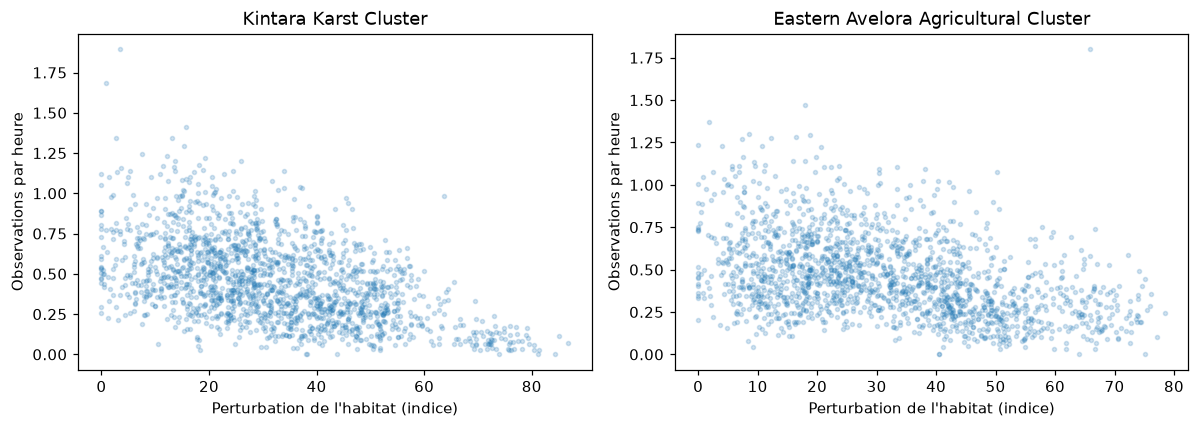

In [58]:
variables_contextes_ecology = ['observations_par_heure', 'detections_acoustiques_par_heure', 'rainfall_mm', 'mean_temperature_c', 'habitat_disturbance_index', 'uptime_pct', 'acoustic_quality']
medians_sites_conditions_ecology = ecologie_mensuelle.groupby('site_code')[variables_contextes_ecology].median()
deviations_sites_ecology = ecologie_mensuelle[variables_contextes_ecology] - ecologie_mensuelle.groupby('site_code')[variables_contextes_ecology].transform('median')
comparaison_correlations_ecology = pd.DataFrame({
    'tous_les_releves_spearman': ecologie_mensuelle[variables_contextes_ecology].corr(method='spearman')['observations_par_heure'],
    'medianes_64_sites_spearman': medians_sites_conditions_ecology.corr(method='spearman')['observations_par_heure'],
    'deviations_intra_site_spearman': deviations_sites_ecology.corr(method='spearman')['observations_par_heure']
})
display(comparaison_correlations_ecology.drop(index='observations_par_heure').round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for axe, region in zip(axes, ['Kintara Karst Cluster', 'Eastern Avelora Agricultural Cluster']):
    sous_ensemble = ecologie_mensuelle.loc[ecologie_mensuelle['region'].eq(region)]
    axe.scatter(sous_ensemble['habitat_disturbance_index'], sous_ensemble['observations_par_heure'], s=7, alpha=.2)
    axe.set(xlabel="Perturbation de l'habitat (indice)", ylabel='Observations par heure', title=region)
plt.tight_layout()
plt.show()

La corrélation observations–détections passe de 0,691 globalement à 0,405 après centrage par site, alors qu'elle atteint 0,969 entre les médianes des sites. Une grande part du lien concerne donc les différences durables entre sites. La perturbation de l'habitat reste négativement associée à l'activité après centrage, mais plus faiblement (−0,177 contre −0,402). Aucun de ces coefficients n'isole un effet causal.

### Nouaison, rendement et explications agricoles concurrentes

Le lien entre chauves-souris et vergers doit être examiné avec les fleurs,
les autres pollinisateurs, les pesticides et les notes de perturbation.
Les tableaux suivants décrivent les observations disponibles. Les notes non
renseignées ne sont pas une preuve d'absence de perturbation.

In [59]:
vergers_contextuels_ecology = df_vergers.merge(ecologie_mensuelle[['site_code', 'mois_releve', 'region', 'rainfall_mm', 'pesticide_index', 'observations_par_heure', 'detections_acoustiques_par_heure']], on=['site_code', 'mois_releve'], validate='one_to_one')
vergers_contextuels_ecology['note_affichee'] = vergers_contextuels_ecology['agricultural_disturbance_note'].fillna('non renseignée')
vergers_contextuels_ecology['echelle_nouaison_a_verifier'] = vergers_contextuels_ecology['fruit_set_rate_pct'].gt(0) & vergers_contextuels_ecology['fruit_set_rate_pct'].lt(1)
print('Taux entre 0 et 1 dans une colonne déclarée en pourcentage :', vergers_contextuels_ecology['echelle_nouaison_a_verifier'].sum())
resume_notes_vergers_ecology = vergers_contextuels_ecology.groupby('note_affichee').agg(
    nombre_releves=('orchard_survey_id', 'size'), nombre_sites=('site_code', 'nunique'),
    nouaison_mediane=('fruit_set_rate_pct', 'median'), rendement_median_kg_ha=('rendement_kg_ha', 'median'),
    pesticide_median=('pesticide_index', 'median'), observations_h_medianes=('observations_par_heure', 'median')
)
display(resume_notes_vergers_ecology.round(3))
print('Relevés de nouaison les plus faibles, conservés pour examen :')
display(vergers_contextuels_ecology.nsmallest(8, 'fruit_set_rate_pct')[['site_code', 'mois_releve', 'fruit_set_rate_pct', 'durian_flower_density', 'pesticide_index', 'agricultural_disturbance_note']])
vergers_medians_site_ecology = vergers_contextuels_ecology.groupby('site_code')[['observations_par_heure', 'fruit_set_rate_pct', 'rendement_kg_ha']].median()
vergers_deviations_ecology = vergers_contextuels_ecology[['observations_par_heure', 'fruit_set_rate_pct', 'rendement_kg_ha']] - vergers_contextuels_ecology.groupby('site_code')[['observations_par_heure', 'fruit_set_rate_pct', 'rendement_kg_ha']].transform('median')
display(pd.DataFrame({
    'correlation_globale': vergers_contextuels_ecology[['observations_par_heure', 'fruit_set_rate_pct', 'rendement_kg_ha']].corr(method='spearman')['observations_par_heure'],
    'correlation_entre_sites': vergers_medians_site_ecology.corr(method='spearman')['observations_par_heure'],
    'correlation_deviations_intra_site': vergers_deviations_ecology.corr(method='spearman')['observations_par_heure']
}).round(3))


Taux entre 0 et 1 dans une colonne déclarée en pourcentage : 8
Relevés de nouaison les plus faibles, conservés pour examen :


,nombre_releves,nombre_sites,nouaison_mediane,rendement_median_kg_ha,pesticide_median,observations_h_medianes
note_affichee,,,,,,
elevated pesticide application,5,2,46.2,986.924,68.20,0.137
non renseignée,1225,16,53.1,1039.805,38.00,0.478
storm-related flower loss,18,6,45.3,857.573,51.55,0.198


,site_code,mois_releve,fruit_set_rate_pct,durian_flower_density,pesticide_index,agricultural_disturbance_note
919,AVL-NMQ,2024-02,0.467,35.1,30.2,<NA>
412,AVL-GRB,2020-11,0.543,49.4,45.2,<NA>
454,AVL-GRB,2024-05,0.549,88.5,66.4,elevated pesticide application
1180,TMB-HQL,2019-11,0.555,62.7,32.8,<NA>
716,AVL-YAU,2020-03,0.561,61.8,40.1,<NA>
269,AVL-TRP,2021-12,0.568,56.3,18.5,<NA>
1060,TMB-BRC,2022-11,0.581,33.9,8.0,<NA>
718,AVL-YAU,2020-05,0.595,87.3,47.0,<NA>


,correlation_globale,correlation_entre_sites,correlation_deviations_intra_site
observations_par_heure,1.000,1.000,1.000
fruit_set_rate_pct,0.477,0.682,0.374
rendement_kg_ha,0.448,0.656,0.332


Les notes de tempête ou de pesticides accompagnent une activité médiane
plus faible, mais ne concernent que 18 et 5 relevés. Une note absente
ne signifie pas une absence de perturbation. Les huit taux de nouaison
inférieurs à 1 % sont conservés et font l'objet du diagnostic suivant.


### Sensibilité à l'échelle de huit taux de nouaison

Un pourcentage inférieur à 1 est possible : nous ne corrigeons donc pas
automatiquement ces huit valeurs. Un même tableau compare trois scénarios :
toutes les valeurs originales, exclusion des huit taux, et multiplication
hypothétique de ces seuls taux par 100 s'il s'agissait de proportions.

Nous calculons Pearson et Spearman pour distinguer la sensibilité de la relation
linéaire et celle des rangs. Aucun scénario ne modifie les tables originales.


In [60]:
masque_taux_a_verifier = vergers_analyses_ecology['fruit_set_rate_pct'].between(
    0, 1, inclusive='neither'
)
nouaison_hypothese_ecology = vergers_analyses_ecology['fruit_set_rate_pct'].where(
    ~masque_taux_a_verifier,
    vergers_analyses_ecology['fruit_set_rate_pct'] * 100
)
sensibilite_taux_vergers = []
for nom, selection, taux in [
    ('valeurs_originales', vergers_analyses_ecology, vergers_analyses_ecology['fruit_set_rate_pct']),
    ('sans_taux_a_verifier', vergers_analyses_ecology.loc[~masque_taux_a_verifier],
     vergers_analyses_ecology.loc[~masque_taux_a_verifier, 'fruit_set_rate_pct']),
    ('hypothese_taux_multiplies_par_100', vergers_analyses_ecology, nouaison_hypothese_ecology)
]:
    sensibilite_taux_vergers.append({
        'selection': nom, 'releves': len(selection),
        'pearson_activite_nouaison': selection['observations_par_heure'].corr(taux),
        'spearman_activite_nouaison': selection['observations_par_heure'].corr(taux, method='spearman')
    })
tableau_sensibilite_taux = pd.DataFrame(sensibilite_taux_vergers).set_index('selection')
sensibilite_echelle_nouaison_ecology = tableau_sensibilite_taux['spearman_activite_nouaison']
display(tableau_sensibilite_taux.round(3))


,releves,pearson_activite_nouaison,spearman_activite_nouaison
selection,,,
valeurs_originales,1248,0.461,0.477
sans_taux_a_verifier,1240,0.522,0.487
hypothese_taux_multiplies_par_100,1248,0.521,0.486


Sans les huit valeurs, Spearman passe de 0,477 à 0,487 et Pearson de 0,461
à 0,522. Sous l'hypothèse de multiplication par 100, Spearman vaut 0,486.
L'association positive persiste, mais sa forme linéaire est plus sensible
aux valeurs concernées. Cette stabilité ne résout pas leur unité et ne
démontre pas un effet propre des chauves-souris : la floraison et la saison
restent à examiner.


### Bilan du cours 1

Les six fichiers ont été examinés à leur propre granularité. Les identifiants
restent intacts, les répétitions exactes sont supprimées, les formats sont
harmonisés et les valeurs absentes ne sont pas inventées. La table commune
permet maintenant de vérifier les explications environnementales et techniques.

Les corrélations ne suffisent pas à départager saison, habitat et conditions
de collecte. Les observations répétées d'un même site et les variations
saisonnières peuvent produire des relations apparentes. Nous n'en déduisons
ni un effet causal des chauves-souris sur le rendement, ni une activité clandestine.

Dans les vergers, la corrélation de Spearman entre observations par heure et
nouaison vaut environ 0,477, et celle avec le rendement par hectare environ 0,448.
La densité florale, la saison et les autres pollinisateurs peuvent aussi intervenir.
Dans la table commune, les observations par heure sont peu corrélées globalement
à la météo et à la disponibilité. La relation avec l'indice de perturbation
de l'habitat est négative (environ −0,402). Ce sont des pistes de comparaison,
pas des effets isolés par une expérience ou un modèle causal.

## Cours 2 — Comparer les profils des sites

**Question.** Certains sites ont-ils des profils d'activité proches ?
Nous utilisons une ligne par site, et non 78 lignes considérées comme des sites
différents. Le profil retient les médianes des deux indices d'activité, leur
variabilité interquartile et le comptage médian des espèces de comparaison.
Ces dernières ne sont pas une population témoin expérimentale.

Nous vérifions les redondances, standardisons, puis comparons les profils par
distance euclidienne. Sur trois variables standardisées, elle mesure une
proximité de profil plutôt qu'une distance géographique. Les codes de site,
les coordonnées et les statuts ne participent pas à ce calcul. La PCA sert à visualiser. Un K-means exploratoire est
comparé pour plusieurs nombres de groupes, sans supposer que les groupes
correspondent aux régions ou à des catégories biologiques réelles.

Les médianes résument le niveau habituel d'un site en limitant l'influence
de quelques mois très élevés ; l'IQR conserve une information de dispersion.
Une moyenne serait un autre résumé, plus sensible aux pics, et aucun résumé
global ne remplace l'étude des baisses locales. Les variables retenues sont
standardisées pour comparer des écarts relatifs malgré leurs échelles différentes,
pas pour corriger les comptages. Cela revient à leur donner une même dispersion
de référence ; ce choix de pondération ne garantit pas leur même importance écologique.


In [61]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import pairwise_distances
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

profil_sites_ecology = ecologie_mensuelle.groupby('site_code').agg(
    observations_medianes=('observations_par_heure', 'median'),
    detections_medianes=('detections_acoustiques_par_heure', 'median'),
    variabilite_observations=('observations_par_heure', lambda x: x.quantile(.75) - x.quantile(.25)),
    especes_comparaison_medianes=('comparison_species_count', 'median')
)
correlation_profils_ecology = profil_sites_ecology.corr()
print('Pearson entre profils :')
display(correlation_profils_ecology.round(3))
print('Spearman entre profils :')
display(profil_sites_ecology.corr(method='spearman').round(3))
variables_profil_ecology = list(profil_sites_ecology.columns)
# Éviter de compter deux fois une information presque identique.
if abs(correlation_profils_ecology.loc['observations_medianes', 'detections_medianes']) > .90:
    variables_profil_ecology.remove('detections_medianes')
print('Variables retenues :', variables_profil_ecology)
assert profil_sites_ecology[variables_profil_ecology].notna().all().all()
assert profil_sites_ecology[variables_profil_ecology].std().gt(0).all()
scaler_sites_ecology = StandardScaler()
profils_standardises_ecology = pd.DataFrame(scaler_sites_ecology.fit_transform(profil_sites_ecology[variables_profil_ecology]), index=profil_sites_ecology.index, columns=variables_profil_ecology)
distances_sites_ecology = pd.DataFrame(pairwise_distances(profils_standardises_ecology), index=profil_sites_ecology.index, columns=profil_sites_ecology.index)
distances_voisins_ecology = distances_sites_ecology.to_numpy(copy=True)
np.fill_diagonal(distances_voisins_ecology, np.inf)
voisins_sites_ecology = pd.DataFrame({'site_voisin': profil_sites_ecology.index[np.argmin(distances_voisins_ecology, axis=1)], 'distance': distances_voisins_ecology.min(axis=1)}, index=profil_sites_ecology.index)
display(voisins_sites_ecology.head(8).round(3))

Pearson entre profils :
Spearman entre profils :
Variables retenues : ['observations_medianes', 'variabilite_observations', 'especes_comparaison_medianes']


,observations_medianes,detections_medianes,variabilite_observations,especes_comparaison_medianes
observations_medianes,1.000,0.985,0.833,0.427
detections_medianes,0.985,1.000,0.816,0.434
variabilite_observations,0.833,0.816,1.000,0.362
especes_comparaison_medianes,0.427,0.434,0.362,1.000


,observations_medianes,detections_medianes,variabilite_observations,especes_comparaison_medianes
observations_medianes,1.000,0.969,0.793,0.418
detections_medianes,0.969,1.000,0.765,0.418
variabilite_observations,0.793,0.765,1.000,0.323
especes_comparaison_medianes,0.418,0.418,0.323,1.000


,site_voisin,distance
site_code,,
AVL-ABG,KNT-TEX,0.144
AVL-ARU,KNT-GKR,0.409
AVL-BVM,TMB-WYT,0.387
AVL-BWK,AVL-ECJ,0.171
AVL-DER,TMB-WYT,0.114
AVL-ECJ,AVL-BWK,0.171
AVL-FNM,KNT-QWU,0.421
AVL-FNQ,AVL-GRB,0.173


### Regrouper les profils

Nous fixons quatre groupes pour une lecture exploratoire. Leurs effectifs et leurs médianes doivent être examinés avant de leur attribuer un sens. La PCA sert ensuite à visualiser les mêmes profils, pas à valider les groupes.

Profils isolés dans cette partition :
Variance expliquée par les deux axes : [0.704 0.241]


,nombre_sites
cluster_ecology,
0,33
1,12
2,1
3,18


,observations_medianes,detections_medianes,variabilite_observations,especes_comparaison_medianes
cluster_ecology,,,,
0,0.422,0.601,0.196,11.0
1,0.233,0.325,0.149,9.0
2,1.354,1.959,0.442,12.0
3,0.617,0.898,0.3,11.0


,observations_medianes,detections_medianes,variabilite_observations,especes_comparaison_medianes
site_code,,,,
TMB-BRC,1.354409,1.959277,0.442096,12.0


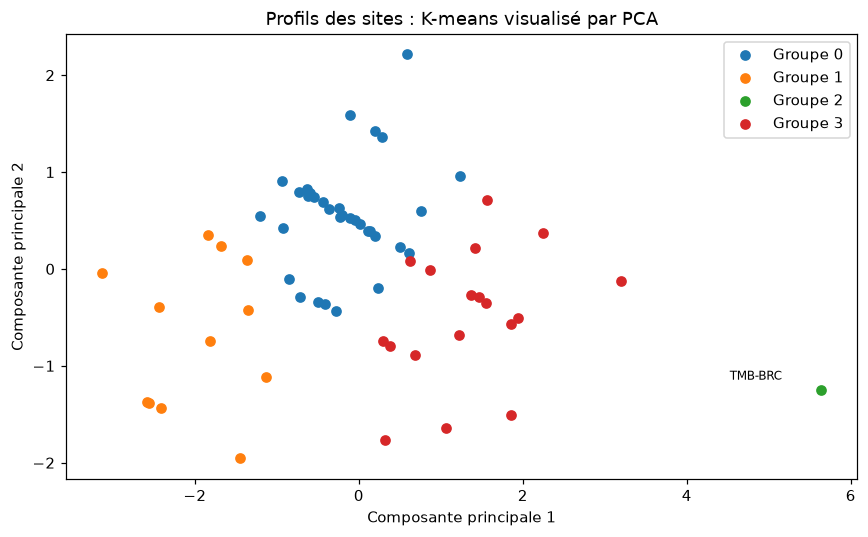

In [62]:
# K-means exige un nombre de groupes fixé avant l'apprentissage (cours 2).
# Quatre groupes donnent une lecture exploratoire ; ce choix n'est pas un optimum.
# Une coupe à trois groupes et le dendrogramme sont examinés ensuite.
k_sites_ecology = 4
modele_sites_ecology = KMeans(n_clusters=k_sites_ecology, random_state=42, n_init=20)
groupes_sites_ecology = pd.Series(modele_sites_ecology.fit_predict(profils_standardises_ecology), index=profil_sites_ecology.index, name='cluster_ecology')
description_groupes_ecology = profil_sites_ecology.join(groupes_sites_ecology).groupby('cluster_ecology').median()
display(groupes_sites_ecology.value_counts().sort_index().to_frame('nombre_sites'))
display(description_groupes_ecology.round(3))
groupes_isoles_ecology = groupes_sites_ecology.value_counts().loc[lambda x: x.eq(1)].index
print('Profils isolés dans cette partition :')
display(profil_sites_ecology.loc[groupes_sites_ecology.isin(groupes_isoles_ecology)])
pca_sites_ecology = PCA(n_components=2)
projection_sites_ecology = pca_sites_ecology.fit_transform(profils_standardises_ecology)
print('Variance expliquée par les deux axes :', pca_sites_ecology.explained_variance_ratio_.round(3))
fig, axe = plt.subplots(figsize=(8, 5))
for groupe in sorted(groupes_sites_ecology.unique()):
    masque = groupes_sites_ecology.eq(groupe).to_numpy()
    axe.scatter(projection_sites_ecology[masque, 0], projection_sites_ecology[masque, 1], label=f'Groupe {groupe}')
for site in profil_sites_ecology.index[groupes_sites_ecology.isin(groupes_isoles_ecology)]:
    position = profil_sites_ecology.index.get_loc(site)
    axe.annotate(site, projection_sites_ecology[position], xytext=(-60, 7), textcoords='offset points', fontsize=8)
axe.set(xlabel='Composante principale 1', ylabel='Composante principale 2', title='Profils des sites : K-means visualisé par PCA')
axe.legend()
plt.tight_layout()
plt.show()

Les médianes d'observation et de détection sont très corrélées entre sites
(Pearson ≈ 0,985) : seule la première est conservée dans le calcul des distances.
Les deux axes PCA représentent environ 94,6 % de la variance du profil standardisé.

Nous fixons k = 4 pour une première description détaillée, puis examinons aussi
k = 3 et les branches du dendrogramme. Ce nombre n'est pas estimé par un critère
extérieur au cours et n'est pas présenté comme un optimum. Les quatre groupes
contiennent 33, 12, 1 et 18 sites. Le singleton est TMB-BRC, dont la médiane
d'observation atteint environ 1,354 observation par heure. C'est un profil
durablement élevé dans cette représentation, pas une preuve d'erreur ou de baisse récente.

Les effectifs, les profils des groupes et le dendrogramme servent à comprendre
les découpages, sans démontrer l'existence de quatre catégories naturelles.
Les regroupements résument des niveaux et une dispersion sur toute la période :
ils peuvent manquer une baisse récente et localisée. Nous ne multiplions pas
les projections ou les algorithmes sans question supplémentaire.

### Comparer les distances et les découpages

Le cours 2 demande de choisir une distance, une méthode de regroupement et un
nombre de groupes. Nous vérifions si le plus proche voisin change avec Manhattan,
puis comparons K-means et une liaison hiérarchique moyenne pour k = 3 et k = 4.
Les tailles des groupes et le dendrogramme permettent d'examiner si une branche
reste isolée ou si des sous-groupes sont fusionnés lorsque k change.

K-means est répété avec 20 initialisations et une graine fixée à 42 :
cela réduit la dépendance à une seule initialisation et rend le résultat
reproductible, sans prouver son unicité. Les groupes sont calculés sur les
trois variables retenues, et non sur les seuls deux axes affichés.

La liaison moyenne repose sur les distances entre groupes, alors que K-means
regroupe autour de centres moyens. Leurs partitions ne sont donc pas supposées
identiques. Le dendrogramme tronqué présente les grandes branches ; les profils
numériques servent à les interpréter, pas à définir des classes biologiques.

Même plus proche voisin selon les deux distances : 53 sur 64


,site_voisin,distance,voisin_manhattan,meme_voisin
site_code,,,,
AVL-NFR,TMB-HFR,0.701996,KNT-YRG,False
AVL-NMQ,AVL-VEL,0.587653,KNT-JAK,False
AVL-RBC,AVL-YAU,0.815563,KNT-UJJ,False
AVL-TRP,KNT-YRX,1.058652,AVL-HUA,False
KNT-NNM,TMB-CKU,0.282641,TMB-WST,False
KNT-TEX,AVL-ABG,0.143531,TMB-WQL,False
KNT-TLQ,KNT-BME,1.134172,TMB-GWP,False
KNT-UJJ,AVL-RBC,0.820682,TMB-HVD,False
KNT-YRG,KNT-GGN,0.778022,AVL-NFR,False


,methode,k,effectifs_groupes,plus_petit_groupe,plus_grand_groupe
0,kmeans,3,"[12, 17, 35]",12,35
1,hierarchique_moyenne,3,"[1, 13, 50]",1,50
2,kmeans,4,"[1, 12, 18, 33]",1,33
3,hierarchique_moyenne,4,"[1, 13, 15, 35]",1,35


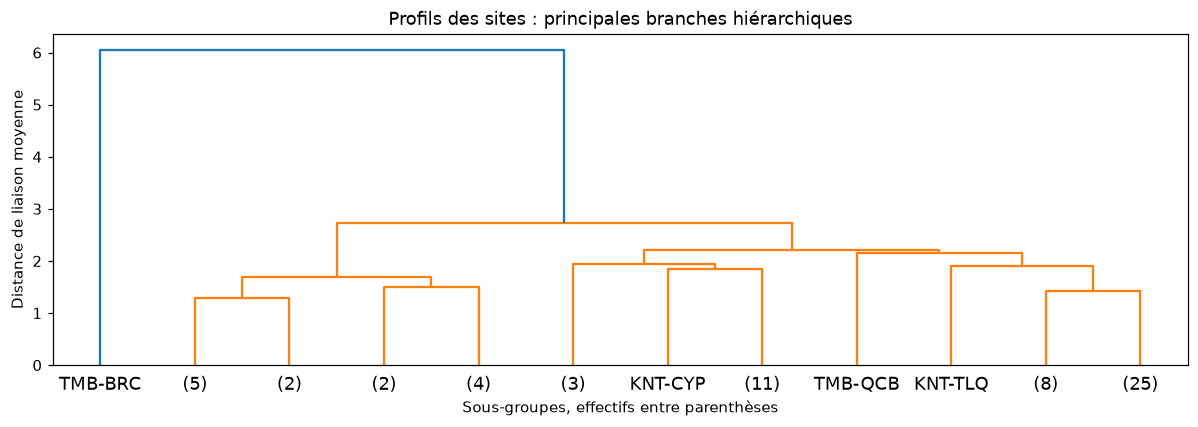

In [63]:
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree

distances_manhattan_ecology = pairwise_distances(profils_standardises_ecology, metric='manhattan')
np.fill_diagonal(distances_manhattan_ecology, np.inf)
voisins_manhattan_ecology = profil_sites_ecology.index[np.argmin(distances_manhattan_ecology, axis=1)]
comparaison_voisins_ecology = voisins_sites_ecology.copy()
comparaison_voisins_ecology['voisin_manhattan'] = voisins_manhattan_ecology
comparaison_voisins_ecology['meme_voisin'] = comparaison_voisins_ecology['site_voisin'].eq(comparaison_voisins_ecology['voisin_manhattan'])
print('Même plus proche voisin selon les deux distances :', comparaison_voisins_ecology['meme_voisin'].sum(), 'sur 64')
display(comparaison_voisins_ecology.loc[~comparaison_voisins_ecology['meme_voisin']].head(10))
liaison_sites_ecology = linkage(profils_standardises_ecology.to_numpy(), method='average', metric='euclidean')
comparaison_partitions_ecology = []
for k in [3, 4]:
    labels_kmeans = KMeans(n_clusters=k, random_state=42, n_init=20).fit_predict(profils_standardises_ecology)
    labels_hierarchie = cut_tree(liaison_sites_ecology, n_clusters=k).ravel()
    for methode, labels in [('kmeans', labels_kmeans), ('hierarchique_moyenne', labels_hierarchie)]:
        tailles = pd.Series(labels).value_counts()
        comparaison_partitions_ecology.append({'methode': methode, 'k': k, 'effectifs_groupes': sorted(tailles.astype(int).tolist()), 'plus_petit_groupe': int(tailles.min()), 'plus_grand_groupe': int(tailles.max())})
display(pd.DataFrame(comparaison_partitions_ecology).round(3))
fig, axe = plt.subplots(figsize=(11, 4))
dendrogram(liaison_sites_ecology, labels=profil_sites_ecology.index.tolist(), truncate_mode='lastp', p=12, ax=axe, show_leaf_counts=True)
axe.set(title='Profils des sites : principales branches hiérarchiques', xlabel='Sous-groupes, effectifs entre parenthèses', ylabel='Distance de liaison moyenne')
plt.tight_layout()
plt.show()

Le même voisin est retrouvé pour 53 sites sur 64 avec les deux distances :
la proximité est assez stable, mais pas universelle. Les tableaux comparent
les effectifs de K-means et de la classification hiérarchique pour trois et
quatre groupes. Avec trois groupes, K-means ne crée pas de singleton,
contrairement à la classification hiérarchique. Avec quatre groupes, les deux
méthodes en conservent un : l'isolement dépend donc aussi du découpage.
Le dendrogramme permet de voir les fusions successives ; ni la
présence d'une branche isolée ni une coupe choisie ne prouve l'existence d'un
nombre naturel de catégories.

## Cours 3 — Valeurs atypiques et cooccurrences

**Question.** Quels relevés méritent un examen, et quelles conditions accompagnent
une activité faible ? Nous commençons par l'IQR, avec les bornes usuelles
Q1 − 1,5 × IQR et Q3 + 1,5 × IQR. Un seuil global est un repérage descriptif :
il ne tient pas compte de la saison ni de l'habitat. Les observations signalées
ne sont ni supprimées ni considérées automatiquement comme suspectes.

In [64]:
variables_iqr_ecology = ['observations_par_heure', 'detections_acoustiques_par_heure', 'colony_estimate', 'observation_hours', 'weather_interference', 'uptime_pct', 'acoustic_quality']
mesures_iqr_ecology = ecologie_mensuelle[variables_iqr_ecology].astype(float)
q1_ecology = mesures_iqr_ecology.quantile(.25)
q3_ecology = mesures_iqr_ecology.quantile(.75)
iqr_ecology = q3_ecology - q1_ecology
bornes_basses_ecology = q1_ecology - 1.5 * iqr_ecology
bornes_hautes_ecology = q3_ecology + 1.5 * iqr_ecology
flags_iqr_ecology = mesures_iqr_ecology.lt(bornes_basses_ecology) | mesures_iqr_ecology.gt(bornes_hautes_ecology)
display(pd.DataFrame({'borne_basse': bornes_basses_ecology, 'borne_haute': bornes_hautes_ecology, 'nombre_signales': flags_iqr_ecology.sum()}).round(3))
signalements_sites_ecology = ecologie_mensuelle[['site_code', 'mois_releve']].copy()
signalements_sites_ecology['nombre_variables_signalees'] = flags_iqr_ecology.sum(axis=1)
display(signalements_sites_ecology.sort_values('nombre_variables_signalees', ascending=False).head(10))

,borne_basse,borne_haute,nombre_signales
observations_par_heure,-0.168,1.055,149
detections_acoustiques_par_heure,-0.242,1.511,146
colony_estimate,-7.500,37.300,155
observation_hours,16.100,44.900,67
weather_interference,-10.750,84.850,32
uptime_pct,79.550,107.950,182
acoustic_quality,57.813,100.712,82


,site_code,mois_releve,nombre_variables_signalees
2109,AVL-TRP,2019-04,4
1220,KNT-CHP,2023-03,4
1232,KNT-CHP,2024-03,4
624,KNT-CYP,2019-01,3
1244,KNT-CHP,2025-03,3
2114,AVL-TRP,2019-09,3
363,AVL-VEL,2023-04,3
2151,AVL-TRP,2022-10,3
1209,KNT-CHP,2022-04,3
1185,KNT-CHP,2020-04,3


Nous définissons ensuite une transaction comme un site-mois et cinq événements
descriptifs : activité observée sous Q1, pluie au-dessus de Q3, gêne météo au-dessus
de Q3, disponibilité sous Q1 et qualité de relevé limitée. Les quartiles sont
calculés sur l'ensemble du jeu et ne sont pas des seuils écologiques validés.

Avec cinq indicateurs et une question sur les paires, une matrice de cooccurrences
suffit. Nous calculons support, confiance et lift pour distinguer fréquence
et association relative. Aucun Apriori n'est nécessaire pour ces seules paires.

In [65]:
transactions_ecology = pd.DataFrame({
    'activite_faible': ecologie_mensuelle['observations_par_heure'].lt(ecologie_mensuelle['observations_par_heure'].quantile(.25)),
    'pluie_forte': ecologie_mensuelle['rainfall_mm'].gt(ecologie_mensuelle['rainfall_mm'].quantile(.75)),
    'gene_meteo_forte': ecologie_mensuelle['weather_interference'].gt(ecologie_mensuelle['weather_interference'].quantile(.75)),
    'disponibilite_faible': ecologie_mensuelle['uptime_pct'].lt(ecologie_mensuelle['uptime_pct'].quantile(.25)),
    'qualite_limitee': ecologie_mensuelle['survey_quality'].eq('limited')
}).astype(int)
cooccurrences_ecology = transactions_ecology.T.dot(transactions_ecology)
supports_ecology = transactions_ecology.mean()
regles_ecology = []
for antecedent in transactions_ecology.columns:
    for consequent in transactions_ecology.columns:
        if antecedent == consequent:
            continue
        support = cooccurrences_ecology.loc[antecedent, consequent] / len(transactions_ecology)
        confiance = support / supports_ecology[antecedent]
        regles_ecology.append({'antecedent': antecedent, 'consequent': consequent, 'effectif': cooccurrences_ecology.loc[antecedent, consequent], 'support': support, 'confiance': confiance, 'lift': confiance / supports_ecology[consequent], 'leverage': support - supports_ecology[antecedent] * supports_ecology[consequent]})
regles_ecology = pd.DataFrame(regles_ecology)
display(cooccurrences_ecology)
print('Proportions conditionnelles : ligne = condition de référence')
display(cooccurrences_ecology.div(np.diag(cooccurrences_ecology), axis=0).round(3))
print('Règles vers une activité faible :')
display(regles_ecology.loc[regles_ecology['consequent'].eq('activite_faible')].sort_values('lift', ascending=False).round(3))
print('Associations les plus marquées entre les conditions :')
display(regles_ecology.nlargest(4, 'lift').round(3))

Proportions conditionnelles : ligne = condition de référence
Règles vers une activité faible :
Associations les plus marquées entre les conditions :


,activite_faible,pluie_forte,gene_meteo_forte,disponibilite_faible,qualite_limitee
activite_faible,1246,320,345,319,35
pluie_forte,320,1247,918,313,34
gene_meteo_forte,345,918,1244,324,39
disponibilite_faible,319,313,324,1241,128
qualite_limitee,35,34,39,128,138


,activite_faible,pluie_forte,gene_meteo_forte,disponibilite_faible,qualite_limitee
activite_faible,1.000,0.257,0.277,0.256,0.028
pluie_forte,0.257,1.000,0.736,0.251,0.027
gene_meteo_forte,0.277,0.738,1.000,0.260,0.031
disponibilite_faible,0.257,0.252,0.261,1.000,0.103
qualite_limitee,0.254,0.246,0.283,0.928,1.000


,antecedent,consequent,effectif,support,confiance,lift,leverage
8,gene_meteo_forte,activite_faible,345,0.069,0.277,1.111,0.007
12,disponibilite_faible,activite_faible,319,0.064,0.257,1.030,0.002
4,pluie_forte,activite_faible,320,0.064,0.257,1.028,0.002
16,qualite_limitee,activite_faible,35,0.007,0.254,1.016,0.000


,antecedent,consequent,effectif,support,confiance,lift,leverage
15,disponibilite_faible,qualite_limitee,128,0.026,0.103,3.731,0.019
19,qualite_limitee,disponibilite_faible,128,0.026,0.928,3.731,0.019
9,gene_meteo_forte,pluie_forte,918,0.184,0.738,2.954,0.122
5,pluie_forte,gene_meteo_forte,918,0.184,0.736,2.954,0.122


Les lifts des règles vers « activité faible » vont ici d'environ 1,016 à 1,111.
Ces associations globales sont faibles avec les seuils choisis. Elles ne donnent
pas une explication unique aux faibles comptages. Les bornes basses IQR des indices
d'activité sont négatives : cette règle globale ne peut pas détecter une baisse
restant positive, même si elle est importante pour un site donné.

D'autres relations sont plus marquées : 128 des 138 relevés de qualité
limitée accompagnent une disponibilité sous Q1 (confiance 92,8 %, lift 3,73).
Pluie forte et gêne météo élevée coïncident aussi (lift 2,95). Ces liens entre
conditions de collecte ne se transposent pas en une explication forte de
l'activité faible. Le leverage des règles vers cette activité reste au plus
voisin de 0,007 : l'écart de cooccurrence à l'indépendance est faible.

Un lift supérieur à 1 indique une cooccurrence plus fréquente que sous
l'indépendance des indicateurs, pas un effet causal. Les observations répétées,
les saisons et les seuils choisis limitent cette lecture. Cette étape aide à
conserver des explications ordinaires à un faible comptage. Les changements
propres à un site seront examinés avec une référence saisonnière au cours 5.

### Comparer les repérages univariés et multivariés

Nous confrontons l'IQR au z-score classique et au score médian
(x − médiane) / médiane des écarts absolus, dans la convention de la
diapositive 14. Nous utilisons |score| > 3 pour examiner les deux queues ;
ce seuil descriptif du score médian n'a pas la même calibration que celui
du z-score classique. Un écart absolu médian nul rendrait le score indisponible.
Nous comparons Isolation Forest
et LOF sur les 64 profils de sites. Isolation Forest recherche les profils
faciles à isoler globalement. LOF compare leur densité à celle de leurs voisins.
Nous présentons les rangs, sans imposer un pourcentage de sites « suspects ».
Le site KNT-KES peut être important dans un document sans être un profil global
extrême sur six années : les méthodes ne répondent pas à la même question.

Nous n'avons pas de nombre connu de sites réellement anormaux à imposer
au modèle. Les 300 arbres d'Isolation Forest stabilisent le classement par rapport
à un arbre isolé ; la graine est fixée, sans recherche d'un réglage optimal.
Les scores d'isolement et LOF ont des échelles différentes et ne sont pas
additionnés en un score de suspicion. Les rangs sont utilisés plutôt que des étiquettes prises pour
une vérité de terrain. Pour LOF, dix voisins donnent une échelle locale sur
64 sites ; le choix n'est pas déclaré optimal et est confronté à cinq et quinze
voisins pour voir si la priorité d'un site change.


In [66]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

z_scores_ecology = (mesures_iqr_ecology - mesures_iqr_ecology.mean()) / mesures_iqr_ecology.std(ddof=0).replace(0, np.nan)
comparaison_univariee_ecology = pd.DataFrame({'IQR': flags_iqr_ecology.sum(), 'z_score_absolu_superieur_3': z_scores_ecology.abs().gt(3).sum()})
mediane_ecology = mesures_iqr_ecology.median()
mad_ecology = (mesures_iqr_ecology - mediane_ecology).abs().median()
z_median_ecology = (mesures_iqr_ecology - mediane_ecology) / mad_ecology.replace(0, np.nan)
comparaison_univariee_ecology['z_median_absolu_superieur_3'] = z_median_ecology.abs().gt(3).sum()
display(comparaison_univariee_ecology)
modele_if_ecology = IsolationForest(n_estimators=300, random_state=42, contamination='auto')
modele_if_ecology.fit(profils_standardises_ecology)
modele_lof_ecology = LocalOutlierFactor(n_neighbors=10, contamination='auto')
modele_lof_ecology.fit_predict(profils_standardises_ecology)
rangs_anomalies_sites_ecology = pd.DataFrame({
    'score_isolement': -modele_if_ecology.score_samples(profils_standardises_ecology),
    'facteur_lof': -modele_lof_ecology.negative_outlier_factor_
}, index=profil_sites_ecology.index)
rangs_anomalies_sites_ecology['rang_isolement'] = rangs_anomalies_sites_ecology['score_isolement'].rank(ascending=False, method='min').astype(int)
rangs_anomalies_sites_ecology['rang_lof'] = rangs_anomalies_sites_ecology['facteur_lof'].rank(ascending=False, method='min').astype(int)
display(rangs_anomalies_sites_ecology.sort_values('rang_isolement').head(10).round(3))
print('Comparaison de deux sites retenus pour des raisons différentes :')
display(rangs_anomalies_sites_ecology.loc[['KNT-KES', 'TMB-BRC']].round(3))
# Vérifier que le rang local ne repose pas sur un seul choix du voisinage.
sensibilite_lof_ecology = []
for nombre_voisins in [5, 10, 15]:
    modele = LocalOutlierFactor(n_neighbors=nombre_voisins)
    modele.fit_predict(profils_standardises_ecology)
    rangs = pd.Series(-modele.negative_outlier_factor_, index=profil_sites_ecology.index).rank(ascending=False, method='min')
    sensibilite_lof_ecology.append({'voisins': nombre_voisins, 'rang_KNT_KES': rangs.loc['KNT-KES'], 'rang_TMB_BRC': rangs.loc['TMB-BRC']})
display(pd.DataFrame(sensibilite_lof_ecology))

Comparaison de deux sites retenus pour des raisons différentes :


,IQR,z_score_absolu_superieur_3,z_median_absolu_superieur_3
observations_par_heure,149,69,309
detections_acoustiques_par_heure,146,75,346
colony_estimate,155,71,351
observation_hours,67,32,256
weather_interference,32,26,130
uptime_pct,182,122,270
acoustic_quality,82,41,276


,score_isolement,facteur_lof,rang_isolement,rang_lof
site_code,,,,
TMB-BRC,0.757,3.244,1,1
KNT-GGN,0.656,1.350,2,9
KNT-CYP,0.602,1.416,3,6
TMB-QCB,0.577,2.101,4,2
AVL-YAU,0.567,1.184,5,21
AVL-TRP,0.562,1.303,6,10
AVL-GRB,0.547,1.227,7,16
KNT-YRG,0.546,1.184,8,22
AVL-HUA,0.540,1.241,9,11


,score_isolement,facteur_lof,rang_isolement,rang_lof
site_code,,,,
KNT-KES,0.509,1.139,13,28
TMB-BRC,0.757,3.244,1,1


,voisins,rang_KNT_KES,rang_TMB_BRC
0,5,8.0,1.0
1,10,28.0,1.0
2,15,19.0,1.0


Pour les observations par heure, l'IQR signale 149 relevés, le z-score
classique 69 et le score médian non normalisé 309. Pour les détections, les
nombres sont 146, 75 et 346. Cette différence reflète la référence et l'échelle
des scores ; le nombre de signalements ne mesure pas la qualité d'une méthode.
Nous ne choisissons pas celle qui produit le plus de cas, et nous ne supprimons
aucune de ces lignes automatiquement.

TMB-BRC arrive en tête d'Isolation Forest et de LOF ; c'est surtout un site d'activité élevée. KNT-KES est seulement 13e pour l'isolement et 28e pour LOF avec dix voisins ; son rang LOF varie de 8 à 28 avec le voisinage. Sa priorité vient du contexte documentaire et d'épisodes datés, pas d'une anomalie globale indiscutable. Les médianes calculées sur toute la période peuvent masquer une baisse de quelques mois.

## Cours 4 — Réseau des sites et des prestataires de maintenance

**Question.** Les opérations enregistrées révèlent-elles des liens particuliers
entre sites et prestataires ? Nous construisons un graphe biparti non orienté :
un nœud représente un site ou un prestataire, et un lien signifie qu'au moins
une opération associe les deux. Son poids est le nombre d'opérations.

Ce réseau décrit des associations administratives. Il ne représente ni un trajet
de transport ni le déplacement de chauves-souris. Les prestataires manquants
ne sont pas regroupés en un faux acteur commun. Nous ne fabriquons pas de
processus à partir de relevés mensuels qui ne sont pas des tâches successives.

Nœuds / liens : 68 64
Composantes connexes : 4


,nombre_sites,nombre_operations
maintenance_provider,,
ECO-SERVICE-1,16,1241
ECO-SERVICE-2,16,1242
ECO-SERVICE-3,16,1239
ECO-SERVICE-4,16,1240


,site_code,maintenance_provider,nombre_operations
30,KNT-KES,ECO-SERVICE-2,78


maintenance_provider,ECO-SERVICE-1,ECO-SERVICE-2,ECO-SERVICE-3,ECO-SERVICE-4
region,,,,
Eastern Avelora Agricultural Cluster,465,467,467,310
Kintara Karst Cluster,310,465,463,467
Tembara Coastal Cluster,466,310,309,463


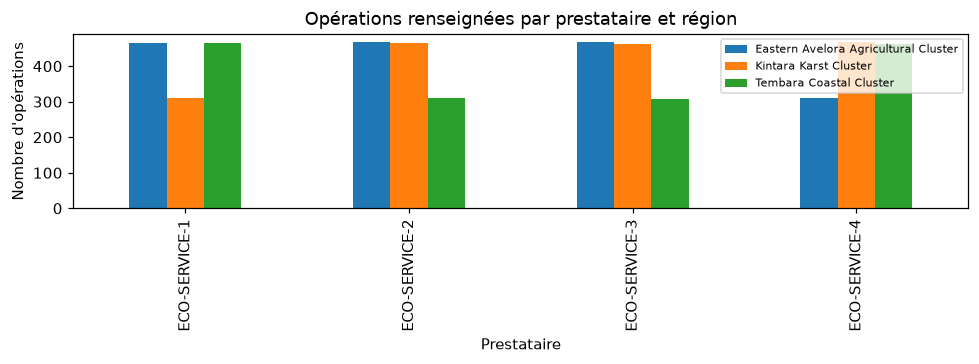

In [67]:
import networkx as nx

liens_maintenance_ecology = df_appareils.dropna(subset=['maintenance_provider']).groupby(['site_code', 'maintenance_provider']).size().rename('nombre_operations').reset_index()
graphe_maintenance_ecology = nx.Graph()
for ligne in liens_maintenance_ecology.itertuples(index=False):
    site = 'site:' + ligne.site_code
    prestataire = 'prestataire:' + ligne.maintenance_provider
    graphe_maintenance_ecology.add_node(site, type_noeud='site')
    graphe_maintenance_ecology.add_node(prestataire, type_noeud='prestataire')
    graphe_maintenance_ecology.add_edge(site, prestataire, weight=int(ligne.nombre_operations))
resume_prestataires_ecology = liens_maintenance_ecology.groupby('maintenance_provider').agg(nombre_sites=('site_code', 'nunique'), nombre_operations=('nombre_operations', 'sum'))
print('Nœuds / liens :', graphe_maintenance_ecology.number_of_nodes(), graphe_maintenance_ecology.number_of_edges())
print('Composantes connexes :', nx.number_connected_components(graphe_maintenance_ecology))
display(resume_prestataires_ecology)
display(liens_maintenance_ecology.loc[liens_maintenance_ecology['site_code'].eq('KNT-KES')])
# Vue agrégée lisible : le graphe complet reste disponible dans la variable ci-dessus.
maintenance_regions_ecology = liens_maintenance_ecology.merge(df_sites[['site_code', 'region']], on='site_code', validate='many_to_one')
matrice_regions_ecology = maintenance_regions_ecology.pivot_table(index='region', columns='maintenance_provider', values='nombre_operations', aggfunc='sum', fill_value=0)
display(matrice_regions_ecology)
fig, axe = plt.subplots(figsize=(9, 3.5))
matrice_regions_ecology.T.plot.bar(ax=axe)
axe.set(title='Opérations renseignées par prestataire et région', ylabel="Nombre d'opérations", xlabel='Prestataire')
axe.legend(fontsize=7)
plt.tight_layout()
plt.show()

Le graphe comporte 68 nœuds et 64 liens, répartis en quatre composantes : chaque
prestataire renseigné couvre 16 sites. KNT-KES est relié à ECO-SERVICE-2 pour
78 opérations. Cette organisation régulière ne permet pas d'identifier un
prestataire particulièrement associé à une opération suspecte.

Le degré d'un prestataire compte les sites reliés, alors que la somme des poids
compte ses opérations. Une couverture régulière ou étendue ne constitue pas
un indice de transport clandestin. Les codes `ECO-SERVICE-*` sont internes à
Ecology : aucun rapprochement avec une entreprise externe ne sera affirmé
sans table de correspondance. Les degrés et les composantes suffisent ici,
sans ajouter un algorithme de communautés à un petit réseau biparti.

### Processus réels d'accès aux sites, à partir de Public Records

Les relevés mensuels ne sont pas un journal de tâches, mais les demandes d'accès
en sont un. Pour les sites Ecology présents dans ce registre, un cas est une
demande d'accès et un événement est une activité administrative datée.
Nous utilisons les identifiants et conservons les étapes absentes telles quelles.
L'absence d'une étape enregistrée ne prouve pas qu'une obligation a été contournée.

,nombre_cas
sequence,
"(request_submitted, technical_review, wildlife_review, authorization_granted, access_started, access_completed, closure_recorded)",28
"(request_submitted, technical_review, authorization_granted, access_started, access_completed, closure_recorded)",12
"(request_submitted, technical_review, wildlife_review, security_review, authorization_granted, access_started, access_completed, closure_recorded)",11
"(request_submitted, technical_review, wildlife_review, authorization_denied, closure_recorded)",4
"(request_submitted, technical_review, authorization_denied, closure_recorded)",2
"(request_submitted, technical_review, wildlife_review, authorization_denied, request_submitted, authorization_granted, access_started, access_completed, closure_recorded)",2
"(request_submitted, technical_review, wildlife_review, security_review, authorization_denied, request_submitted, authorization_granted, access_started, access_completed, closure_recorded)",1


,source,destination,effectif
0,DEBUT,request_submitted,60
1,request_submitted,technical_review,60
7,closure_recorded,FIN,60
5,access_started,access_completed,54
4,authorization_granted,access_started,54
6,access_completed,closure_recorded,54
2,technical_review,wildlife_review,46
3,wildlife_review,authorization_granted,28
8,technical_review,authorization_granted,12
9,wildlife_review,security_review,12


,site,debut,fin,nombre_evenements,confidentialite,duree_jours,security_review_enregistree
access_case_number,,,,,,,
ACC-2018-0002,KNT-KES,2018-02-19 09:00:00,2018-03-25 11:00:00,8,confidential,34.083333,True
ACC-2021-0009,KNT-KES,2021-02-22 09:00:00,2021-03-28 11:00:00,8,standard,34.083333,True
ACC-2024-0014,KNT-KES,2024-02-19 09:00:00,2024-03-24 11:00:00,7,restricted,34.083333,False


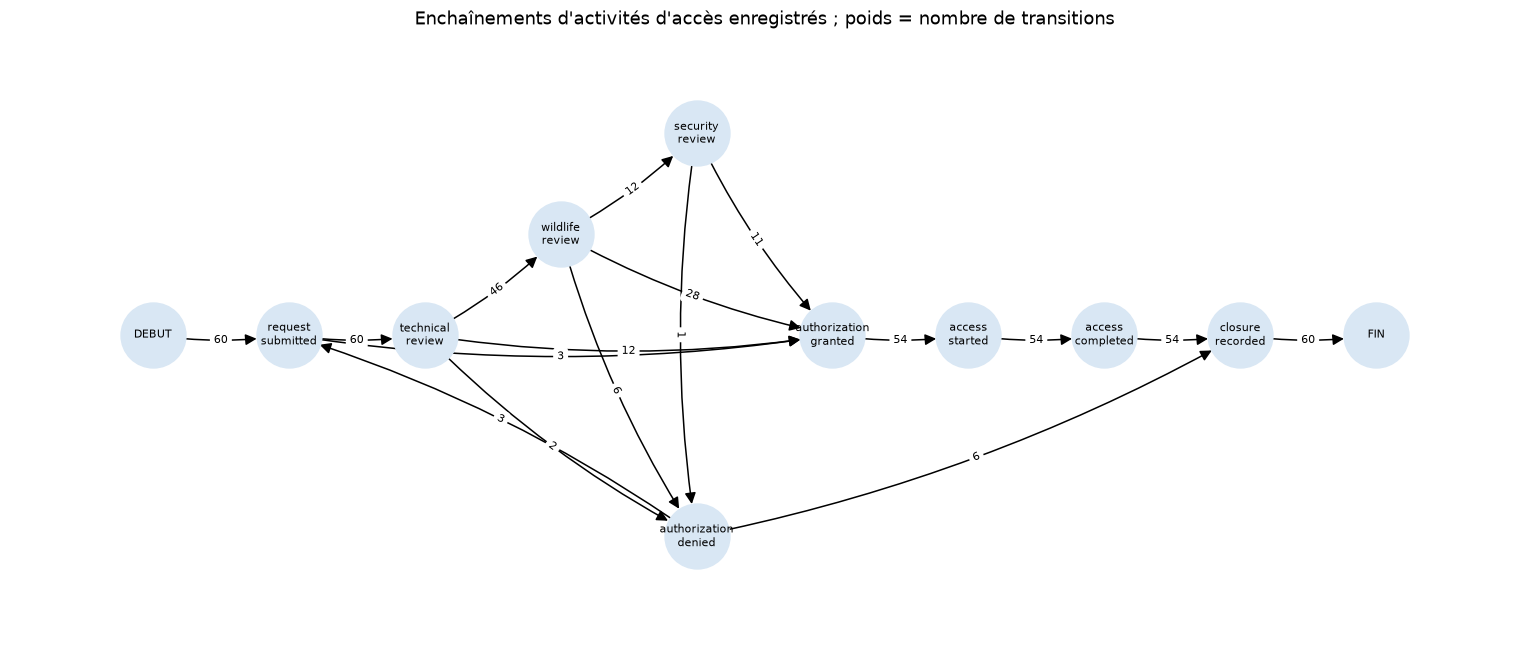

In [68]:
from collections import Counter

journal_acces_ecology = pd.read_csv('data/public_records/site_access_case_events.csv').drop_duplicates()
journal_acces_ecology = journal_acces_ecology.loc[journal_acces_ecology['site_code'].isin(df_sites['site_code'])].copy()
journal_acces_ecology['event_time'] = dates_heures_ecology(journal_acces_ecology['event_time'])
for colonne in ['activity', 'previous_status', 'new_status', 'confidentiality_class']:
    journal_acces_ecology[colonne] = categorie_ecology(journal_acces_ecology[colonne])
assert journal_acces_ecology['access_event_id'].is_unique
journal_acces_ecology = journal_acces_ecology.sort_values(['access_case_number', 'event_time', 'access_event_id'])
variantes_acces_ecology = journal_acces_ecology.groupby('access_case_number')['activity'].agg(tuple)
display(variantes_acces_ecology.value_counts().rename_axis('sequence').to_frame('nombre_cas'))
transitions_acces_ecology = Counter()
for sequence in variantes_acces_ecology:
    parcours = ('DEBUT',) + sequence + ('FIN',)
    transitions_acces_ecology.update(zip(parcours[:-1], parcours[1:]))
graphe_acces_ecology = nx.DiGraph()
for (source, destination), poids in transitions_acces_ecology.items():
    graphe_acces_ecology.add_edge(source, destination, weight=poids)
table_transitions_acces_ecology = pd.DataFrame([{'source': u, 'destination': v, 'effectif': w} for (u,v),w in transitions_acces_ecology.items()]).sort_values('effectif', ascending=False)
display(table_transitions_acces_ecology.head(12))
resume_cas_acces_ecology = journal_acces_ecology.groupby('access_case_number').agg(site=('site_code', 'first'), debut=('event_time', 'min'), fin=('event_time', 'max'), nombre_evenements=('access_event_id', 'size'), confidentialite=('confidentiality_class', 'first'))
resume_cas_acces_ecology['duree_jours'] = (resume_cas_acces_ecology['fin'] - resume_cas_acces_ecology['debut']).dt.total_seconds() / 86400
resume_cas_acces_ecology['security_review_enregistree'] = variantes_acces_ecology.map(lambda sequence: 'security_review' in sequence)
display(resume_cas_acces_ecology.loc[resume_cas_acces_ecology['site'].eq('KNT-KES')])
fig, axe = plt.subplots(figsize=(14, 6))
positions = {'DEBUT': (0, 1), 'request_submitted': (1.5, 1), 'technical_review': (3, 1),
             'wildlife_review': (4.5, 2), 'security_review': (6, 3),
             'authorization_granted': (7.5, 1), 'access_started': (9, 1),
             'access_completed': (10.5, 1), 'closure_recorded': (12, 1),
             'FIN': (13.5, 1), 'authorization_denied': (6, -1)}
nx.draw_networkx_nodes(graphe_acces_ecology, pos=positions, ax=axe, node_size=1800, node_color='#d9e7f4')
nx.draw_networkx_labels(graphe_acces_ecology, pos=positions, ax=axe, font_size=7,
                        labels={n: n.replace('_', '\n') for n in graphe_acces_ecology})
nx.draw_networkx_edges(graphe_acces_ecology, pos=positions, ax=axe, node_size=1800, arrowsize=15,
                      connectionstyle='arc3,rad=0.08')
nx.draw_networkx_edge_labels(graphe_acces_ecology, pos=positions, edge_labels=nx.get_edge_attributes(graphe_acces_ecology, 'weight'), font_size=7, ax=axe, connectionstyle='arc3,rad=0.08')
axe.margins(.06, .18)
axe.set_title("Enchaînements d'activités d'accès enregistrés ; poids = nombre de transitions")
axe.axis('off')
plt.tight_layout()
plt.show()

La mesure de dépendance du Heuristic Miner compare les transitions dans les deux
sens : (effectif A→B − effectif B→A) / (effectif A→B + effectif B→A + 1).
Nous calculons cette mesure pour décrire les liens principaux, sans prétendre
implémenter un outil complet de process mining. Elle ne transforme pas une
succession administrative en preuve de transport matériel.

In [69]:
dependances_acces_ecology = table_transitions_acces_ecology.copy()
dependances_acces_ecology['effectif_inverse'] = [transitions_acces_ecology.get((ligne.destination, ligne.source), 0) for ligne in dependances_acces_ecology.itertuples(index=False)]
dependances_acces_ecology['dependance'] = (dependances_acces_ecology['effectif'] - dependances_acces_ecology['effectif_inverse']) / (dependances_acces_ecology['effectif'] + dependances_acces_ecology['effectif_inverse'] + 1)
display(dependances_acces_ecology.sort_values('dependance', ascending=False).head(12).round(3))

,source,destination,effectif,effectif_inverse,dependance
0,DEBUT,request_submitted,60,0,0.984
1,request_submitted,technical_review,60,0,0.984
7,closure_recorded,FIN,60,0,0.984
5,access_started,access_completed,54,0,0.982
4,authorization_granted,access_started,54,0,0.982
6,access_completed,closure_recorded,54,0,0.982
2,technical_review,wildlife_review,46,0,0.979
3,wildlife_review,authorization_granted,28,0,0.966
8,technical_review,authorization_granted,12,0,0.923
9,wildlife_review,security_review,12,0,0.923


Après harmonisation, les 412 événements décrivent 60 demandes et sept variantes. Cinquante-quatre cas comportent un accès réalisé et six se terminent après un refus ; trois parcours comprennent un refus suivi d'une nouvelle demande et d'une autorisation. KNT-KES a une étape `security_review` en 2018 et 2021, mais pas en 2024. Cette absence n'est ni unique dans le registre ni une preuve d'irrégularité réglementaire. Les dépendances fortes décrivent surtout la séquence administrative attendue.

## Cours 5 — Évolution temporelle, saisonnalité et examen local

**Question.** Une baisse locale dépasse-t-elle les variations habituelles ?
Nous reprenons d'abord les médianes régionales, puis l'autocorrélation et une
décomposition additive classique à période 12. Ces séries sont mensuelles,
régulières et comportent plus de deux années. Une périodicité apparente n'est
pas une cause identifiée. La décomposition est rétrospective, pas une prévision.
Nous n'utilisons pas STL, SARIMA ou Prophet, seulement mentionnés comme pistes
complémentaires dans le support.

La période de douze mois correspond à un cycle annuel possible dans une
série mensuelle ; les autocorrélations servent à vérifier cette hypothèse.
La forme additive exprime des écarts dans l'unité de l'indice, sans supposer
une variation proportionnelle au niveau de la série. C'est une représentation
descriptive : si le motif change au cours du temps, son résidu peut refléter
cette limite plutôt qu'un événement écologique inhabituel.


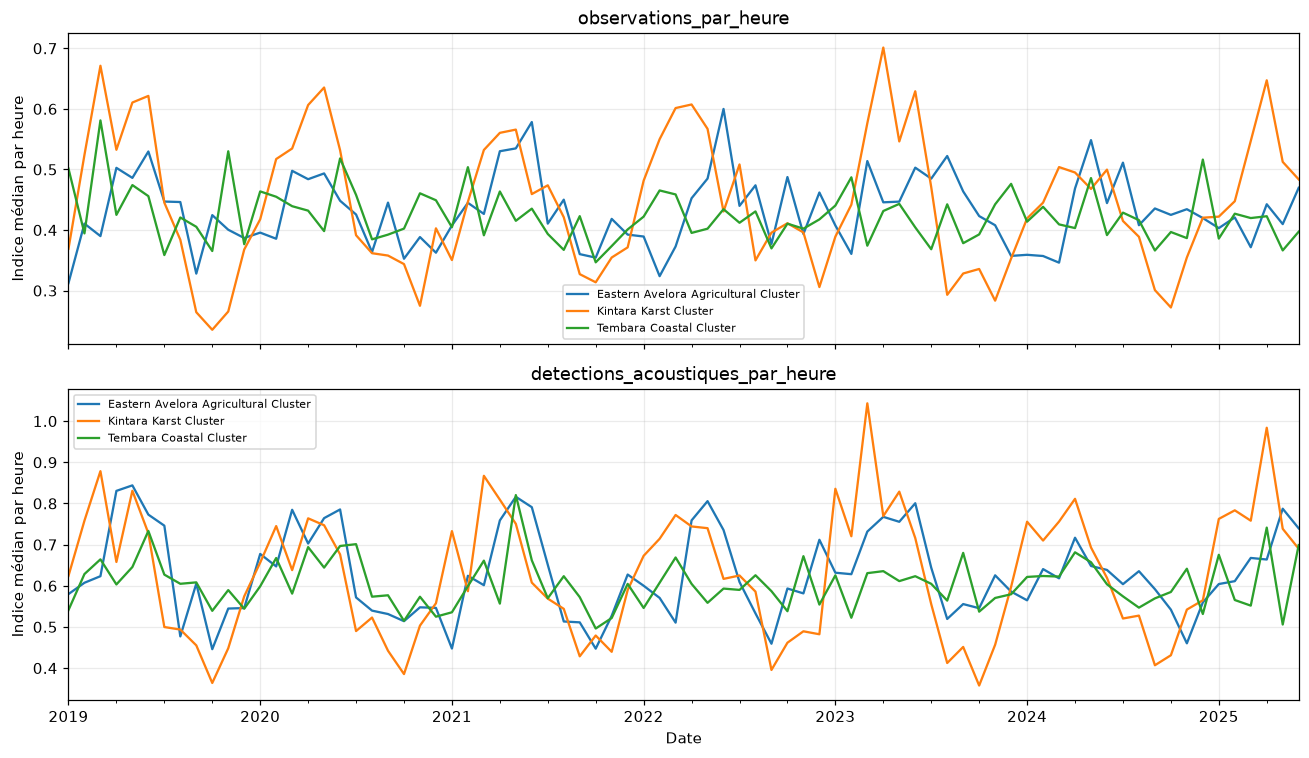

In [70]:
evolution_mensuelle_bats = ecologie_mensuelle.groupby(['mois_releve', 'region'])[['observations_par_heure', 'detections_acoustiques_par_heure']].median()
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for axe, variable in zip(axes, ['observations_par_heure', 'detections_acoustiques_par_heure']):
    tableau = evolution_mensuelle_bats[variable].unstack('region')
    tableau.index = tableau.index.to_timestamp()
    tableau.plot(ax=axe)
    axe.set_ylabel('Indice médian par heure')
    axe.set_title(variable)
    axe.set_xlabel('')
    axe.legend(fontsize=7)
    axe.grid(alpha=.25)
axes[-1].set_xlabel('Date')
plt.tight_layout()
plt.show()

### Autocorrélation et décomposition classique

Les oscillations régionales suggèrent un motif annuel. Nous examinons les retards, puis une moyenne mobile centrée 2 × 12 pour séparer tendance, motif mensuel moyen et résidu. Le résidu peut aussi refléter les limites de cette représentation additive.

Autocorrélation aux retards 1, 6, 12 et 24 mois :


1     0.708
6    -0.763
12    0.746
24    0.735
Name: autocorrelation, dtype: float64

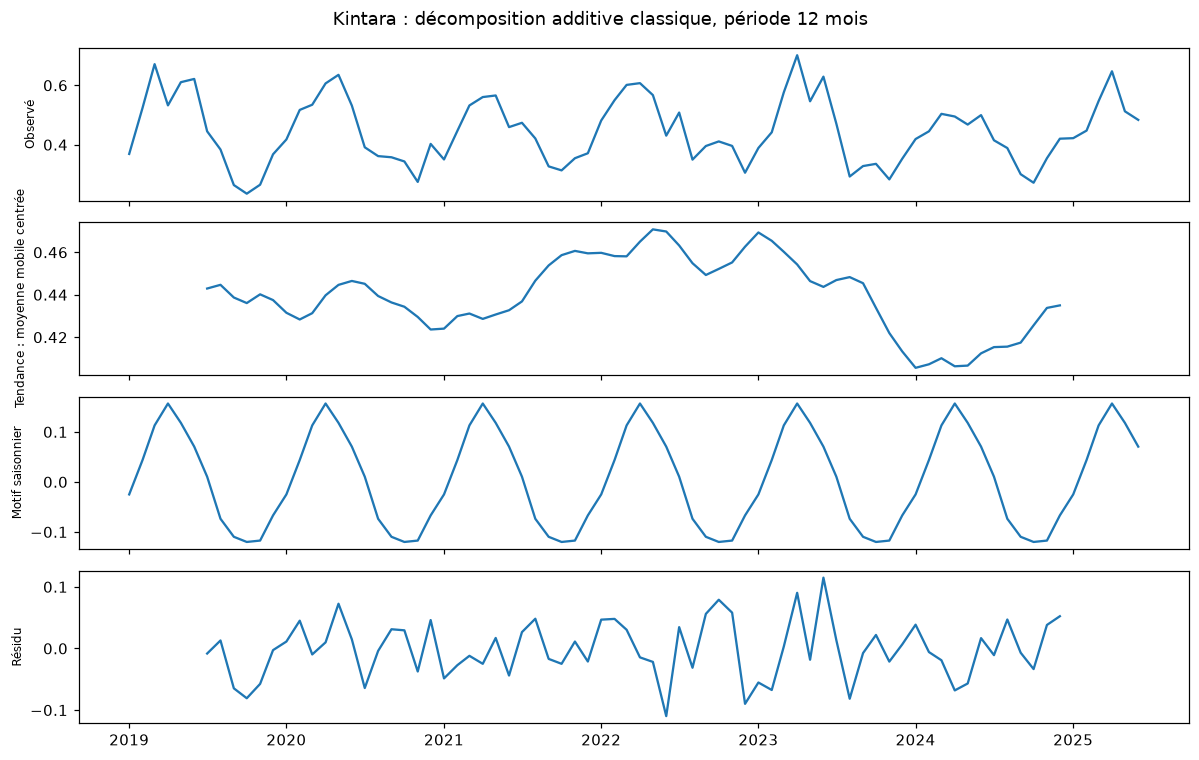

In [71]:
serie_kintara_ecology = evolution_mensuelle_bats.xs('Kintara Karst Cluster', level='region')['observations_par_heure'].astype(float)
serie_kintara_ecology.index = serie_kintara_ecology.index.to_timestamp()
autocorrelations_ecology = pd.Series({retard: serie_kintara_ecology.autocorr(lag=retard) for retard in range(1, 25)}, name='autocorrelation')
print('Autocorrélation aux retards 1, 6, 12 et 24 mois :')
display(autocorrelations_ecology.loc[[1, 6, 12, 24]].round(3))
# Moyenne mobile centrée 2 x 12, adaptée à une période paire.
moyenne_mobile_ecology = serie_kintara_ecology.rolling(12, center=True).mean()
tendance_kintara_ecology = (moyenne_mobile_ecology + moyenne_mobile_ecology.shift(-1)) / 2
sans_tendance_ecology = serie_kintara_ecology - tendance_kintara_ecology
motif_mensuel_ecology = sans_tendance_ecology.groupby(sans_tendance_ecology.index.month).mean()
motif_mensuel_ecology = motif_mensuel_ecology - motif_mensuel_ecology.mean()
saison_kintara_ecology = pd.Series(serie_kintara_ecology.index.month.map(motif_mensuel_ecology), index=serie_kintara_ecology.index)
residu_kintara_ecology = serie_kintara_ecology - tendance_kintara_ecology - saison_kintara_ecology
assert np.allclose((tendance_kintara_ecology + saison_kintara_ecology + residu_kintara_ecology).dropna(), serie_kintara_ecology.loc[residu_kintara_ecology.notna()])
fig, axes = plt.subplots(4, 1, figsize=(11, 7), sharex=True)
for axe, serie, titre in zip(axes, [serie_kintara_ecology, tendance_kintara_ecology, saison_kintara_ecology, residu_kintara_ecology], ['Observé', 'Tendance : moyenne mobile centrée', 'Motif saisonnier', 'Résidu']):
    axe.plot(serie.index, serie)
    axe.set_ylabel(titre, fontsize=8)
fig.suptitle('Kintara : décomposition additive classique, période 12 mois')
plt.tight_layout()
plt.show()

L'autocorrélation de Kintara est positive à 12 mois (≈ 0,746) et à 24 mois
(≈ 0,735), et négative à 6 mois (≈ −0,763). Cela étaye une variation annuelle
dans cette série agrégée. La décomposition sépare un motif récurrent de la
tendance et des écarts résiduels. La moyenne mobile centrée laisse les extrémités
sans tendance ni résidu : ces valeurs absentes ne sont pas remplacées par zéro.

### Étude de KNT-KES et choix des références

Le choix de ce site est motivé par le rapport `EFR-510088`, lu lors de
l'exploration documentaire, et non par une sélection automatique aveugle.
Le rapport parle d'un accès en mars 2024 et d'une baisse ultérieure.
Cette piste sera évaluée plutôt que considérée comme vraie.

Nous prenons 2019–2023 comme référence antérieure à cet événement et comparons
chaque mois au même mois calendaire de ces cinq années. Une référence de cinq
valeurs par mois reste limitée. Les sites de comparaison sont choisis dans le
même habitat et la même région, sur leurs conditions environnementales médianes
avant 2024, et non parce que leurs courbes donnent le résultat attendu.

La référence s'arrête avant 2024 pour que les mois examinés ne participent
pas à leur propre niveau habituel. Comparer avril à tous les mois mélangés
confondrait baisse locale et variation annuelle. Les trois voisins fournissent
un petit ensemble lisible de comparaisons proches sur l'environnement, sans
postuler qu'ils soient des témoins parfaits ni que trois soit un nombre optimal.

Les températures, précipitations, humidités et couvertures végétales n'ont pas
les mêmes échelles. La standardisation est utilisée uniquement pour la distance
entre profils environnementaux : elle donne le même poids à leurs écarts-types,
pas la même importance écologique. Les pourcentages d'origine restent intacts
dans les tableaux et ne sont pas interprétés dans l'unité standardisée.

In [72]:
site_cible_ecology = 'KNT-KES'
avant_ecology = ecologie_mensuelle['survey_start'].lt('2024-01-01')
conditions_reference_ecology = ['mean_temperature_c', 'rainfall_mm', 'mean_humidity_pct', 'vegetation_cover_pct']
contexte_cible_ecology = df_sites.set_index('site_code').loc[site_cible_ecology]
candidats_reference_ecology = df_sites.loc[df_sites['region'].eq(contexte_cible_ecology['region']) & df_sites['habitat_category'].eq(contexte_cible_ecology['habitat_category']), 'site_code']
environnement_reference_ecology = ecologie_mensuelle.loc[avant_ecology & ecologie_mensuelle['site_code'].isin(candidats_reference_ecology)].groupby('site_code')[conditions_reference_ecology].median()
reference_standardisee_ecology = StandardScaler().fit_transform(environnement_reference_ecology)
position_cible_ecology = environnement_reference_ecology.index.get_loc(site_cible_ecology)
distances_reference_ecology = pd.Series(pairwise_distances(reference_standardisee_ecology[[position_cible_ecology]], reference_standardisee_ecology)[0], index=environnement_reference_ecology.index).drop(site_cible_ecology).sort_values()
sites_reference_ecology = distances_reference_ecology.head(3).index.tolist()
print('Sites de comparaison et distances environnementales standardisées :')
display(distances_reference_ecology.head(3).to_frame('distance'))

Sites de comparaison et distances environnementales standardisées :


,distance
site_code,
KNT-NNM,1.326499
KNT-CHP,1.488420
KNT-JAK,1.878428


### Comparaison au même mois des années antérieures

Nous comparons chaque mesure à la médiane du même mois en 2019–2023 pour son propre site. Un dénominateur nul rend le ratio indisponible : il ne sera pas remplacé par zéro.

Références nulles : ratios laissés manquants, pas remplacés par zéro.
Conditions du site ciblé et médianes du même mois avant 2024 :


,references_nulles
observations_par_heure_reference,0
detections_acoustiques_par_heure_reference,0
colony_estimate_reference,0
comparison_species_count_reference,0


,mois_releve,observations_par_heure,observations_par_heure_reference,observations_par_heure_ratio,detections_acoustiques_par_heure_ratio,uptime_pct,acoustic_quality,weather_interference
62,2024-03,0.502,0.752,0.667,0.968,88.7,77.8,21.5
63,2024-04,0.334,0.728,0.459,0.497,83.1,73.1,29.9
64,2024-05,0.111,0.719,0.154,0.489,91.8,71.4,47.0
65,2024-06,0.49,0.894,0.548,0.22,100.0,65.7,54.1
66,2024-07,0.367,0.645,0.568,0.375,88.3,79.6,48.9
67,2024-08,0.249,0.449,0.554,1.609,91.8,85.3,56.8


,mois_releve,mois_calendaire,observation_hours,rainfall_mm,habitat_disturbance_index,pesticide_index,uptime_pct,acoustic_quality,comparison_species_count_ratio,survey_method,survey_quality,observation_hours_reference,rainfall_mm_reference,habitat_disturbance_index_reference,pesticide_index_reference,uptime_pct_reference,acoustic_quality_reference
0,2024-03,3,31.9,118.4,26.3,27.4,88.7,77.8,1.800000,acoustic_transect,acceptable,33.8,111.2,24.6,19.6,94.9,82.5
1,2024-04,4,29.9,140.6,7.9,19.4,83.1,73.1,1.181818,acoustic_and_visual,acceptable,35.7,148.1,19.0,21.7,95.4,79.4
2,2024-05,5,27.1,246.2,17.7,36.8,91.8,71.4,1.000000,acoustic_and_visual,acceptable,32.7,209.6,20.3,24.8,87.7,77.9
3,2024-06,6,28.6,231.3,24.9,31.8,100.0,65.7,0.769231,acoustic_and_visual,acceptable,27.0,203.1,19.2,17.7,94.7,76.2
4,2024-07,7,30.0,240.0,13.4,24.8,88.3,79.6,1.600000,fixed_acoustic_station,high,27.2,257.5,24.8,31.7,97.7,80.0
5,2024-08,8,20.1,252.8,16.1,21.1,91.8,85.3,0.923077,acoustic_and_visual,high,25.6,239.8,20.4,16.0,91.4,74.9


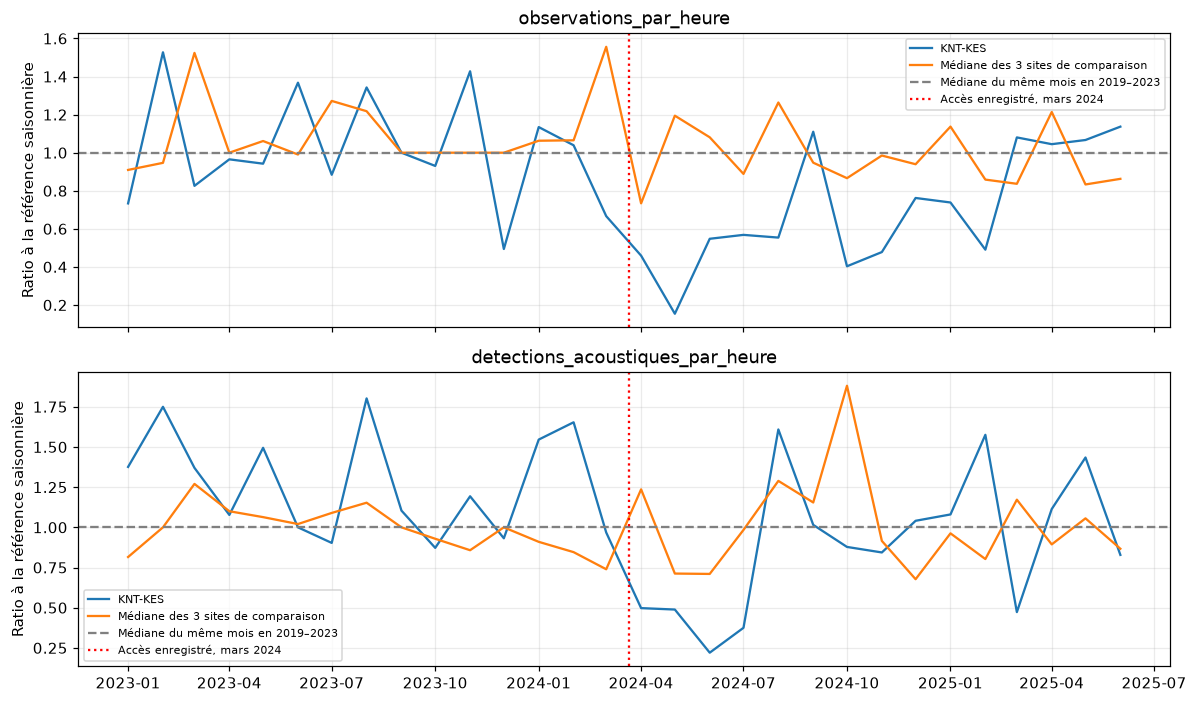

In [73]:
ecologie_mensuelle['mois_calendaire'] = ecologie_mensuelle['survey_start'].dt.month
variables_saison_ecology = ['observations_par_heure', 'detections_acoustiques_par_heure', 'colony_estimate', 'comparison_species_count']
references_saisonnieres_ecology = ecologie_mensuelle.loc[avant_ecology].groupby(['site_code', 'mois_calendaire'])[variables_saison_ecology].median().add_suffix('_reference')
comparaison_saison_ecology = ecologie_mensuelle.merge(references_saisonnieres_ecology, on=['site_code', 'mois_calendaire'], how='left', validate='many_to_one')
for variable in variables_saison_ecology:
    denominateur = comparaison_saison_ecology[variable + '_reference'].replace(0, np.nan)
    comparaison_saison_ecology[variable + '_ratio'] = comparaison_saison_ecology[variable] / denominateur
print('Références nulles : ratios laissés manquants, pas remplacés par zéro.')
display((references_saisonnieres_ecology == 0).sum().to_frame('references_nulles'))
cible_temporelle_ecology = comparaison_saison_ecology.loc[comparaison_saison_ecology['site_code'].eq(site_cible_ecology)].sort_values('mois_releve')
resume_cible_2024_ecology = cible_temporelle_ecology.loc[cible_temporelle_ecology['survey_start'].between('2024-03-01', '2024-08-31')]
colonnes_cible_ecology = ['mois_releve', 'observations_par_heure', 'observations_par_heure_reference', 'observations_par_heure_ratio', 'detections_acoustiques_par_heure_ratio', 'uptime_pct', 'acoustic_quality', 'weather_interference']
tableau_cible_ecology = resume_cible_2024_ecology[colonnes_cible_ecology].copy()
tableau_cible_ecology['mois_releve'] = tableau_cible_ecology['mois_releve'].astype(str)
display(tableau_cible_ecology.round(3))
conditions_cible_ecology = ['observation_hours', 'rainfall_mm', 'habitat_disturbance_index', 'pesticide_index', 'uptime_pct', 'acoustic_quality']
reference_conditions_cible_ecology = ecologie_mensuelle.loc[avant_ecology & ecologie_mensuelle['site_code'].eq(site_cible_ecology)].groupby('mois_calendaire')[conditions_cible_ecology].median().add_suffix('_reference')
controle_conditions_cible_ecology = resume_cible_2024_ecology[['mois_releve', 'mois_calendaire'] + conditions_cible_ecology + ['comparison_species_count_ratio', 'survey_method', 'survey_quality']].merge(reference_conditions_cible_ecology, on='mois_calendaire', how='left', validate='many_to_one')
print('Conditions du site ciblé et médianes du même mois avant 2024 :')
display(controle_conditions_cible_ecology)
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
for axe, variable in zip(axes, ['observations_par_heure', 'detections_acoustiques_par_heure']):
    cible = cible_temporelle_ecology.loc[cible_temporelle_ecology['survey_start'].ge('2023-01-01')]
    reference = comparaison_saison_ecology.loc[comparaison_saison_ecology['site_code'].isin(sites_reference_ecology) & comparaison_saison_ecology['survey_start'].ge('2023-01-01')].groupby('mois_releve')[variable + '_ratio'].median()
    axe.plot(cible['mois_releve'].dt.to_timestamp(), cible[variable + '_ratio'], label='KNT-KES')
    axe.plot(reference.index.to_timestamp(), reference, label='Médiane des 3 sites de comparaison')
    axe.axhline(1, color='grey', linestyle='--', label='Médiane du même mois en 2019–2023')
    axe.axvline(pd.Timestamp('2024-03-21'), color='red', linestyle=':', label='Accès enregistré, mars 2024')
    axe.set_ylabel('Ratio à la référence saisonnière')
    axe.set_title(variable)
    axe.legend(fontsize=7)
    axe.grid(alpha=.25)
plt.tight_layout()
plt.show()

Pour KNT-KES, l'indice observé d'avril 2024 vaut environ 46 % de sa médiane
des mois d'avril 2019–2023. Celui de mai vaut environ 15 %. Les détections
acoustiques d'avril et mai représentent près de la moitié de leurs références.
Cette baisse mérite donc un examen local. Les références retenues sont KNT-NNM,
KNT-CHP et KNT-JAK. Elles ne constituent pas un groupe témoin expérimental.

La baisse n'apparaît pas exclusivement après l'accès : le relevé du 5 au 12 mars
est déjà sous sa référence observée (≈ 67 %), avant l'accès du 21 mars.
Les indices observés et acoustiques ne restent pas non plus synchrones :
l'acoustique remonte au-dessus de sa référence en août 2024, contrairement
aux observations. La qualité acoustique et la disponibilité sont variables.
Ces éléments empêchent d'attribuer toute l'évolution à l'accès de mars.
Nous comparons aussi les conditions à leurs références saisonnières. Nous ne
divisons pas les détections par la disponibilité ou la qualité pour prétendre
les corriger : aucune calibration ne permet ici une telle correction.

### Sensibilité de la référence calendaire

La référence principale 2019–2023 reste inchangée. Nous recalculons les ratios
avec 2019–2021 puis 2021–2023, soit trois valeurs par mois et par site. Ces
périodes se recouvrent en 2021 et ne sont pas des validations indépendantes.
Nous comparons avril et mai 2024, puis les mois sous la moitié de la référence
sur la même période 2024–juin 2025. Les références nulles restent indisponibles.

In [74]:
sensibilite_references_ecology = []
for nom, debut, fin in [('2019–2023', '2019-01-01', '2024-01-01'),
                        ('2019–2021', '2019-01-01', '2022-01-01'),
                        ('2021–2023', '2021-01-01', '2024-01-01')]:
    historique = ecologie_mensuelle.loc[ecologie_mensuelle['survey_start'].ge(debut) & ecologie_mensuelle['survey_start'].lt(fin)]
    reference = historique.groupby(['site_code', 'mois_calendaire'])['observations_par_heure'].median().rename('reference_test')
    comparaison = ecologie_mensuelle.loc[ecologie_mensuelle['survey_start'].ge('2024-01-01')].merge(
        reference, on=['site_code', 'mois_calendaire'], how='left', validate='many_to_one')
    comparaison['ratio_test'] = comparaison['observations_par_heure'] / comparaison['reference_test'].replace(0, np.nan)
    cible = comparaison.loc[comparaison['site_code'].eq('KNT-KES')].set_index('mois_releve')
    sensibilite_references_ecology.append({
        'reference': nom, 'valeurs_par_mois': historique.groupby(['site_code', 'mois_calendaire']).size().min(),
        'avril_2024': cible.loc[pd.Period('2024-04'), 'ratio_test'],
        'mai_2024': cible.loc[pd.Period('2024-05'), 'ratio_test'],
        'mois_KNT_KES_evaluables': cible['ratio_test'].notna().sum(),
        'mois_KNT_KES_sous_moitie': cible['ratio_test'].lt(.5).sum(),
        'ratios_indisponibles_tous_sites': comparaison['ratio_test'].isna().sum()
    })
sensibilite_references_ecology = pd.DataFrame(sensibilite_references_ecology)
display(sensibilite_references_ecology.round(3))

,reference,valeurs_par_mois,avril_2024,mai_2024,mois_KNT_KES_evaluables,mois_KNT_KES_sous_moitie,ratios_indisponibles_tous_sites
0,2019–2023,5,0.459,0.154,18,5,0
1,2019–2021,3,0.459,0.154,18,4,0
2,2021–2023,3,0.476,0.163,18,6,0


Les ratios d'avril restent entre 0,459 et 0,476 selon la référence, et ceux
de mai entre 0,154 et 0,163. Les deux mois restent donc sous la moitié de leur
référence dans les trois essais. Sur les dix-huit mois évalués, le nombre
de mois signalés à KNT-KES varie cependant de quatre à six. Trois ou cinq
valeurs historiques par mois ne suffisent pas à stabiliser tous les seuils :
nous conservons les ratios continus et la référence principale 2019–2023.

### Les autres sites prioritaires changent-ils avec la référence ?

Nous répétons la comparaison pour les 64 sites, sur les mêmes dix-huit mois
de 2024 à juin 2025. Le classement utilise le nombre de mois sous la moitié
de la référence propre au site et au mois calendaire. Ce seuil sert à repérer
des baisses marquées, sans définir une anomalie biologique.
Les ex æquo gardent le même rang. Nous examinons les dix premiers rangs,
ex æquo inclus, sans ajuster ce nombre à la position de KNT-KES.

In [75]:
classements_references_ecology = []
for nom, debut, fin in [('2019–2023', '2019-01-01', '2024-01-01'),
                         ('2019–2021', '2019-01-01', '2022-01-01'),
                         ('2021–2023', '2021-01-01', '2024-01-01')]:
    historique = ecologie_mensuelle.loc[ecologie_mensuelle['survey_start'].ge(debut) &
                                         ecologie_mensuelle['survey_start'].lt(fin)]
    reference = historique.groupby(['site_code', 'mois_calendaire'])['observations_par_heure'].median()
    comparaison = ecologie_mensuelle.loc[ecologie_mensuelle['survey_start'].ge('2024-01-01')].copy()
    comparaison = comparaison.join(reference.rename('reference'), on=['site_code', 'mois_calendaire'],
                                  validate='many_to_one')
    comparaison['ratio'] = comparaison['observations_par_heure'] / comparaison['reference'].where(comparaison['reference'].gt(0))
    classement = comparaison.groupby('site_code').agg(
        mois_evaluables=('ratio', 'count'), mois_sous_moitie=('ratio', lambda v: v.lt(.5).sum()),
        ratio_median=('ratio', 'median'), ratio_minimal=('ratio', 'min'))
    classement['rang'] = classement['mois_sous_moitie'].rank(method='min', ascending=False).astype(int)
    classement['reference'] = nom
    classements_references_ecology.append(classement.reset_index())
classements_references_ecology = pd.concat(classements_references_ecology, ignore_index=True)
assert len(classements_references_ecology) == 64 * 3
assert classements_references_ecology['mois_evaluables'].eq(18).all()
sites_prioritaires_reference_ecology = set(classements_references_ecology.loc[
    classements_references_ecology['reference'].eq('2019–2023') & classements_references_ecology['rang'].le(10), 'site_code'])
sensibilite_classement_ecology = []
for nom, groupe in classements_references_ecology.groupby('reference', sort=False):
    prioritaires = set(groupe.loc[groupe['rang'].le(10), 'site_code'])
    sensibilite_classement_ecology.append({'reference': nom, 'sites_aux_dix_premiers_rangs': len(prioritaires),
        'communs_reference': len(prioritaires & sites_prioritaires_reference_ecology),
        'entrees': ', '.join(sorted(prioritaires - sites_prioritaires_reference_ecology)) or 'aucune',
        'sorties': ', '.join(sorted(sites_prioritaires_reference_ecology - prioritaires)) or 'aucune'})
sensibilite_classement_ecology = pd.DataFrame(sensibilite_classement_ecology)
display(sensibilite_classement_ecology)
sites_a_comparer_ecology = set(classements_references_ecology.loc[classements_references_ecology['rang'].le(10), 'site_code']) | {'KNT-KES'}
display(classements_references_ecology.loc[classements_references_ecology['site_code'].isin(sites_a_comparer_ecology)]
        .pivot(index='site_code', columns='reference', values=['rang', 'mois_sous_moitie']).sort_index())
display(classements_references_ecology.loc[classements_references_ecology['reference'].eq('2019–2023')]
        .sort_values(['rang', 'site_code']).head(15).round(3))

,reference,sites_aux_dix_premiers_rangs,communs_reference,entrees,sorties
0,2019–2023,12,12,aucune,aucune
1,2019–2021,13,11,"AVL-HTY, AVL-HUA",AVL-ORR
2,2021–2023,16,11,"AVL-ARU, AVL-HUA, AVL-MAR, KNT-GKR, KNT-QWU",TMB-SKZ


rang                     mois_sous_moitie                    
reference 2019–2021 2019–2023 2021–2023        2019–2021 2019–2023 2021–2023
site_code                                                                   
AVL-ARU          26        25         8                1         1         3
AVL-GRB           4         2         2                4         5         6
AVL-HTY           8        13        17                3         2         2
AVL-HUA           8        13         8                3         2         3
AVL-MAR          14        13         8                2         2         3
AVL-ORR          14         7         8                2         3         3
AVL-VEL           8         4         4                3         4         5
KNT-GKR          14        25         8                2         1         3
KNT-KES           4         2         2                4         5         6
KNT-LUM           1         4         6                5         4         4
KNT-NNM           8         7         8                3         3         3
KNT-QWU          14        13         8                2         2         3
KNT-YRG           8         7         8                3         3         3
TMB-DLQ           1         4         6                5         4         4
TMB-PEL           1         1         1                5         7         7
TMB-SKZ           4         7        17                4         3         2
TMB-UVF           8         7         8                3         3         3
TMB-VZT           4         7         4                4         3         5

,site_code,mois_evaluables,mois_sous_moitie,ratio_median,ratio_minimal,rang,reference
54,TMB-PEL,18,7,0.9,0.198,1,2019–2023
8,AVL-GRB,18,5,0.863,0.0,2,2019–2023
30,KNT-KES,18,5,0.703,0.154,2,2019–2023
20,AVL-VEL,18,4,0.84,0.254,4,2019–2023
31,KNT-LUM,18,4,0.807,0.263,4,2019–2023
47,TMB-DLQ,18,4,0.885,0.34,4,2019–2023
15,AVL-ORR,18,3,0.963,0.181,7,2019–2023
32,KNT-NNM,18,3,1.073,0.367,7,2019–2023
42,KNT-YRG,18,3,1.224,0.24,7,2019–2023
56,TMB-SKZ,18,3,1.099,0.273,7,2019–2023


KNT-KES garde le rang 2 avec 2019–2023, le rang 4 avec 2019–2021 et le rang 2
avec 2021–2023, ex æquo inclus. TMB-PEL reste au premier rang dans les trois
essais. Onze des douze sites prioritaires de la référence principale restent
dans les dix premiers rangs avec chacune des références courtes ; les entrées
et sorties sont indiquées, sans les écarter de l'enquête.

Ce classement porte sur la persistance de baisses relatives, pas sur leur
cause ni sur un volume d'animaux. Une chute isolée peut avoir un rang moins
élevé que plusieurs baisses modérées. La piste KNT-KES est donc persistante,
mais ni unique ni démontrée par ce classement.

### Repérage local par fenêtre centrée

Nous appliquons la fenêtre centrée du cours 5 : pour un mois t et une durée
Δt, les valeurs de référence appartiennent à l'intervalle
[t − Δt/2, t + Δt/2]. Le mois évalué fait partie de cette fenêtre, comme dans
la définition du support. La règle IQR du cours 3 est calculée dans ce voisinage.

Avec des observations mensuelles et des bornes incluses, une durée de douze
mois correspond à treize observations, du mois t − 6 au mois t + 6 ; une durée
de vingt-quatre mois correspond à vingt-cinq observations. Nous comparons ces
deux durées pour vérifier la sensibilité au voisinage, sans chercher un seuil
qui ferait ressortir un site particulier.

Une fenêtre complète est exigée : les six premiers et six derniers mois ne
sont pas évalués pour Δt = 12, et les douze premiers et douze derniers pour
Δt = 24. Ces résultats restent manquants, et non considérés comme normaux.
La fenêtre utilise des observations futures : c'est une analyse rétrospective,
pas un dispositif d'alerte en temps réel. Les saisons peuvent encore influencer
les seuils ; la comparaison au même mois calendaire reste donc nécessaire.

KNT-KES :


,signalements_12_mois,mois_evalues_12_mois,signalements_24_mois,mois_evalues_24_mois
site_code,,,,
TMB-QCB,7,66,4,54
AVL-DER,6,66,2,54
KNT-QWU,5,66,4,54
TMB-GZX,5,66,3,54
KNT-YRG,5,66,4,54
TMB-SKZ,5,66,2,54
AVL-HTY,4,66,3,54
AVL-ORR,4,66,2,54
KNT-BME,4,66,1,54


,signalements_12_mois,mois_evalues_12_mois,signalements_24_mois,mois_evalues_24_mois
site_code,,,,
KNT-KES,2,66,1,54


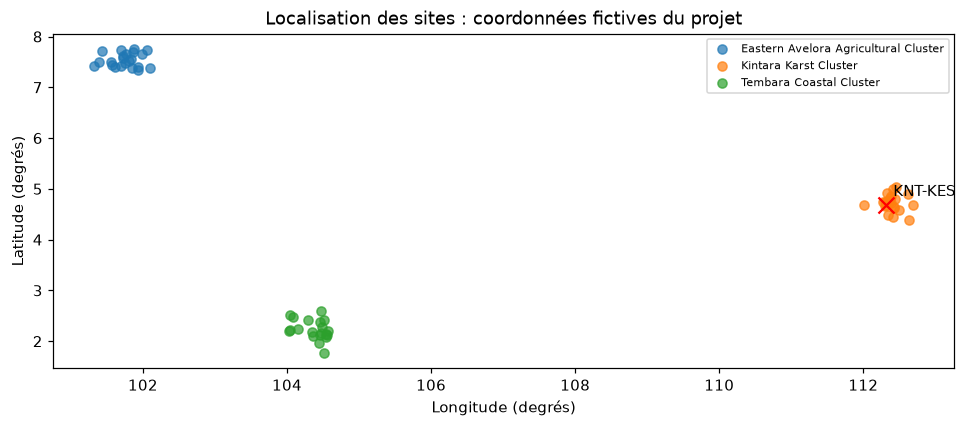

In [76]:
series_sites_ecology = ecologie_mensuelle.pivot(index='mois_releve', columns='site_code', values='observations_par_heure').sort_index().astype(float)
flags_fenetres_ecology = {}
for fenetre in [12, 24]:
    # Intervalle [t - fenetre/2, t + fenetre/2], bornes incluses.
    nombre_points = fenetre + 1
    voisinage = series_sites_ecology.rolling(
        window=nombre_points, center=True, min_periods=nombre_points
    )
    q1_local = voisinage.quantile(.25)
    q3_local = voisinage.quantile(.75)
    bas_local = q1_local - 1.5 * (q3_local - q1_local)
    haut_local = q3_local + 1.5 * (q3_local - q1_local)
    flags_fenetres_ecology[fenetre] = (
        series_sites_ecology.lt(bas_local) | series_sites_ecology.gt(haut_local)
    ).where(q1_local.notna())

resume_fenetres_ecology = pd.DataFrame(index=series_sites_ecology.columns)
for fenetre, indicateurs in flags_fenetres_ecology.items():
    resume_fenetres_ecology[f'signalements_{fenetre}_mois'] = indicateurs.sum().astype(int)
    resume_fenetres_ecology[f'mois_evalues_{fenetre}_mois'] = indicateurs.notna().sum().astype(int)
display(resume_fenetres_ecology.sort_values('signalements_12_mois', ascending=False).head(10))
print('KNT-KES :')
display(resume_fenetres_ecology.loc[[site_cible_ecology]])
fig, axe = plt.subplots(figsize=(9, 4))
for region, groupe in df_sites.groupby('region'):
    axe.scatter(groupe['longitude'], groupe['latitude'], label=region, alpha=.7)
cible_site_ecology = df_sites.loc[df_sites['site_code'].eq(site_cible_ecology)].iloc[0]
axe.scatter([cible_site_ecology['longitude']], [cible_site_ecology['latitude']], marker='x', s=110, color='red')
axe.annotate(site_cible_ecology, (cible_site_ecology['longitude'], cible_site_ecology['latitude']), xytext=(5, 6), textcoords='offset points')
axe.set(xlabel='Longitude (degrés)', ylabel='Latitude (degrés)', title='Localisation des sites : coordonnées fictives du projet')
axe.legend(fontsize=7)
plt.tight_layout()
plt.show()

Le graphique régional peut masquer un changement local. Inversement, une baisse
locale ne constitue pas une preuve de prélèvement. Il faut confronter les indices
aux appareils, à la météo et aux documents. Une absence de signalement par l'IQR
ne prouve pas non plus l'absence d'un événement : les distributions de comptage
et les saisons peuvent rendre la borne basse peu informative.
La carte sert à situer les sites, sans calculer de distances métriques sur des degrés.

Avec les fenêtres centrées, KNT-KES est signalé deux fois sur 66 mois évalués
pour Δt = 12 mois, et une fois sur 54 pour Δt = 24 mois. Il n'est premier
dans aucun des deux classements. Les deux durées n'évaluent pas les mêmes extrémités de série :
leurs nombres bruts ne sont donc pas directement interchangeables. Le repérage
reste dépendant du voisinage et ne rend pas le rapport ciblé inévitablement
détectable par une méthode statistique.

### Recherche systématique de baisses après retrait du motif calendaire

Le rapport attire l'attention sur KNT-KES, mais nous vérifions aussi les autres
sites. La référence reste fixée avant 2024. Pour chaque site et chaque mois,
nous soustrayons la médiane du même mois en 2019–2023, puis rapportons cet écart
à l'écart-type des résidus antérieurs du site. Ce score est descriptif et ne
constitue pas une probabilité. Les mêmes 60 observations servent à estimer
les 12 médianes : les seuils restent exploratoires et leur incertitude est réelle.

Nous présentons aussi une règle lisible sans score : un indice inférieur à
la moitié de sa référence calendaire. Les événements sont des mois consécutifs,
pas des nombres d'animaux prélevés. La règle n'identifie pas une cause.

La moitié de la référence est un seuil de baisse facile à lire, choisi
pour repérer des changements marqués ; ce n'est pas une limite biologique.
Le seuil −3 du score résiduel fournit un autre repère, fondé sur la dispersion
passée. Leur désaccord est conservé plutôt que de choisir après coup la règle
qui ferait ressortir KNT-KES.


In [77]:
suivi_desaisonnalise_ecology = comparaison_saison_ecology.copy()
suivi_desaisonnalise_ecology['residu_observe'] = suivi_desaisonnalise_ecology['observations_par_heure'] - suivi_desaisonnalise_ecology['observations_par_heure_reference']
stats_residus_avant_ecology = suivi_desaisonnalise_ecology.loc[suivi_desaisonnalise_ecology['survey_start'].lt('2024-01-01')].groupby('site_code')['residu_observe'].agg(['mean', 'std'])
suivi_desaisonnalise_ecology = suivi_desaisonnalise_ecology.merge(stats_residus_avant_ecology.rename(columns={'mean': 'residu_moyen_avant', 'std': 'residu_ecart_type_avant'}), on='site_code', how='left', validate='many_to_one')
suivi_desaisonnalise_ecology['z_residu_reference'] = (suivi_desaisonnalise_ecology['residu_observe'] - suivi_desaisonnalise_ecology['residu_moyen_avant']) / suivi_desaisonnalise_ecology['residu_ecart_type_avant'].replace(0, np.nan)
apres_reference_ecology = suivi_desaisonnalise_ecology.loc[suivi_desaisonnalise_ecology['survey_start'].ge('2024-01-01')].copy()
apres_reference_ecology['moins_moitie_reference'] = apres_reference_ecology['observations_par_heure_ratio'].lt(.5)
apres_reference_ecology['baisse_z_inf_moins3'] = apres_reference_ecology['z_residu_reference'].lt(-3)
classement_baisses_ecology = apres_reference_ecology.groupby('site_code').agg(
    mois_evalues=('survey_id', 'size'), mois_moins_moitie=('moins_moitie_reference', 'sum'),
    mois_z_inf_moins3=('baisse_z_inf_moins3', 'sum'), ratio_minimal=('observations_par_heure_ratio', 'min'),
    ratio_median=('observations_par_heure_ratio', 'median')
)
display(classement_baisses_ecology.sort_values(['mois_moins_moitie', 'ratio_minimal'], ascending=[False, True]).head(12).round(3))
print('KNT-KES, sans masquer les sites plus fortement signalés :')
display(classement_baisses_ecology.loc[['KNT-KES']].round(3))
evenements_baisse_ecology = []
for site, lignes in apres_reference_ecology.sort_values('mois_releve').groupby('site_code'):
    lignes = lignes.sort_values('mois_releve').copy()
    drapeau = lignes['moins_moitie_reference']
    groupes = drapeau.ne(drapeau.shift(fill_value=False)).cumsum()
    for _, episode in lignes.loc[drapeau].groupby(groupes.loc[drapeau]):
        evenements_baisse_ecology.append({'site_code': site, 'debut': str(episode['mois_releve'].min()), 'fin': str(episode['mois_releve'].max()), 'nombre_mois': len(episode), 'ratio_minimal': episode['observations_par_heure_ratio'].min()})
evenements_baisse_ecology = pd.DataFrame(evenements_baisse_ecology)
display(evenements_baisse_ecology.sort_values(['nombre_mois', 'ratio_minimal'], ascending=[False, True]).head(12).round(3))

KNT-KES, sans masquer les sites plus fortement signalés :


,mois_evalues,mois_moins_moitie,mois_z_inf_moins3,ratio_minimal,ratio_median
site_code,,,,,
TMB-PEL,18,7,0,0.198,0.9
AVL-GRB,18,5,0,0.0,0.863
KNT-KES,18,5,0,0.154,0.703
AVL-VEL,18,4,0,0.254,0.84
KNT-LUM,18,4,0,0.263,0.807
TMB-DLQ,18,4,0,0.34,0.885
AVL-ORR,18,3,0,0.181,0.963
KNT-YRG,18,3,0,0.24,1.224
TMB-UVF,18,3,0,0.273,0.846


,mois_evalues,mois_moins_moitie,mois_z_inf_moins3,ratio_minimal,ratio_median
site_code,,,,,
KNT-KES,18,5,0,0.154,0.703


,site_code,debut,fin,nombre_mois,ratio_minimal
64,TMB-PEL,2024-12,2025-04,5,0.198
24,AVL-VEL,2024-01,2024-04,4,0.254
9,AVL-GRB,2024-10,2024-11,2,0.000
31,KNT-KES,2024-04,2024-05,2,0.154
67,TMB-SKZ,2025-03,2025-04,2,0.273
63,TMB-PEL,2024-09,2024-10,2,0.296
39,KNT-NNM,2025-05,2025-06,2,0.367
32,KNT-KES,2024-10,2024-11,2,0.403
11,AVL-HTY,2025-04,2025-05,2,0.406
10,AVL-GRB,2025-02,2025-02,1,0.000


KNT-KES compte cinq mois sous la moitié de sa référence sur les dix-huit mois évalués, mais aucun score résiduel inférieur à −3. TMB-PEL compte sept mois sous la moitié et l'épisode le plus long dure cinq mois. La baisse n'est donc pas propre à KNT-KES : avril–mai 2024 y constitue un épisode à confronter au rapport, pas un résultat isolant à lui seul une collecte clandestine.

### Sensibilité à la qualité et à la disponibilité des appareils

Nous ne supprimons pas les observations originales. Nous recalculons les résumés
en excluant les relevés de qualité limitée, puis en exigeant en plus une disponibilité
mensuelle d'au moins 90 %. Cette dernière borne est un choix de sensibilité,
pas une garantie de bon fonctionnement pendant les heures exactes du relevé.
La référence 2019–2023 reste identique afin d'isoler l'effet de la sélection.

Le seuil de 90 % permet notamment d'examiner l'affirmation du rapport
sur des appareils disponibles à plus de 90 %. Le filtrage est présenté à côté
de l'analyse complète : le substituer à celle-ci pourrait masquer les périodes
de fonctionnement dégradé et changer la population comparée.


In [78]:
sensibilite_qualite_ecology = []
for nom, masque in [
    ('tous', pd.Series(True, index=apres_reference_ecology.index)),
    ('qualite_non_limitee', apres_reference_ecology['survey_quality'].ne('limited')),
    ('qualite_non_limitee_et_uptime_90', apres_reference_ecology['survey_quality'].ne('limited') & apres_reference_ecology['uptime_pct'].ge(90))
]:
    selection = apres_reference_ecology.loc[masque]
    cible = selection.loc[selection['site_code'].eq('KNT-KES')]
    sensibilite_qualite_ecology.append({'selection': nom, 'releves_tous_sites': len(selection), 'releves_KNT_KES': len(cible), 'mois_KNT_KES_moins_moitie': cible['moins_moitie_reference'].sum(), 'ratio_median_KNT_KES': cible['observations_par_heure_ratio'].median()})
display(pd.DataFrame(sensibilite_qualite_ecology).round(3))
display(apres_reference_ecology.loc[apres_reference_ecology['site_code'].eq('KNT-KES') & apres_reference_ecology['moins_moitie_reference'], ['mois_releve', 'observations_par_heure_ratio', 'z_residu_reference', 'uptime_pct', 'acoustic_quality', 'survey_quality', 'weather_interference']])

,selection,releves_tous_sites,releves_KNT_KES,mois_KNT_KES_moins_moitie,ratio_median_KNT_KES
0,tous,1152,18,5,0.703
1,qualite_non_limitee,1116,18,5,0.703
2,qualite_non_limitee_et_uptime_90,882,13,4,0.762


,mois_releve,observations_par_heure_ratio,z_residu_reference,uptime_pct,acoustic_quality,survey_quality,weather_interference
63,2024-04,0.459223,-1.850171,83.1,73.1,acceptable,29.9
64,2024-05,0.154019,-2.868233,91.8,71.4,acceptable,47.0
69,2024-10,0.403349,-1.088409,98.7,82.9,high,20.6
70,2024-11,0.477969,-1.113844,93.0,79.3,high,20.6
73,2025-02,0.490602,-1.536707,100.0,77.3,acceptable,18.6


Écarter les qualités limitées ne change pas les cinq mois signalés à KNT-KES. Exiger en plus une disponibilité d'au moins 90 % laisse treize mois, dont quatre sous la moitié de la référence. Avril 2024 est écarté (83,1 %), mais mai reste signalé (ratio 0,154 ; disponibilité 91,8 %). Le résultat n'est donc pas entièrement effacé par ce filtre, sans que celui-ci valide la cause de la baisse.

### Mois analogues sur les conditions de collecte et d'environnement

Nous cherchons des comparaisons supplémentaires pour avril et mai 2024 : mêmes
mois calendaires, même habitat et même région, avant 2024, sur les autres sites.
La proximité utilise température, pluie, humidité, disponibilité et qualité
acoustique, sans utiliser le comptage pour sélectionner les analogues.
Nous comparons les ratios à la référence propre à chaque site afin de ne pas
confondre sites naturellement très peuplés et sites plus faiblement peuplés.
La sélection reste observationnelle et ne contrôle pas toutes les causes possibles.

Les cinq plus proches mois sont retenus pour examiner plusieurs cas,
plutôt qu'un voisin unique qui pourrait être particulier. Ce nombre n'a pas été
optimisé et les distances sont affichées pour rendre la proximité contrôlable.
Les analogues antérieurs contribuent eux-mêmes à leur référence 2019–2023,
contrairement à la cible de 2024 : leurs ratios ne constituent donc pas une
distribution prédictive indépendante du mois ciblé.

La mise à l'échelle est estimée sur les candidats antérieurs, puis appliquée
au mois ciblé. Elle sert à pondérer la distance, sans recalibrer les pourcentages
ou l'indice de qualité. Un autre poids des conditions pourrait changer les voisins ;
la sélection n'est donc pas présentée comme un appariement causal validé.

In [79]:
covariables_analogues_ecology = ['mean_temperature_c', 'rainfall_mm', 'mean_humidity_pct', 'uptime_pct', 'acoustic_quality']
analogues_mois_ecology = []
sensibilite_voisins_ecology = []
for mois in ['2024-04', '2024-05']:
    cible = suivi_desaisonnalise_ecology.loc[suivi_desaisonnalise_ecology['site_code'].eq('KNT-KES') & suivi_desaisonnalise_ecology['mois_releve'].eq(pd.Period(mois))].iloc[0]
    candidats = suivi_desaisonnalise_ecology.loc[
        suivi_desaisonnalise_ecology['survey_start'].lt('2024-01-01') &
        suivi_desaisonnalise_ecology['site_code'].ne('KNT-KES') &
        suivi_desaisonnalise_ecology['habitat_category'].eq(cible['habitat_category']) &
        suivi_desaisonnalise_ecology['region'].eq(cible['region']) &
        suivi_desaisonnalise_ecology['mois_calendaire'].eq(cible['mois_calendaire'])
    ].copy()
    standardisation = StandardScaler().fit(candidats[covariables_analogues_ecology])
    candidats['distance_conditions'] = pairwise_distances(standardisation.transform(cible[covariables_analogues_ecology].to_frame().T), standardisation.transform(candidats[covariables_analogues_ecology]))[0]
    for nombre in [3, 5, 10]:
        voisins = candidats.nsmallest(nombre, 'distance_conditions')
        sensibilite_voisins_ecology.append({
            'mois_cible': mois, 'nombre_voisins_demande': nombre, 'nombre_disponible': len(voisins),
            'ratio_cible': cible['observations_par_heure_ratio'],
            'ratio_observe_median_voisins': voisins['observations_par_heure_ratio'].median(),
            'minimum_voisins': voisins['observations_par_heure_ratio'].min(),
            'maximum_voisins': voisins['observations_par_heure_ratio'].max(),
            'distance_maximale': voisins['distance_conditions'].max()
        })
    plus_proches = candidats.nsmallest(5, 'distance_conditions').copy()
    plus_proches['mois_cible'] = mois
    analogues_mois_ecology.append(plus_proches)
analogues_mois_ecology = pd.concat(analogues_mois_ecology, ignore_index=True)
display(analogues_mois_ecology[['mois_cible', 'site_code', 'mois_releve', 'distance_conditions', 'observations_par_heure_ratio', 'detections_acoustiques_par_heure_ratio']])
display(analogues_mois_ecology.groupby('mois_cible').agg(ratio_observe_median=('observations_par_heure_ratio', 'median'), minimum_observe=('observations_par_heure_ratio', 'min'), maximum_observe=('observations_par_heure_ratio', 'max')).round(3))
sensibilite_voisins_ecology = pd.DataFrame(sensibilite_voisins_ecology)
display(sensibilite_voisins_ecology.round(3))

,mois_cible,site_code,mois_releve,distance_conditions,observations_par_heure_ratio,detections_acoustiques_par_heure_ratio
0,2024-04,KNT-LUM,2022-04,0.891087,1.060311,1.335992
1,2024-04,KNT-CYP,2019-04,1.031331,0.526116,0.794543
2,2024-04,KNT-CYP,2021-04,1.224250,0.668919,1.073342
3,2024-04,KNT-NNM,2020-04,1.309824,1.0,1.091045
4,2024-04,KNT-LUM,2019-04,1.324126,1.0,0.85
5,2024-05,KNT-CHP,2022-05,1.419486,1.098908,0.617249
6,2024-05,KNT-QWU,2019-05,1.541564,0.948395,1.770338
7,2024-05,KNT-BME,2020-05,1.548338,1.177476,0.950628
8,2024-05,KNT-QWU,2022-05,1.594622,1.0,1.0
9,2024-05,KNT-NNM,2020-05,1.785142,1.147283,1.005972


,ratio_observe_median,minimum_observe,maximum_observe
mois_cible,,,
2024-04,1.0,0.526,1.06
2024-05,1.099,0.948,1.177


,mois_cible,nombre_voisins_demande,nombre_disponible,ratio_cible,ratio_observe_median_voisins,minimum_voisins,maximum_voisins,distance_maximale
0,2024-04,3,3,0.459,0.669,0.526,1.060,1.224
1,2024-04,5,5,0.459,1.000,0.526,1.060,1.324
2,2024-04,10,10,0.459,0.863,0.431,1.060,1.557
3,2024-05,3,3,0.154,1.099,0.948,1.177,1.548
4,2024-05,5,5,0.154,1.099,0.948,1.177,1.785
5,2024-05,10,10,0.154,1.000,0.577,1.177,2.010


En avril, les médianes des analogues valent 0,669, 1,000 et 0,863 avec
trois, cinq et dix voisins, contre 0,459 pour KNT-KES. Avec dix voisins,
un analogue a toutefois un ratio de 0,431 : la cible n'est pas plus basse
que tous les cas comparables. En mai, les médianes valent 1,099, 1,099 et
1,000, contre 0,154 pour la cible. Le contraste de mai persiste dans ces essais.

Le tableau conserve la distance maximale : davantage de voisins élargit
le contexte et diminue leur proximité. Le résultat principal garde cinq
analogues, sans optimiser ce nombre pour accentuer l'écart. Leurs références
incluent leurs observations historiques, contrairement à la cible de 2024 :
ce contraste reste descriptif, pas une comparaison causale.

### Phénologie des vergers et variations d'activité

Nous comparons les profils par mois calendaire et les écarts à la médiane du
même site et du même mois. Cette décomposition descriptive vise à séparer
une relation liée au calendrier d'une association restant visible entre écarts.
Elle ne mesure pas un effet de pollinisation et ne permet pas de relier une
récolte à un lot de chauves-souris transporté.

,correlation_brute_spearman,correlation_ecarts_site_mois_spearman
fruit_set_rate_pct,0.477,0.189
rendement_kg_ha,0.448,0.143
durian_flower_density,0.270,0.169
other_pollinator_activity,0.314,0.071
pesticide_index,-0.404,-0.302


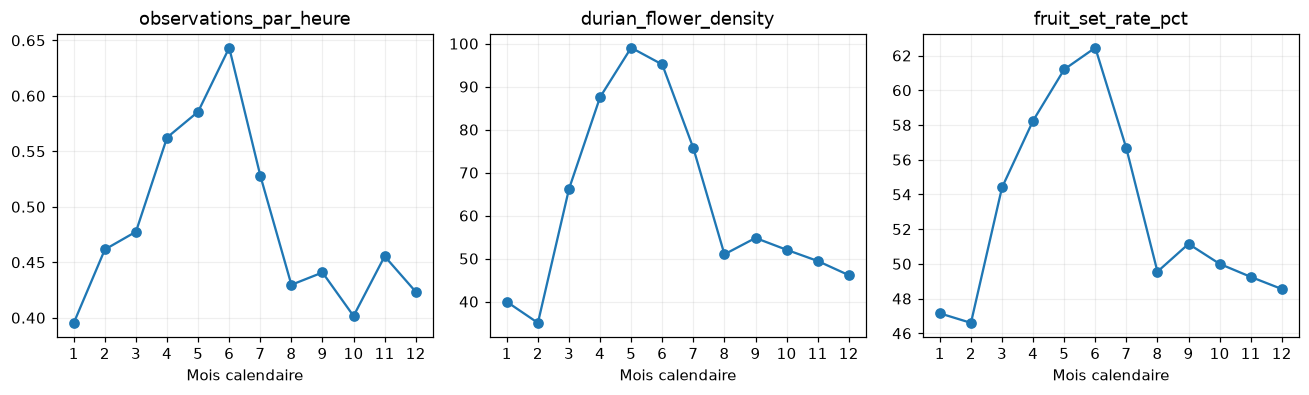

In [80]:
vergers_saison_ecology = vergers_contextuels_ecology.copy()
vergers_saison_ecology['mois_calendaire'] = vergers_saison_ecology['survey_period'].dt.month
variables_phenologie_ecology = ['observations_par_heure', 'fruit_set_rate_pct', 'rendement_kg_ha', 'durian_flower_density', 'other_pollinator_activity', 'pesticide_index']
medians_calendaires_vergers_ecology = vergers_saison_ecology.groupby(['site_code', 'mois_calendaire'])[variables_phenologie_ecology].transform('median')
ecarts_calendaires_vergers_ecology = vergers_saison_ecology[variables_phenologie_ecology] - medians_calendaires_vergers_ecology
comparaison_saison_vergers_ecology = pd.DataFrame({
    'correlation_brute_spearman': vergers_saison_ecology[variables_phenologie_ecology].corr(method='spearman')['observations_par_heure'],
    'correlation_ecarts_site_mois_spearman': ecarts_calendaires_vergers_ecology.corr(method='spearman')['observations_par_heure']
})
display(comparaison_saison_vergers_ecology.drop(index='observations_par_heure').round(3))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.7))
for axe, variable in zip(axes, ['observations_par_heure', 'durian_flower_density', 'fruit_set_rate_pct']):
    vergers_saison_ecology.groupby('mois_calendaire')[variable].median().plot(ax=axe, marker='o')
    axe.set(title=variable, xlabel='Mois calendaire')
    axe.set_xticks(range(1,13))
    axe.grid(alpha=.2)
plt.tight_layout()
plt.show()

L'activité et la floraison culminent globalement vers mai–juin dans les profils calendaires. La corrélation activité–nouaison diminue de 0,477 à 0,189 sur les écarts au même site et au même mois ; celle avec le rendement passe de 0,448 à 0,143. L'atténuation est compatible avec une part de l'association liée au site et au calendrier ; elle n'en mesure pas une contribution causale. Le lien résiduel reste descriptif : ce tableau ne chiffre pas l'effet propre des chauves-souris sur la récolte.

## Cours 6 — Documents de terrain et limites de l'analyse lexicale

**Question.** Les rapports apportent-ils des éléments distinctifs, ou répètent-ils
principalement des modèles rédactionnels ? Nous calculons TF-IDF sur les mots
et les bigrammes, puis la similarité cosinus. Les termes rares sont conservés
avec `min_df=1`, car ils peuvent être importants dans ce petit corpus.

La copie d'analyse décode les sauts de ligne littéraux, harmonise la casse,
la ponctuation et les espaces. Les traits d'union sont conservés pour les codes
et mots composés. Les stopwords anglais sont retirés, et les termes présents
dans plus de 95 % des rapports sont exclus comme vocabulaire commun.
Le texte original reste disponible. Une similarité lexicale ne signifie pas une
confirmation factuelle. Le retrait de mots fréquents peut faire perdre des
négations : les passages retenus sont donc relus intégralement, dans leur contexte.

In [81]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

df_rapports['texte_analyse'] = (df_rapports['text'].astype('string')
    .str.replace(r'\r\n', '\n', regex=False)
    .str.replace(r'\n', '\n', regex=False)
    .str.lower().str.replace(r'[^\w\s-]', ' ', regex=True)
    .str.replace(r'\s+', ' ', regex=True).str.strip())
assert df_rapports['texte_analyse'].str.len().gt(0).all()

vectoriseur_rapports_ecology = TfidfVectorizer(stop_words='english', ngram_range=(1, 2), min_df=1, max_df=.95)
matrice_tfidf_ecology = vectoriseur_rapports_ecology.fit_transform(df_rapports['texte_analyse'])
termes_rapports_ecology = vectoriseur_rapports_ecology.get_feature_names_out()
similarites_rapports_ecology = cosine_similarity(matrice_tfidf_ecology)
similarites_voisins_ecology = similarites_rapports_ecology.copy()
np.fill_diagonal(similarites_voisins_ecology, -np.inf)
positions_voisins_ecology = similarites_voisins_ecology.argmax(axis=1)
resume_textes_ecology = df_rapports[['document_id', 'document_type']].copy()
resume_textes_ecology['document_voisin'] = df_rapports['document_id'].to_numpy()[positions_voisins_ecology]
resume_textes_ecology['similarite_maximale'] = similarites_voisins_ecology.max(axis=1)
resume_textes_ecology['meme_type'] = df_rapports['document_type'].to_numpy() == df_rapports['document_type'].to_numpy()[positions_voisins_ecology]
print('Documents / termes :', matrice_tfidf_ecology.shape)
display(resume_textes_ecology.sort_values('similarite_maximale').head(8).round(3))
print('Plus proche voisin de même type :', resume_textes_ecology['meme_type'].sum(), 'sur', len(df_rapports))
position_incident_ecology = df_rapports.index.get_loc(df_rapports.index[df_rapports['document_id'].eq('EFR-510088')][0])
scores_incident_ecology = matrice_tfidf_ecology[position_incident_ecology].toarray().ravel()
display(pd.DataFrame({'terme': termes_rapports_ecology, 'tfidf': scores_incident_ecology}).nlargest(15, 'tfidf').round(3))

Documents / termes : (30, 768)
Plus proche voisin de même type : 29 sur 30


,document_id,document_type,document_voisin,similarite_maximale,meme_type
0,EFR-510088,ecological_incident_report,EFR-510095,0.087,True
1,EFR-510082,field_observation,EFR-510054,0.495,False
7,EFR-510026,monitoring_report,EFR-510042,0.562,True
3,EFR-510007,field_observation,EFR-510031,0.574,True
8,EFR-510037,monitoring_report,EFR-510019,0.596,True
9,EFR-510054,monitoring_report,EFR-510042,0.605,True
25,EFR-510077,ecological_incident_report,EFR-510130,0.606,True
5,EFR-510020,field_observation,EFR-510031,0.613,True


,terme,tfidf
175,conducted,0.129
205,cut,0.129
424,material,0.129
520,post,0.129
521,post access,0.129
545,record,0.129
321,handling,0.115
34,access,0.101
347,inspection,0.091
267,entrance,0.081


La matrice comporte 30 documents et 768 termes ou bigrammes. Pour 29 documents,
le plus proche voisin est du même type documentaire, ce qui correspond à des
modèles rédactionnels récurrents. EFR-510088 est beaucoup moins proche du reste
du corpus : sa similarité maximale est d'environ 0,087. Son vocabulaire distinctif
motive une lecture attentive, mais la rareté lexicale ne prouve pas sa véracité.

### LSA : structure documentaire et lecture des termes en contexte

Pour comparer à la représentation TF-IDF complète, nous testons cinq composantes
LSA par SVD. Ce nombre est un choix exploratoire, pas la preuve de cinq thèmes.
Les composantes sont signées : les mots de poids positif et négatif sont présentés.
Une projection qui explique peu de variance ne peut pas remplacer les similarités
calculées dans l'espace complet. Nous vérifions aussi les contextes littéraux
des expressions liées à la collecte : les bigrammes créés après retrait des
stopwords ne sont pas toujours adjacents dans le texte original.

In [82]:
from sklearn.decomposition import TruncatedSVD

lsa_rapports_ecology = TruncatedSVD(n_components=5, random_state=42)
projection_lsa_ecology = lsa_rapports_ecology.fit_transform(matrice_tfidf_ecology)
print('Variance expliquée par composante :', lsa_rapports_ecology.explained_variance_ratio_.round(3))
print('Variance expliquée cumulée :', round(lsa_rapports_ecology.explained_variance_ratio_.sum(), 3))
termes_lsa_ecology = []
for numero, poids in enumerate(lsa_rapports_ecology.components_, start=1):
    termes_lsa_ecology.append({'composante': numero, 'termes_positifs': ', '.join(termes_rapports_ecology[np.argsort(poids)[-7:][::-1]]), 'termes_negatifs': ', '.join(termes_rapports_ecology[np.argsort(poids)[:7]])})
display(pd.DataFrame(termes_lsa_ecology))
contextes_collecte_ecology = []
for document in df_rapports.itertuples(index=False):
    for paragraphe in document.text.replace('\r\n', '\n').split('\n\n'):
        if re.search(r'licensed bat collection|all animals were returned|does not assign|does not convert|removal or handling', paragraphe, flags=re.I):
            contextes_collecte_ecology.append({'document_id': document.document_id, 'passage_original': paragraphe.strip()})
display(pd.DataFrame(contextes_collecte_ecology).drop_duplicates().head(12))

Variance expliquée par composante : [0.032 0.195 0.151 0.111 0.099]
Variance expliquée cumulée : 0.588


,composante,termes_positifs,termes_negatifs
0,1,"access, seasonal, habitat disturbance, movemen...","monitoring maintenance, monitoring team, moder..."
1,2,"lower detection, invalidate, interval device, ...","access, habitat disturbance, maintenance, asse..."
2,3,"equipment observed, entrance secure, disturban...","rainfall, neighboring, repeat, comparison neig..."
3,4,"completed, team, interval vegetation, limitati...","temporary, incident, evidence, rainfall, short..."
4,5,"temporary, evidence, incident, path inspection...","orchard, neighboring, microclimate review, mic..."


,document_id,passage_original
0,EFR-510088,UNCERTAINTY\nThe observations are consistent w...
1,EFR-510082,The report does not convert an unusual count i...
2,EFR-510082,AUTHORIZED ACTIVITY\nA licensed bat collection...
3,EFR-510035,The report does not convert an unusual count i...
4,EFR-510007,The report does not convert an unusual count i...
5,EFR-510031,The report does not convert an unusual count i...
6,EFR-510020,The report does not convert an unusual count i...
7,EFR-510048,The report does not convert an unusual count i...
8,EFR-510026,The report does not convert an unusual count i...
10,EFR-510026,PERMIT CONTEXT\nA separate licensed bat collec...


Les cinq composantes conservent 58,8 % de la variance. Elles décrivent une structure lexicale partielle, largement influencée par les formulations récurrentes des rapports. Les termes positifs et négatifs ne sont pas des diagnostics. La lecture des passages originaux reste nécessaire pour distinguer une collecte autorisée avec remise en liberté, une hypothèse de manipulation et une négation explicite.

### Lecture du rapport ciblé et de deux contre-exemples

Nous lisons le rapport qui motive l'étude de KNT-KES, un rapport mentionnant
une collecte autorisée avec remise en liberté et un incident attribué à des
perturbations ordinaires. Cette comparaison évite de sélectionner seulement
les passages compatibles avec l'hypothèse d'un prélèvement clandestin.

In [83]:
from IPython.display import Markdown

for identifiant in ['EFR-510088', 'EFR-510082', 'EFR-510077']:
    document = df_rapports.loc[df_rapports['document_id'].eq(identifiant)].iloc[0]
    display(Markdown('#### ' + identifiant + ' — ' + document['title']))
    display(document[['site_code', 'document_date', 'author_name', 'author_organization', 'related_survey_id', 'related_device_reference', 'publication_status']].to_frame('valeur'))
    display(Markdown(document['text']))

controle_incident_ecology = liens_rapports_ecology.loc[liens_rapports_ecology['document_id'].eq('EFR-510088')]
display(controle_incident_ecology[['document_id', 'document_date', 'survey_start', 'document_avant_releve', 'mois_concordant']])
mesure_incident_ecology = ecologie_mensuelle.loc[ecologie_mensuelle['survey_id'].eq('BAT-0000064')]
display(mesure_incident_ecology[['survey_id', 'site_code', 'mois_releve', 'observed_bat_count', 'acoustic_detection_count', 'uptime_pct', 'acoustic_quality', 'fault_code']])

#### EFR-510088 — Post-Access Ecological Incident at KNT-KES

,valeur
site_code,KNT-KES
document_date,2024-04-02 00:00:00
author_name,Anika Dren
author_organization,Horizon Field Research Cooperative
related_survey_id,BAT-0000064
related_device_reference,DEV-KNTKES-2
publication_status,restricted


INCIDENT
A post-access inspection was conducted at KNT-KES after the March access window. The acoustic station remained operational, but the subsequent survey recorded a marked reduction in *Eonycteris spelaea* activity compared with other environmentally similar months.

EVIDENCE
Device uptime was above ninety percent and the acoustic-quality record did not show a sustained fault. Weather interference was moderate and does not account for the full change. Visual inspection identified fresh handling marks near the secondary entrance, two short lengths of cut restraint material, and disturbed sediment along a route not used by the monitoring team. No dead animals were found. The access register confirms authorized equipment entry, although the declared purpose was routine monitoring maintenance.

IMMEDIATE ACTION
The entrance was photographed, the cut material was retained, and the station configuration was checked against the prior record. A repeat survey and a comparison with adjacent sites were requested. The access authority was asked to preserve the associated case file.

UNCERTAINTY
The observations are consistent with recent removal or handling activity, but they do not identify who conducted it or why. Seasonal movement, unrecorded disturbance, and temporary roost relocation remain alternatives. The report therefore records an unexplained post-access bat deficit with functioning devices and physical traces; it does not assign a covert operation or final use.

#### EFR-510082 — Field Observation 27

,valeur
site_code,KNT-JAK
document_date,2019-04-01 00:00:00
author_name,Vera Waren
author_organization,Pollinator Justice Network
related_survey_id,BAT-0001000
related_device_reference,DEV-KNTJAK-3
publication_status,restricted


SITE AND TIME
Field observation at KNT-JAK during sensor maintenance cycle.

METHOD
The team completed a standard dusk transect and reviewed survey BAT-0001000. Effort and weather were recorded.

OBSERVATIONS
Bat activity and comparison-species counts varied across the interval. Vegetation and access conditions showed no acute change.

LIMITATIONS
Wind and intermittent background noise reduced certainty in part of the survey.

The reporting interval concerns sensor maintenance cycle and includes recorded effort, weather, and device-quality limitations.

Bat activity was interpreted alongside habitat condition, flowering, fruit set, disturbance, and comparison-species observations.

The programme retained raw survey and device references so that low counts can be separated from poor monitoring coverage.

Observed changes may reflect movement, weather, access, pesticide exposure, habitat disturbance, or ordinary seasonal variation.

The report does not convert an unusual count into a claim about organized removal.

A repeat interval and comparison with neighboring sites were recommended.

The reporting interval concerns sensor maintenance cycle and includes recorded effort, weather, and device-quality limitations.

AUTHORIZED ACTIVITY
A licensed bat collection for tagging and release was completed by the conservation team; all animals were returned at the capture point.

#### EFR-510077 — Ecological Incident Report 51

,valeur
site_code,KNT-TEX
document_date,2019-04-07 00:00:00
author_name,Doran Norel
author_organization,Horizon Field Research Cooperative
related_survey_id,BAT-0001888
related_device_reference,DEV-KNTTEX-3
publication_status,internal


INCIDENT
An ordinary ecological incident was recorded at KNT-TEX during sensor maintenance cycle.

EVIDENCE
Survey BAT-0001888 showed a short-term reduction in activity. Heavy rainfall, access noise, and temporary device shielding were documented.

RESPONSE
The device was inspected and a repeat survey scheduled.

UNCERTAINTY
The available evidence favors temporary disturbance but does not exclude seasonal movement.

The reporting interval concerns sensor maintenance cycle and includes recorded effort, weather, and device-quality limitations.

Bat activity was interpreted alongside habitat condition, flowering, fruit set, disturbance, and comparison-species observations.

The programme retained raw survey and device references so that low counts can be separated from poor monitoring coverage.

Observed changes may reflect movement, weather, access, pesticide exposure, habitat disturbance, or ordinary seasonal variation.

The report does not convert an unusual count into a claim about organized removal.

A repeat interval and comparison with neighboring sites were recommended.

The reporting interval concerns sensor maintenance cycle and includes recorded effort, weather, and device-quality limitations.

Bat activity was interpreted alongside habitat condition, flowering, fruit set, disturbance, and comparison-species observations.

The programme retained raw survey and device references so that low counts can be separated from poor monitoring coverage.

,document_id,document_date,survey_start,document_avant_releve,mois_concordant
0,EFR-510088,2024-04-02,2024-04-05 18:00:00,True,True


,survey_id,site_code,mois_releve,observed_bat_count,acoustic_detection_count,uptime_pct,acoustic_quality,fault_code
63,BAT-0000064,KNT-KES,2024-04,10,15,83.1,73.1,NaN


### Ce que les sources confirment et ce qu'elles ne confirment pas

Le rapport `EFR-510088` décrit des traces de manipulation et l'absence de cadavres.
Ce sont des affirmations documentaires, pas des observations que nous pouvons
vérifier indépendamment dans les tables. Le texte conserve lui-même les hypothèses
de déplacement saisonnier, de perturbation non enregistrée et de changement de gîte.

Deux discordances nécessitent de la prudence :

- le document du 2 avril 2024 cite un relevé commençant le 5 avril 2024 ;
- il affirme une disponibilité supérieure à 90 %, alors que la ligne mensuelle
  de l'appareil lié à avril indique 83,1 %. La disponibilité mensuelle n'est pas
  nécessairement celle des seules heures observées, mais elle ne confirme pas
  directement le chiffre du rapport.

Nous ne corrigeons ni les dates ni les mesures pour les faire correspondre au récit.
L'absence de code de panne n'exclut pas un problème technique. Les documents
`EFR-510082` et `EFR-510077` montrent aussi que collecte, activité basse et accès
ne suffisent pas à identifier une opération clandestine.

## Rapprochements vérifiables avec Public Records et Logistics

Les informations rapportées par les autres membres du groupe sont des pistes,
pas des faits ajoutés aux données Ecology. Nous vérifions ici les références
disponibles sans modifier leurs notebooks. Un nom semblable ou une date proche
ne suffit pas pour identifier un lot biologique.

In [84]:
acces_ecology = pd.read_csv('data/public_records/site_access_case_events.csv').drop_duplicates()
acces_ecology['event_time'] = pd.to_datetime(acces_ecology['event_time'], format='mixed', errors='raise')
acces_cible_ecology = acces_ecology.loc[acces_ecology['site_code'].eq(site_cible_ecology)].sort_values('event_time')
acces_2024_ecology = acces_cible_ecology.loc[acces_cible_ecology['event_time'].between('2024-01-01', '2024-12-31')]
display(acces_2024_ecology[['access_event_id', 'access_case_number', 'event_time', 'activity', 'requesting_registration_number', 'requesting_organization_name', 'confidentiality_class']])

,access_event_id,access_case_number,event_time,activity,requesting_registration_number,requesting_organization_name,confidentiality_class
104,ACE-000105,ACC-2024-0014,2024-02-19 09:00:00,request_submitted,REG-AVL-01013,Horizon Field Research Cooperative,restricted
105,ACE-000106,ACC-2024-0014,2024-02-25 09:00:00,technical_review,REG-AVL-01013,Horizon Field Research Cooperative,restricted
106,ACE-000107,ACC-2024-0014,2024-03-01 09:00:00,wildlife_review,REG-AVL-01013,Horizon Field Research Cooperative,restricted
107,ACE-000108,ACC-2024-0014,2024-03-11 09:00:00,authorization_granted,REG-AVL-01013,Horizon Field Research Cooperative,restricted
108,ACE-000109,ACC-2024-0014,2024-03-21 18:00:00,access_started,REG-AVL-01013,Horizon Field Research Cooperative,restricted
109,ACE-000110,ACC-2024-0014,2024-03-22 03:00:00,access_completed,REG-AVL-01013,Horizon Field Research Cooperative,restricted
110,ACE-000111,ACC-2024-0014,2024-03-24 11:00:00,closure_recorded,REG-AVL-01013,Horizon Field Research Cooperative,restricted


### Relier les organisations par leur numéro

Nous utilisons le numéro d’enregistrement, pas seulement le nom, pour rechercher un partenaire logistique. Une relation entre organisations ne prouve pas le contenu d’une expédition.

In [85]:
partenaires_ecology = pd.read_csv('data/logistics/erp_business_partners.csv').drop_duplicates()
assert partenaires_ecology['partner_code'].is_unique
organisations_acces_ecology = acces_2024_ecology[['requesting_registration_number', 'requesting_organization_name']].drop_duplicates()
partenaires_lies_ecology = organisations_acces_ecology.merge(partenaires_ecology, left_on='requesting_registration_number', right_on='external_registration_number', how='left', validate='one_to_many')
display(partenaires_lies_ecology[['requesting_registration_number', 'requesting_organization_name', 'partner_code', 'partner_name']])
expeditions_ecology = pd.read_csv('data/logistics/shipments.csv').drop_duplicates()
codes_partenaires_ecology = partenaires_lies_ecology['partner_code'].dropna()
expeditions_liees_ecology = expeditions_ecology.loc[expeditions_ecology['sender_partner_code'].isin(codes_partenaires_ecology) | expeditions_ecology['receiver_partner_code'].isin(codes_partenaires_ecology)].copy()
expeditions_liees_ecology['dispatch_time'] = pd.to_datetime(expeditions_liees_ecology['dispatch_time'], format='mixed', errors='raise')
print("Expéditions distinctes liées au partenaire identifié, toutes dates :", expeditions_liees_ecology['shipment_number'].nunique())
display(expeditions_liees_ecology.groupby(['item_category', 'declared_purpose']).size().rename('nombre_lignes').to_frame())

Expéditions distinctes liées au partenaire identifié, toutes dates : 55


,requesting_registration_number,requesting_organization_name,partner_code,partner_name
0,REG-AVL-01013,Horizon Field Research Cooperative,BP-30056,Horizon Field Research Cooperative


nombre_lignes
item_category          declared_purpose                                             
agricultural_equipment agricultural distribution                                   1
agricultural_product   agricultural distribution                                   1
                       customer distribution                                       1
                       facility replenishment                                      1
                       laboratory delivery                                         3
                       scheduled stock transfer                                    1
biological_sample      environmental and wildlife reference materials             18
                       facility replenishment                                      1
                       field programme support                                     2
                       laboratory delivery                                         1
cold_storage_equipment agricultural distribution                                   1
                       field programme support                                     1
communication_service  facility replenishment                                      1
consulting_service     customer distribution                                       1
                       facility replenishment                                      1
laboratory_material    agricultural distribution                                   1
                       facility replenishment                                      1
                       laboratory delivery                                         2
medical_consumables    agricultural distribution                                   1
                       scheduled stock transfer                                    1
medical_equipment      agricultural distribution                                   1
                       facility replenishment                                      1
monitoring_equipment   agricultural distribution                                   1
                       customer distribution                                       1
                       laboratory delivery                                         1
office_supply          laboratory delivery                                         1
other                  laboratory delivery                                         1
                       scheduled stock transfer                                    1
protective_equipment   facility replenishment                                      1
refrigeration_service  customer distribution                                       1
                       laboratory delivery                                         1
research_contract      agricultural distribution                                   1
transport_service      agricultural distribution                                   1
                       scheduled stock transfer                                    1

### Vérifier les références explicites aux expéditions

Les dossiers réglementaires donnent des références de transport. Nous vérifions les expéditions, les rôles des partenaires et leur chronologie ; une date proche, seule, ne suffit pas.

In [86]:
reglementaire_ecology = pd.read_csv('data/public_records/regulatory_case_events.csv').drop_duplicates()
cas_lies_ecology = reglementaire_ecology.loc[reglementaire_ecology['related_site_code'].eq(site_cible_ecology)]
references_expeditions_ecology = cas_lies_ecology[['case_number', 'related_site_code', 'related_shipment_number']].drop_duplicates()
expeditions_referencees_ecology = references_expeditions_ecology.merge(expeditions_ecology, left_on='related_shipment_number', right_on='shipment_number', how='left', validate='one_to_many', indicator=True)
noms_partenaires_ecology = partenaires_ecology.set_index('partner_code')['partner_name']
for role in ['sender', 'receiver', 'carrier']:
    expeditions_referencees_ecology[role + '_name'] = expeditions_referencees_ecology[role + '_partner_code'].map(noms_partenaires_ecology)
display(expeditions_referencees_ecology[['case_number', 'related_site_code', 'shipment_number', 'dispatch_time', 'sender_name', 'receiver_name', 'carrier_name', 'declared_quantity', 'declared_unit', 'temperature_control_class', '_merge']])
facilites_logistiques_ecology = pd.read_csv('data/logistics/erp_facilities.csv').drop_duplicates()
codes_facilites_ecology = set(expeditions_referencees_ecology['origin_facility_code'].dropna()) | set(expeditions_referencees_ecology['destination_facility_code'].dropna())
display(facilites_logistiques_ecology.loc[facilites_logistiques_ecology['facility_code'].isin(codes_facilites_ecology), ['facility_code', 'facility_name', 'operating_partner_code']])
debut_cas_ecology = cas_lies_ecology.assign(date_evenement=dates_heures_ecology(cas_lies_ecology['event_time'])).groupby('case_number')['date_evenement'].min()
controle_chronologie_expeditions_ecology = expeditions_referencees_ecology[['case_number', 'shipment_number', 'dispatch_time']].copy()
controle_chronologie_expeditions_ecology['debut_cas'] = controle_chronologie_expeditions_ecology['case_number'].map(debut_cas_ecology)
controle_chronologie_expeditions_ecology['date_depart'] = dates_heures_ecology(controle_chronologie_expeditions_ecology['dispatch_time'])
controle_chronologie_expeditions_ecology['depart_apres_ouverture_cas'] = controle_chronologie_expeditions_ecology['date_depart'].gt(controle_chronologie_expeditions_ecology['debut_cas'])
display(controle_chronologie_expeditions_ecology)

,case_number,related_site_code,shipment_number,dispatch_time,sender_name,receiver_name,carrier_name,declared_quantity,declared_unit,temperature_control_class,_merge
0,REG-2019-0002,KNT-KES,SHP-2018-00007,2018-03-23T09:00:00,Horizon Field Research Cooperative,Meridian BioLogistics,Northstar Cold Chain Services,5,sealed_lot,2-8C,both
1,REG-2023-0008,KNT-KES,SHP-2024-00007,2024-03-22T09:00:00,Horizon Field Research Cooperative,Meridian BioLogistics,Northstar Cold Chain Services,6,sealed_lot,2-8C,both


,facility_code,facility_name,operating_partner_code
1,FCL-1024,Meridian Kintara Biological Aggregation Facility,BP-30078
7,FCL-1030,Kintara Cave Authority Field Depot,BP-30016


,case_number,shipment_number,dispatch_time,debut_cas,date_depart,depart_apres_ouverture_cas
0,REG-2019-0002,SHP-2018-00007,2018-03-23T09:00:00,2019-03-08 09:00:00,2018-03-23 09:00:00,False
1,REG-2023-0008,SHP-2024-00007,2024-03-22T09:00:00,2023-04-10 09:00:00,2024-03-22 09:00:00,True


### Confronter les affirmations documentaires

Les passages pertinents et les contre-exemples sont lus en entier. Un mot-clé partagé peut désigner plusieurs choses ; une citation ne vaut pas observation indépendante.

In [87]:
documents_publics_ecology = pd.read_csv('data/public_records/public_and_investigative_documents.csv')
mentions_ecology = documents_publics_ecology['text'].str.contains(r'KNT-KES|CHAMELEO|Unwabu', case=False, regex=True, na=False)
display(documents_publics_ecology.loc[mentions_ecology, ['document_id', 'document_date', 'title', 'source_reference']])
for identifiant in ['PUB-510079', 'PUB-510127']:
    document = documents_publics_ecology.loc[documents_publics_ecology['document_id'].eq(identifiant)].iloc[0]
    display(Markdown('### ' + identifiant + ' — ' + document['title']))
    display(Markdown(document['text']))

,document_id,document_date,title,source_reference
5,PUB-510079,2025-04-09,Message Concerning Collected Eonycteris,ARC-2025-0113
38,PUB-510127,1995-04-26,Private Historical Note 113,REF-1995-07113


### PUB-510079 — Message Concerning Collected Eonycteris

I worked on restricted receiving and reconciliation records. I am sending this because the standard files make the programme look like conservation support, but the handling instructions say something different.

The consignments include live or recently collected *Eonycteris spelaea*. They arrive under wildlife-monitoring or biological-sample descriptions, are consolidated in sealed units, and then disappear from the ordinary inventory sequence. I saw preparation sheets that used the word consumption and matched them to access cases, cold-storage receipts, and adjustment numbers. The animals were not being transferred only for tagging, veterinary examination, or habitat research.

Useful references include the spring Kestrel access file, the secure delivery series, and the biological-unit adjustments reviewed by the warehouse controller. Some copies use CHAMELEO routing, but I cannot explain who controls the entire programme. I did not see a complete destination record, and I cannot confirm the scale beyond the facilities where I worked.

Please verify the references independently. My account supports a consumption purpose for at least part of the collected bats. It does not establish the external route, the full network, or the historical origin of the programme.

### PUB-510127 — Private Historical Note 113

PRIVATE NOTE
I returned from the meeting concerning meeting archive. The same advisers appeared, though their titles have changed. I cannot tell whether the similarity is habit, instruction, or coincidence. I have kept the address card with the travel papers.

PROVENANCE
Undated fragment, assigned to the approximate period from adjacent documents.

The archival item relates to meeting archive and is presented with provenance and transcription limits.

Names, dates, addresses, roles, and repeated phrases are recorded without converting resemblance into identity proof.

CATALOG COMMENT
Unwabu is written on the margin, apparently the name of a coastal vessel or a folklore reference; the context is unrelated to modern programme governance.

Le numéro REG-AVL-01013 relie l'organisation d'accès Horizon Field Research
Cooperative au partenaire BP-30056. Les dossiers réglementaires de KNT-KES
référencent explicitement SHP-2018-00007 et SHP-2024-00007. Le second est déclaré
au départ le 22 mars 2024 à 09 h, après la fin d'accès enregistrée à 03 h.
Il relie le dépôt de l'autorité des grottes à l'installation d'agrégation biologique
de Meridian BioLogistics. Meridian est le destinataire, tandis que le transporteur
est Northstar Cold Chain Services. La déclaration porte sur six lots scellés,
pas sur six animaux identifiés.

Cette proximité et ces références sont concrètes, mais le dossier REG-2023-0008
cite une expédition de 2024 dans des événements datés de 2023. Cette discordance
est conservée : la référence administrative n'est pas une chaîne de traçabilité
matérielle complète. Les 55 expéditions associées au partenaire ne constituent
pas toutes des transports d'animaux et ne doivent pas être confondues avec les
sous-ensembles annoncés par Logistics.

PUB-510079 contient un témoignage explicite sur des Eonycteris collectées et
un usage de consommation, avec une mention du routage CHAMELEO. Le témoin dit
ne pas connaître l'ensemble du réseau ni son origine. Il s'agit d'une affirmation
documentaire à rapprocher des reçus et ajustements analysés par Logistics,
pas d'un usage final démontré par les seuls comptages Ecology.

À l'inverse, PUB-510127 emploie Unwabu dans un commentaire relatif à un navire
ou au folklore, déclaré sans rapport avec la gouvernance moderne du programme.
Cette occurrence est un contre-exemple à une recherche de mots-clés trop large.
Elle ne permet ni de confirmer ni de réfuter d'autres occurrences dans d'autres sources.

### Complément de gouvernance : une occurrence pertinente et ses homonymes

La première recherche dans les seuls documents publics ne suffisait pas.
MEM-510101, dans les mémos institutionnels, relie explicitement Unwabu à
l'autorité des exceptions CHAMELEO et au bureau exécutif de Meridian.
Nous conservons à la fois ce document, l'instruction de traitement MEM-510100
et le contre-exemple du tableau de bord historique MEM-510089.
Les significations ne doivent pas être fusionnées sur le seul mot CHAMELEO.

In [88]:
memos_pont_ecology = pd.read_csv('data/public_records/institutional_memos.csv').drop_duplicates()
for identifiant in ['MEM-510100', 'MEM-510101', 'MEM-510089']:
    document = memos_pont_ecology.loc[memos_pont_ecology['document_id'].eq(identifiant)].iloc[0]
    display(Markdown('#### ' + identifiant + ' — ' + document['subject_line']))
    display(document[['document_date', 'author_organization', 'related_shipment_number', 'visibility_level']].to_frame('valeur'))
    display(Markdown(document['text']))

#### MEM-510100 — Secure Delivery Record-Handling Instruction

,valeur
document_date,2023-08-17
author_organization,Meridian BioLogistics
related_shipment_number,SHP-2022-00011
visibility_level,restricted


SCOPE
This instruction applies to staff handling secure delivery records associated with shipment SHP-2022-00011 and related restricted consignments.

CONTROL REQUIREMENTS
Records marked CHAMELEO are to be routed through the designated compliance queue. Staff must verify the receiving facility code, named authorization class, seal number, and temperature-control record before release. Copies are not to be attached to ordinary customer correspondence. Route changes require approval from the security manager and the duty compliance officer.

RESPONSIBILITIES
Operations staff retain the ordinary shipment record. Security staff retain the sealed routing appendix. Warehouse staff record only the declared cargo category and quantity in the standard inventory system. Any mismatch between the standard record and the restricted appendix must be escalated rather than corrected locally.

ESCALATION
Contact the secure-delivery desk for missing signatures, unexplained destination changes, or requests to bypass the receiving scan. The code identifies a handling and governance procedure. This instruction does not explain the programme's wider purpose, the ownership of the designation, or the final use of any cargo.

#### MEM-510101 — Restricted CHAMELEO Governance Review

,valeur
document_date,2025-03-14
author_organization,Meridian BioLogistics
related_shipment_number,SHP-2023-00035
visibility_level,restricted


MEETING RECORD — RESTRICTED GOVERNANCE REVIEW

Attendees included the executive chair, the secure-delivery manager, clinical programme counsel, and the records secretary.

AGENDA
1. Authority for CHAMELEO routing.
2. Relationship between programme designation and executive approvals.
3. Separation of ordinary corporate records from restricted appendices.

DISCUSSION
The chair confirmed that Unwabu is the designation used in the restricted governance schedule for the authority approving CHAMELEO exceptions. The same schedule assigns final escalation to the Meridian executive office. Participants agreed that ordinary employees should see only shipment, inventory, and compliance fields needed for their roles. The secretary noted that earlier instructions treated CHAMELEO as a handling code, while the governance schedule links it to a named authority.

DECISIONS
The secure-delivery manager will maintain the restricted appendix. Compliance will retain a cross-reference between the designation, executive approvals, and affected routes. No change will be made to public corporate filings.

LIMITS
This record establishes an Unwabu–CHAMELEO–Meridian authority bridge. The meeting did not review other networks, biological questions, ecological material, or destination records.

The chair instructed staff not to alter existing operational records retrospectively. Any reconciliation should be recorded as a new governance note with a visible date and responsible role. The meeting did not review ecological evidence or clinical files, and participants were reminded that their authority was limited to routing and programme governance.

#### MEM-510089 — Records Security Instruction 75

,valeur
document_date,2019-04-13
author_organization,Nivren Maritime Logistics
related_shipment_number,NaN
visibility_level,internal


SCOPE
Security instruction for inventory close and associated restricted records.

CONTROLS
Verify role authorization, use the approved repository, and do not copy restricted appendices into ordinary email.

RESPONSIBILITIES
The process owner maintains access logs; compliance reviews exceptions.

ESCALATION
Report missing signatures or route changes to the duty manager.

The operational issue concerns inventory close and was reviewed through the ordinary procurement, shipment, and inventory records.

Quantities, units, authorizations, facility codes, and dates were compared before any adjustment was proposed.

The memo records a practical decision and named owner without inferring an undisclosed purpose.

Ordinary causes include posting delay, split batches, transfer timing, supplier substitution, and documentation lag.

LEGACY SYSTEM
CHAMELEO was also the name of a discontinued color-coded compliance dashboard; references to that interface should be archived separately from current secure-delivery records.

MEM-510101 apporte un lien documentaire positif Unwabu–CHAMELEO–bureau exécutif de Meridian. MEM-510100 décrit un traitement séparé des dossiers et des annexes scellées, mais ne dit pas à lui seul ce qui est transporté ni utilisé. MEM-510089 donne un autre sens historique au mot CHAMELEO. Ces trois usages sont conservés séparément ; l'autorité Unwabu n'est pas identifiée automatiquement à une personne physique.

## Synthèse Ecology

Les six fichiers ont été contrôlés avant les jointures. Les 64 sites possèdent
chacun 78 relevés mensuels ; les 16 sites de vergers ont aussi un suivi complet.

| Constat | Explication alternative à examiner | Limite et suite |
| --- | --- | --- |
| Les indices diffèrent entre habitats et selon le calendrier. | Effort de collecte, météo et appareils. | Comparer les taux et le même site au même mois, pas les seuls comptages bruts. |
| Les observations de KNT-KES diminuent en avril–mai 2024. | Variation naturelle ou fonctionnement technique ; le recul commence avant l'accès. | Les références et nombres de voisins sont comparés ci-dessus. KNT-KES n'est pas le seul site signalé. |
| L'association activité–nouaison s'atténue après retrait du profil site–mois. | Effet du calendrier ou d'autres conditions communes. | La corrélation résiduelle ne mesure pas un effet de pollinisation. |
| Le rapport EFR-510088 motive la piste KNT-KES. | Affirmation documentaire, pas validation indépendante. | Date antérieure au relevé cité et disponibilité mensuelle discordante conservées. |
| Des clés relient accès, organisations et expéditions. | Une relation administrative ne suit pas un même lot biologique. | Voir la synthèse transversale pour les raccordements à Logistics et Health. |

Le regroupement et la détection d'anomalies décrivent des profils et variations.
Ils ne démontrent ni collecte clandestine ni cause de la baisse. L'intérêt de
KNT-KES vient du croisement des mesures avec les documents, pas d'une sélection
statistique exclusive. Les désaccords entre sources restent des résultats.

### Repères dans les supports utilisés

| Cours | Question traitée | Méthodes retenues et diapositives |
| --- | --- | --- |
| 1 | Peut-on comparer les fichiers ? | Formats (6–7), absences et choix de nettoyage (9–10), distributions et corrélations (11, 17–20) |
| 2 | Quels sites ont des profils proches ? | Distances et échelles (4–8), redondances et PCA (12–14), hiérarchie et K-means (17–19) |
| 3 | Quelles valeurs et conditions méritent un examen ? | Cooccurrences et règles (4, 6–8), IQR et scores (14), Isolation Forest et LOF (15, 17) |
| 4 | Quels liens et parcours sont enregistrés ? | Graphes pondérés, degrés et composantes (3–12), traces d'accès et dépendance (21–23) |
| 5 | Une baisse dépasse-t-elle le motif habituel ? | Carte et limites de projection (4, 11), autocorrélation, décomposition classique et fenêtre centrée (14–16, 20) |
| 6 | Quels passages documentaires sont distinctifs ? | Préparation et n-grammes (5–9), TF-IDF et LSA (11–12) |

Le cours 0 fournit le cadre d'exploration et de formulation des questions.
Les méthodes retenues répondent aux questions ci-dessus ; traiter un cours
ne signifie pas appliquer tous ses algorithmes. Les alternatives seulement
mentionnées comme approfondissements ne sont pas utilisées.

Nous ne multiplions pas les projections t-SNE ou les modèles de thèmes sur trente
rapports largement issus de gabarits. La LSA et la lecture des textes répondent
déjà à la question documentaire. Nous n'ajoutons ni prévision sans objectif
prédictif, ni STL, SARIMA ou Prophet, seulement cités comme prolongements.
Les cinq indicateurs de conditions étant étudiés par paires, la matrice de
cooccurrences suffit ici : Apriori serait utile pour rechercher systématiquement
des combinaisons plus longues, ce qui n'est pas nécessaire à cette question.
